# Uncertainty-Aware Predictive Compensation of Respiratory Motion for Delayed Robotic Intervention
### Notebook — Fantasia · target: IEEE JAC-ECC 2026

> **All target displacements and robot results in this notebook are SIMULATED.** The datasets provide physiological respiratory *surrogate* waveforms, not measured organ displacement (unless displacement ground truth is explicitly verified, which it is not here). Nothing below is physical-robot or clinical validation.

## Abstract
We study whether *predictive uncertainty* helps compensate latency in a simulated respiratory-tracking robot. A causal pipeline forecasts the respiratory surrogate 100–500 ms ahead (persistence, ridge-AR, Kalman, probabilistic LSTM/TCN, deep ensemble, split-conformal intervals), assesses calibration, drives a 1-DOF simulated actuator with eight controllers (reactive, predictive, two fixed blends, Kalman, the original uncertainty-aware blend, and two NEW constrained candidates) under 0–500 ms observation delay, and tests whether σ warns of future tracking failure. The contribution investigated is **uncertainty-aware compensation under latency and distribution shift** — not the novelty of respiratory forecasting itself. No positive result is assumed; negative results are reported.

## Motivation: why latency and uncertainty
Sensing, communication and actuation delay mean a controller acts on stale measurements; with a ~0.2–0.5 Hz breathing cycle, a 300 ms delay is a sizeable phase error. Forecasting can compensate, but point forecasts hide *how wrong* they may be: when the forecast is unreliable (irregular breathing, artifacts, population shift) trusting it can be worse than the delayed measurement. Predictive uncertainty offers a principled way to blend forecast and measurement and to flag likely failures.

## Dataset and role
**Fantasia Database** (healthy young/elderly volunteers, ~2 h supine resting recordings; ECG and respiration at 250 Hz), loaded from the **Kaggle CSV `lana0038/fantasia-dataset-with-ecg-and-respiration-signals`** — a *third-party processed copy*, not the official PhysioNet files (integrity is checked on the data itself: contiguous sample counter, constant 250 Hz, finite values; SHA-256 of the CSV is saved). **Role:** population-shift study — train on young subjects, evaluate frozen on held-out young and unseen elderly subjects.

## Research questions and hypotheses
* **RQ1** forecasting accuracy at 100–500 ms · **RQ2** calibration of uncertainty and whether it grows with error · **RQ3** can σ predict future tracking failure under delay · **RQ4** does uncertainty-aware control beat reactive / predictive / fixed-blend / Kalman · **RQ5** robustness across populations.
* Hypotheses (tested, not assumed): H1: forecasting error is higher in elderly subjects under a frozen young-trained model. H2: predictive σ rises with that deterioration (tested, not assumed). H3: coverage degrades under shift; conformal intervals reduce but do not remove the gap. H4: uncertainty-aware blending helps most where σ tracks error.

## Pipeline
```mermaid
flowchart LR
  A[PhysioNet records + header verification] --> B[Causal band-pass + 20 Hz ZOH]
  B --> C[Subject-level split -> causal windows]
  C --> D[Forecasters: persistence / ridge / Kalman / LSTM / TCN / ensemble]
  D --> E[Uncertainty: aleatoric + epistemic + conformal]
  D --> F[Simulated target A*z -> 1-DOF robot]
  E --> G[Controllers: reactive / predictive / blend / Kalman / UA-blend]
  F --> G --> H[Tracking metrics + failure warning AUC]
  H --> I[Subject-level statistics, ablations, report]
```
Text version: `records -> preprocess(causal) -> split(subjects) -> windows -> models -> uncertainty -> simulated robot -> controllers -> failure prediction -> statistics -> report`.

## Limitations and intended contribution
Surrogate-driven simulation only; small cohorts; segments chosen for compute; conformal guarantees do not strictly hold under temporal dependence/shift. Intended contribution: a transparent, leakage-controlled, reproducible benchmark of whether uncertainty improves latency compensation and failure warning. See the generated `limitations_and_assumptions.md`.

## How to use
Set `MODE` to `"smoke"` (tiny debug), `"fast"` (real data, reduced compute) or `"full"` (all real data, final experiment) in the configuration cell below, then *Run all*. Every run writes to a new timestamped folder.

# v2 — audit notes (derived from `notebook10101da58d (2).ipynb`, which is left unchanged)
**Findings in v1 that v2 fixes**
1. Saved v1 outputs are *stale/invalid*: cells from forecasting onward ran out of order and ended in `NameError`/`ValueError`; there were **no executed forecasting, control, failure-prediction or statistics results to preserve**. All outputs are cleared; nothing below is claimed as a result until you run it.
2. v1 final report picked the "best model per horizon" and "best controller per delay" from **test** metrics, and printed distribution-shift results unconditionally (`or True`). v2 selects both on **validation** only (`forecast_selected_model_per_horizon_validation`, `controller_selected_on_validation`); test tables are descriptive.
3. v1 `test_oracle_alignment` compared a call with itself (tautology); v2 checks oracle-forecast tracking ≈ delay-free reactive tracking.
4. Data: third-party Kaggle CSV. v2 adds `data_provenance_verification.json` (record IDs vs the 40 expected, sampling rates, optional comparison with official PhysioNet headers/samples; **NOT VERIFIED** if offline). One record has Sampling_Rate=333 in the CSV (all others 250); v1 accepted it because the duration "looked" plausible — treated here as an unresolved anomaly with an exploratory sensitivity table. Units remain unverified (z-scored per training set).
5. val_sel/val_cal gap raised from 5.5 s to 30 s; added assertions: split subject overlap, windows only from declared subjects, horizon alignment, finite values, duplicate test windows, val_sel→val_cal separation, finite tracking/forecast metrics.
6. New controllers **ua_rate** (A) and **ua_trigger** (B), defined in Section L, tuned on `val_sel` only with ties broken toward the *unconstrained* setting; same delay/actuator/saturation model as all others. Failure prediction gains `vel_plus_sigma` (logistic on validation). Paired tests gain Cohen's d_z and a Holm family for the new candidates. Command variation, saturation and constrained-mode frequency are reported.
7. New sensitivity analyses: actuator time constant, measurement noise (test-time noise on the observed signal, models frozen), amplitudes 2/5/10 mm (existing).

**Protocol (unchanged)**: single frozen young→elderly split; train/val = young only; test = held-out young (small n) + all elderly. This is **not** cross-validation; no claim of generalisation beyond this split. Window-level data are never treated as independent subjects.

**Unresolved**: no physical/clinical validation; millimetre targets are simulated assumptions; one split only (no within-cohort CV); one segment per subject; controllers tuned on `val_sel`, which also drove early stopping (mild optimism for predictive weights); Gaussian/conformal coverage under shift is measured, not guaranteed; official-data verification requires network access.

## Run configuration
Smoke vs. full mode, dataset limits, epochs, batch size and output directory are set here.

In [1]:
# ======================= RUN CONFIGURATION (edit here) =======================
import numpy as np
MODE = "full"                     # "smoke" (tiny debug) | "fast" (real data, reduced compute) | "full" (all real data, final run)
import os
ON_KAGGLE = os.path.exists("/kaggle/working")   # Kaggle: write to /kaggle/working so files survive "Save Version"
_BASE = "/kaggle/working" if ON_KAGGLE else "."
SEED = 42
RESULTS_BASE = f"{_BASE}/results/fantasia_v2"   # a NEW timestamped sub-folder is created for every run
DATA_DIR = f"{_BASE}/data/fantasia"          # dataset download location (Colab or local)
RESUME_RUN = None                 # e.g. "full_20260101_120000" to continue writing into an existing run
ALLOW_OVERWRITE = False           # files from earlier sessions are never overwritten unless True
RUN_RECURSIVE_WGET = False        # True -> run the full recursive wget cell (large, slow; the parallel selective downloader is faster)
DL_WORKERS = 16                   # parallel download threads
USE_CACHE = True                  # reuse per-fold trained models when RESUME_RUN points at an earlier run

DATASET = "Fantasia"
DB_URL = "https://physionet.org/files/fantasia/1.0.0/"
DB_PAGE = "https://physionet.org/content/fantasia/1.0.0/"
EXPECTED_N_RECORDS = 40       # from documentation; only used for a warning
RESP_REGEX = r"resp"              # candidate respiratory channel names (verified against headers at runtime)
RESP_PREFERRED = r"resp"

# preprocessing
FS_MODEL = 20; FILTER_ORDER = 4; BAND = (0.1, 2.0); ALT_BANDS = [(0.05, 1.0), (0.1, 1.0), (0.1, 3.0)]
MAX_GAP_S = 0.25; FLAT_S = 2.0; WARMUP_S = 10.0; CHUNK_S = 300; MIN_SEG_S = 60; MIN_VALID_FRAC = 0.7
# windows
HIST = 100; HORIZONS_STEPS = [2, 4, 6, 8, 10]          # 5 s history; 100-500 ms at 20 Hz
# models
SIGMA_MIN = 1e-3; LR = 3e-3; WD = 1e-5; LAYERS = 1; BATCH = 1024
RIDGE_ALPHAS = [1e-3, 1e-2, 1e-1, 1, 10, 100, 1000]; KF_Q = [1e-2, 1e-1, 1, 10, 100]; KF_R = [1e-3, 1e-2, 1e-1, 1]
# robot / controllers
AMPLITUDE_MM = 5.0; AMPLITUDES_MM = [2.0, 5.0, 10.0]; TAU_ACT = 0.2; D_CMD = 0; UMAX_FACTOR = 6.0; TRANSIENT_S = 1.0; MIN_RUN = 100
DELAYS_STEPS = [0, 2, 4, 6, 8, 10]                      # 0..500 ms observation delay
W_GRID = np.linspace(0, 1, 11); C_GRID = [0.25, 0.5, 1, 2, 4, 8]
BOOT_SCORES = ["sigma_total", "abs_velocity", "last_forecast_error", "vel_plus_sigma"]; BOOT_CTRLS = ["predictive"]; BOOT_THIN = 4      # bootstrap CIs only for these scores/controllers (cost)   # scores that get subject-bootstrap CIs
EPS_FRAC = 0.2; EPS_SENS = [0.1, 0.2, 0.3]; FAIL_CTRLS = ["predictive", "reactive", "uncertainty_aware"]

# ---- v2 additions ----
VAL_GAP_S = 30.0                                     # temporal gap between val_sel and val_cal (was HIST+HMAX = 5.5 s)
RHO_GRID = [0.02, 0.04, 0.06, 0.10, 0.20, 1.0]        # candidate A: min slew limit (z-units per 50 ms step); 1.0 == effectively unconstrained
RHO_C = 0.05                                          # candidate B: predefined constrained-mode slew limit (z-units/step), fixed a priori, NOT tuned
TRIG_Q_GRID = [0.5, 0.7, 0.8, 0.9, 0.95, 0.99, 1.0]   # candidate B: validation quantile of sigma used as trigger (1.0 == never trigger)
TAU_SENS = [0.1, 0.2, 0.4]                            # actuator time constants (s) for sensitivity
NOISE_SENS = [0.0, 0.05, 0.1]                         # additive white measurement noise (std, normalised z units) for sensitivity
NOISE_SEG_S = 300                                     # first 5 min of each test record used for the noise-sensitivity re-prediction
MODE_SETTINGS = {
    "smoke": dict(EPOCHS=3, ENS_SIZE=2, HIDDEN=32, TCN_CH=16, TRAIN_STRIDE=8, N_BOOT=100, N_BOOT_FAIL=30, PATIENCE=2, VAL_SUB=4, FAIL_STRIDE=8, N_YOUNG=6, N_OLD=4, START_MIN=5, SEG_MIN=5),
    "fast":  dict(EPOCHS=12, ENS_SIZE=3, HIDDEN=48, TCN_CH=24, TRAIN_STRIDE=4, N_BOOT=300, N_BOOT_FAIL=100, PATIENCE=3, VAL_SUB=3, FAIL_STRIDE=4, N_YOUNG=10, N_OLD=10, START_MIN=5, SEG_MIN=10),
    "full":  dict(EPOCHS=30, ENS_SIZE=5, HIDDEN=64, TCN_CH=32, TRAIN_STRIDE=3, N_BOOT=1000, N_BOOT_FAIL=200, PATIENCE=4, VAL_SUB=2, FAIL_STRIDE=2, N_YOUNG=None, N_OLD=None, START_MIN=5, SEG_MIN=30),
}
globals().update(MODE_SETTINGS[MODE])
CFG_ALL = {k: (v.tolist() if hasattr(v, "tolist") else v) for k, v in dict(globals()).items() if k.isupper() and not k.startswith("_")}
print("MODE =", MODE, {k: MODE_SETTINGS[MODE][k] for k in ("EPOCHS", "ENS_SIZE", "TRAIN_STRIDE")})

MODE = full {'EPOCHS': 30, 'ENS_SIZE': 5, 'TRAIN_STRIDE': 3}


# Section B — Environment setup
Installs/imports packages, checks CUDA/RAM, fixes random seeds, creates a **new timestamped results directory** (nothing is overwritten silently) and defines logging/saving helpers.

In [2]:
%pip install -q wfdb statsmodels tqdm seaborn requests psutil

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 5.1 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [3]:
import os, sys, json, time, math, re, random, platform, warnings, datetime, shutil, threading, pickle, hashlib
from concurrent.futures import ThreadPoolExecutor, as_completed
from pathlib import Path
import numpy as np, pandas as pd
import scipy, scipy.signal as sps
from scipy import stats as sstats
from scipy.linalg import solve_discrete_are
import matplotlib, matplotlib.pyplot as plt, seaborn as sns
import sklearn
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
                             brier_score_loss, confusion_matrix)
import statsmodels
from statsmodels.stats.multitest import multipletests
import wfdb, requests, torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from tqdm.auto import tqdm
from IPython.display import display, Markdown
try:
    import psutil
except ImportError:
    psutil = None

warnings.filterwarnings("default")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def set_seed(seed: int) -> None:
    """Seed python, numpy and torch (deterministic as far as practical)."""
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False
set_seed(SEED)

ENV = dict(python=sys.version.split()[0], platform=platform.platform(), numpy=np.__version__, pandas=pd.__version__,
           scipy=scipy.__version__, sklearn=sklearn.__version__, statsmodels=statsmodels.__version__, wfdb=wfdb.__version__,
           torch=torch.__version__, matplotlib=matplotlib.__version__, device=str(DEVICE),
           cuda_available=torch.cuda.is_available(),
           ram_total_gb=round(psutil.virtual_memory().total/2**30, 2) if psutil else None,
           ram_available_gb=round(psutil.virtual_memory().available/2**30, 2) if psutil else None, seed=SEED, mode=MODE)
print(json.dumps(ENV, indent=2))
if DEVICE.type == "cpu" and MODE == "full": print("WARNING: MODE='full' on CPU will be very slow. Use a GPU runtime (Kaggle T4/P100) or MODE='fast'.")

{
  "python": "3.13.15",
  "platform": "Linux-6.18.48+-x86_64-with-glibc2.39",
  "numpy": "2.1.3",
  "pandas": "2.3.3",
  "scipy": "1.16.3",
  "sklearn": "1.6.1",
  "statsmodels": "0.15.0",
  "wfdb": "4.3.1",
  "torch": "2.11.0+cu128",
  "matplotlib": "3.10.0",
  "device": "cuda",
  "cuda_available": true,
  "ram_total_gb": 31.35,
  "ram_available_gb": 29.71,
  "seed": 42,
  "mode": "full"
}


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [4]:
# ---- results directory (never overwrites a previous run silently) ----
RUN_NAME = RESUME_RUN or f"{MODE}_{datetime.datetime.now():%Y%m%d_%H%M%S}"
OUT = Path(RESULTS_BASE) / RUN_NAME
if RESUME_RUN is None and OUT.exists():
    raise FileExistsError(f"{OUT} already exists; choose another RUN_NAME or set RESUME_RUN.")
for sub in ["figures", "tables", "models", "logs"]:
    (OUT / sub).mkdir(parents=True, exist_ok=True)
_WRITTEN = set()          # files written in THIS session (these may be refreshed on cell re-run)
STATUS = {}               # experiment name -> "RUN" or "NOT RUN: reason"
CAPTIONS = {}

def log(msg: str) -> None:
    line = f"[{datetime.datetime.now():%H:%M:%S}] {msg}"
    print(line)
    with open(OUT / "logs" / "run_log.txt", "a") as fh:
        fh.write(line + "\n")

def mark(name: str, status: str = "RUN") -> None:
    STATUS[name] = status
    log(f"STATUS {name}: {status}")

def _guard(path: Path) -> None:
    if path.exists() and str(path) not in _WRITTEN and not ALLOW_OVERWRITE:
        raise FileExistsError(f"{path} exists from an earlier session; set ALLOW_OVERWRITE=True to replace it.")
    _WRITTEN.add(str(path))

def df_to_md(df: pd.DataFrame, floatfmt: str = "{:.4g}") -> str:
    cols = list(df.columns)
    rows = ["| " + " | ".join(map(str, cols)) + " |", "|" + "|".join(["---"] * len(cols)) + "|"]
    for _, r in df.iterrows():
        rows.append("| " + " | ".join(floatfmt.format(v) if isinstance(v, (float, np.floating)) else str(v) for v in r.values) + " |")
    return "\n".join(rows)

def save_table(df: pd.DataFrame, name: str, top_level: bool = True) -> None:
    """Save CSV (results root if top_level) and a Markdown copy in tables/."""
    p = (OUT if top_level else OUT / "tables") / f"{name}.csv"; _guard(p); df.to_csv(p, index=False)
    m = OUT / "tables" / f"{name}.md"; _guard(m); m.write_text(df_to_md(df))

def save_json(obj, name: str) -> None:
    p = OUT / name; _guard(p); p.write_text(json.dumps(obj, indent=2, default=str))

def savefig(fig, name: str, caption: str) -> None:
    """Save a figure as 300-DPI PNG and PDF, record its caption."""
    for ext in ["png", "pdf"]:
        p = OUT / "figures" / f"{name}.{ext}"; _guard(p); fig.savefig(p, dpi=300, bbox_inches="tight")
    CAPTIONS[name] = caption; plt.show()

plt.rcParams.update({"font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9, "legend.fontsize": 8, "figure.dpi": 110})
sns.set_style("whitegrid")
save_json(dict(CFG_ALL=CFG_ALL, ENV=ENV), "config.json")
log(f"Output directory: {OUT}")

[20:04:36] Output directory: /kaggle/working/results/fantasia_v2/full_20261010_200436


## Dataset-specific hooks
Record naming, cohort labels, subset selection for smoke/full mode and fold construction for **Fantasia**.

In [5]:
# ---------------- dataset-specific hooks (record naming, cohorts, subset selection, folds) ----------------
def _rng(offset=0): return np.random.RandomState(SEED + offset)
def _split_counts(n, f_test, f_val):
    nt = max(1, int(round(n * f_test))); nv = max(1, int(round(n * f_val))); assert n - nt - nv >= 1, "too few subjects for train/val/test"; return nt, nv

KAGGLE_CSV = None            # None = auto-detect /kaggle/input/**/fantasia_ecg_respiration_signals.csv ; or set an explicit path
FORCE_RECONVERT = False      # True = redo the one-time CSV -> per-participant .npy conversion
DATA_SOURCE = "kaggle_csv (third-party processed Fantasia)"
def subject_of(rec: str) -> str: return Path(rec).name                      # each Fantasia participant is a distinct subject
def group_of(rec: str, row: dict) -> str:
    m = re.match(r"^f[12]([yo])\d+$", Path(rec).name)                       # cohort encoded in record name; cross-checked against header ages below
    return {"y": "young", "o": "elderly"}.get(m.group(1), "unknown") if m else "unknown"
def select_subset(df):
    out = []
    for g, n in [("young", N_YOUNG), ("elderly", N_OLD)]:
        recs = sorted(df[df.group == g]["record"])
        if n is not None and len(recs) > n: recs = sorted(_rng(2).choice(recs, n, replace=False).tolist())
        out += recs
    return out
def segment_for(row): return (START_MIN * 60.0, SEG_MIN * 60.0)             # reproducible segment of a long (~2 h) record; still ONE subject
def build_folds(subjects, info):
    g = info.set_index("subject")["group"]; young = [s for s in subjects if g[s] == "young"]; old = [s for s in subjects if g[s] == "elderly"]
    rng = _rng(1); young = list(rng.permutation(young)); nt, nv = _split_counts(len(young), 0.2, 0.2)
    test_y, val, train = young[:nt], young[nt:nt + nv], young[nt + nv:]
    tg = {s: "in_dist_young_test" for s in test_y}; tg.update({s: "shift_elderly_frozen" for s in old})
    return [dict(fold=0, train=sorted(train), val=sorted(val), test=sorted(test_y + old), test_group=tg)]   # elderly never used for training, tuning or normalisation
def DATASET_EDA_EXTRA():
    print("Verified channel(s):", INV["resp_name"].dropna().unique())
    print("Cohort labels come from participant IDs (f1y/f2y = young, f1o/f2o = elderly); the CSV carries no age metadata."); display(INV.groupby("group").size())
    if "resp_rate_bpm" in QUAL:
        rr = QUAL["resp_rate_bpm"].dropna()
        if len(rr) and not (6 <= rr.median() <= 30): log(f"WARNING: median spectral respiratory rate {rr.median():.1f}/min is outside 6-30/min: the RESP column may not be a respiration waveform. STOP and inspect before using results.")
    print("Third-party CSV: RESP units are arbitrary/unverified; amplitudes are only meaningful after per-fold z-scoring.")
    if "resp_rate_bpm" in QUAL: display(QUAL.groupby("group")[["resp_rate_bpm", "valid_frac_model", "raw_std"]].agg(["mean", "std"]))

# Section C — Dataset (Kaggle CSV: third-party processed Fantasia)
**Source:** Kaggle dataset `lana0038/fantasia-dataset-with-ecg-and-respiration-signals` — a single CSV with columns `ECG, RESP, Participant, Sample, Sampling_Rate, Database` (columns and the first rows were inspected by the authors; `Sampling_Rate = 250`, `Participant` like `Fantasia_f1y01`).

**This is a processed, third-party copy, not the official PhysioNet files.** Consequences handled below: there are no `.hea` headers (so units are unknown/arbitrary — irrelevant after per-fold z-scoring, but never compared across datasets), no official checksums (we record a SHA-256 of the CSV for reproducibility instead), and no age/sex metadata (cohort comes from the participant ID `f1y/f2y` = young, `f1o/f2o` = elderly, as in the official naming). Nothing is synthesised: if the CSV is missing the notebook stops with an error.

**One-time conversion.** The 3.8 GB CSV is streamed once (only `RESP, Participant, Sample, Sampling_Rate` columns are read) into one memory-mapped `float32` `.npy` per participant. During conversion each participant is checked for: contiguous `Sample` counter (no gaps/jumps), a single constant sampling rate, and non-finite values. Participants failing these checks are excluded with the reason logged. Re-runs reuse the converted files.

In [6]:
import glob
DATA_DIR = Path(DATA_DIR); DATA_DIR.mkdir(parents=True, exist_ok=True)
CSV_NAME = "fantasia_ecg_respiration_signals.csv"
_cands = [KAGGLE_CSV] if KAGGLE_CSV else (glob.glob(f"/kaggle/input/**/{CSV_NAME}", recursive=True) + glob.glob(f"{DATA_DIR}/**/{CSV_NAME}", recursive=True) + glob.glob(f"./**/{CSV_NAME}", recursive=True))
if not _cands:
    raise FileNotFoundError(f"{CSV_NAME} not found. On Kaggle: Add Data -> search 'fantasia-dataset-with-ecg-and-respiration-signals' (lana0038). "
                            f"Elsewhere: download it manually and set KAGGLE_CSV='/path/to/{CSV_NAME}'. No synthetic substitute is used.")
CSV_PATH = Path(_cands[0]); log(f"Using CSV: {CSV_PATH} ({CSV_PATH.stat().st_size / 2**30:.2f} GiB)")
NPY_DIR = DATA_DIR / "fantasia_resp_npy"; MANIFEST = NPY_DIR / "manifest.csv"
USE_COLS = ["RESP", "Participant", "Sample", "Sampling_Rate"]

def convert_csv(csv_path: Path, out_dir: Path) -> pd.DataFrame:
    """Stream the CSV once -> per-participant float32 .npy + integrity manifest. Participants are processed in file order."""
    out_dir.mkdir(parents=True, exist_ok=True); acc, st = {}, {}; nrows = 0
    def feed(df: pd.DataFrame) -> None:
        nonlocal nrows
        nrows += len(df)
        for pid, g in df.groupby("Participant", sort=False):
            s = g["Sample"].to_numpy(); r = g["RESP"].to_numpy(np.float32)
            d = st.setdefault(pid, dict(n=0, first=int(s[0]), last=None, gaps=0, fs=set(), nonfinite=0))
            if d["last"] is not None and int(s[0]) != d["last"] + 1: d["gaps"] += 1
            d["gaps"] += int((np.diff(s) != 1).sum()); d["last"] = int(s[-1]); d["n"] += len(s)
            d["fs"].update(np.unique(g["Sampling_Rate"].to_numpy()).tolist()); d["nonfinite"] += int((~np.isfinite(r)).sum())
            acc.setdefault(pid, []).append(r)
    try:
        import pyarrow.csv as pacsv
        reader = pacsv.open_csv(str(csv_path), read_options=pacsv.ReadOptions(block_size=1 << 26), convert_options=pacsv.ConvertOptions(include_columns=USE_COLS))
        engine = "pyarrow"
        for i, batch in enumerate(tqdm(reader, desc="CSV (pyarrow)")): feed(batch.to_pandas())
    except ImportError:
        engine = "pandas"; log("pyarrow not installed -> slower pandas chunked reader")
        for ch in tqdm(pd.read_csv(csv_path, usecols=USE_COLS, chunksize=4_000_000, dtype={"RESP": "float32", "Participant": "string", "Sample": "int64", "Sampling_Rate": "int32"}), desc="CSV (pandas)"): feed(ch)
    rows = []
    for pid, parts in acc.items():
        rec = re.sub(r"^Fantasia_", "", str(pid)); arr = np.concatenate(parts); np.save(out_dir / f"{rec}.npy", arr); d = st[pid]
        rows.append(dict(record=rec, participant=pid, n=len(arr), first_sample=d["first"], gaps=d["gaps"], nonfinite=d["nonfinite"], fs_list="|".join(map(str, sorted(d["fs"])))))
    man = pd.DataFrame(rows); man.to_csv(MANIFEST, index=False); log(f"converted {nrows:,} rows with {engine}: {len(man)} participants")
    return man

if FORCE_RECONVERT or not MANIFEST.exists():
    t0 = time.time(); MAN = convert_csv(CSV_PATH, NPY_DIR); log(f"conversion took {time.time() - t0:.0f}s")
else:
    MAN = pd.read_csv(MANIFEST); log(f"re-using converted files in {NPY_DIR} ({len(MAN)} participants)")
display(MAN)

[20:04:36] Using CSV: /kaggle/input/datasets/lana0038/fantasia-dataset-with-ecg-and-respiration-signals/fantasia_ecg_respiration_signals.csv (3.68 GiB)


CSV (pyarrow): 0it [00:00, ?it/s]

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

[20:05:06] converted 71,796,336 rows with pyarrow: 40 participants
[20:05:06] conversion took 29s


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,record,participant,n,first_sample,gaps,nonfinite,fs_list
0,f1y01,Fantasia_f1y01,1806271,0,0,0,250
1,f2o01,Fantasia_f2o01,1752808,0,0,0,250
2,f2o03,Fantasia_f2o03,1750978,0,0,0,250
3,f1y03,Fantasia_f1y03,1818368,0,0,0,250
4,f1y02,Fantasia_f1y02,1808383,0,0,0,250
5,f2o02,Fantasia_f2o02,1757482,0,0,0,250
6,f2o06,Fantasia_f2o06,1755184,0,0,61,250
7,f1y06,Fantasia_f1y06,1805678,0,0,0,250
8,f1y07,Fantasia_f1y07,1808538,0,0,0,250
9,f2o07,Fantasia_f2o07,1758038,0,0,0,250


In [7]:
# ---- inventory from the converted data (verified from the DATA itself: fs, length, integrity) ----
rows = []
for _, m in MAN.iterrows():
    rec = str(m["record"]); fsv = str(m["fs_list"]).split("|"); reason = []
    if len(fsv) != 1: reason.append(f"multiple sampling rates {fsv}")
    if int(m["gaps"]) > 0: reason.append(f"{int(m['gaps'])} discontinuities in Sample counter")
    if int(m["nonfinite"]) > 0.05 * int(m["n"]): reason.append("too many non-finite values")
    fs = float(fsv[0]); npy = str(NPY_DIR / f"{rec}.npy")
    row = dict(record=rec, subject=subject_of(rec), path=npy, npy=npy, resp_idx=(None if reason else 0), resp_name="RESP", resp_units="a.u. (unverified, third-party CSV)", fs=fs,
               sig_len=int(m["n"]), duration_s=int(m["n"]) / fs, n_sig=1, sig_names="RESP", units="a.u.", age=np.nan, sex=None, location=None,
               comments=f"Kaggle CSV participant={m['participant']}; gaps={int(m['gaps'])}; nonfinite={int(m['nonfinite'])}", reason="; ".join(reason))
    row["group"] = group_of(rec, row); rows.append(row)
INV = pd.DataFrame(rows)
display(INV.drop(columns=["path", "npy", "comments"]))
print("sampling rates:", INV["fs"].value_counts().to_dict(), "| cohorts:", INV["group"].value_counts().to_dict())
if not {"young", "elderly"} <= set(INV["group"]):
    raise ValueError(f"Could not derive young/elderly cohorts from participant IDs: {INV['record'].tolist()}. Adapt group_of() to the actual naming.")
if EXPECTED_N_RECORDS is not None and len(INV) != EXPECTED_N_RECORDS: log(f"WARNING: expected {EXPECTED_N_RECORDS} participants from the official documentation, found {len(INV)}.")
if INV["resp_idx"].isna().any(): log(f"EXCLUDED at inventory: {INV[INV.resp_idx.isna()][['record', 'reason']].to_dict('records')}")
RECORDS = INV["record"].tolist(); DB_ROOT = NPY_DIR

,record,subject,resp_idx,resp_name,resp_units,fs,sig_len,duration_s,n_sig,sig_names,units,age,sex,location,reason,group
0,f1y01,f1y01,0,RESP,"a.u. (unverified, third-party CSV)",250.0,1806271,7225.084000,1,RESP,a.u.,NaN,None,None,,young
1,f2o01,f2o01,0,RESP,"a.u. (unverified, third-party CSV)",250.0,1752808,7011.232000,1,RESP,a.u.,NaN,None,None,,elderly
2,f2o03,f2o03,0,RESP,"a.u. (unverified, third-party CSV)",250.0,1750978,7003.912000,1,RESP,a.u.,NaN,None,None,,elderly
3,f1y03,f1y03,0,RESP,"a.u. (unverified, third-party CSV)",250.0,1818368,7273.472000,1,RESP,a.u.,NaN,None,None,,young
4,f1y02,f1y02,0,RESP,"a.u. (unverified, third-party CSV)",250.0,1808383,7233.532000,1,RESP,a.u.,NaN,None,None,,young
5,f2o02,f2o02,0,RESP,"a.u. (unverified, third-party CSV)",250.0,1757482,7029.928000,1,RESP,a.u.,NaN,None,None,,elderly
6,f2o06,f2o06,0,RESP,"a.u. (unverified, third-party CSV)",250.0,1755184,7020.736000,1,RESP,a.u.,NaN,None,None,,elderly
7,f1y06,f1y06,0,RESP,"a.u. (unverified, third-party CSV)",250.0,1805678,7222.712000,1,RESP,a.u.,NaN,None,None,,young
8,f1y07,f1y07,0,RESP,"a.u. (unverified, third-party CSV)",250.0,1808538,7234.152000,1,RESP,a.u.,NaN,None,None,,young
9,f2o07,f2o07,0,RESP,"a.u. (unverified, third-party CSV)",250.0,1758038,7032.152000,1,RESP,a.u.,NaN,None,None,,elderly


sampling rates: {250.0: 39, 333.0: 1} | cohorts: {'young': 20, 'elderly': 20}


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [8]:
# ---- select participants for this run; provenance (SHA-256 of the real CSV) ----
SELECTED = select_subset(INV[INV["resp_idx"].notna()].copy())
log(f"Selected {len(SELECTED)} participants for this run (MODE={MODE}); excluded-by-configuration: {len(INV) - len(SELECTED)}")
INV["selected"] = INV["record"].isin(SELECTED)
INV["start_s"], INV["dur_s"] = zip(*[segment_for(r) if r["selected"] else (np.nan, np.nan) for _, r in INV.iterrows()])
h = hashlib.sha256()
with open(CSV_PATH, "rb") as fh:
    for blk in iter(lambda: fh.read(1 << 24), b""): h.update(blk)
save_json(dict(source="kaggle:lana0038/fantasia-dataset-with-ecg-and-respiration-signals", csv=str(CSV_PATH), size_bytes=CSV_PATH.stat().st_size, sha256=h.hexdigest(),
               third_party_processed=True, official_physionet_files=False, synthetic_data_used=False, columns_used=USE_COLS), "data_provenance.json")
save_table(INV.drop(columns=["path", "npy"]), "dataset_inventory"); mark("dataset_inventory")

[20:05:06] Selected 40 participants for this run (MODE=full); excluded-by-configuration: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[20:05:17] STATUS dataset_inventory: RUN


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [9]:
# ---- v2: provenance verification against the OFFICIAL PhysioNet Fantasia headers (needs network + wfdb; otherwise reported as NOT VERIFIED) ----
expected_ids = [f"f{g}{c}{i:02d}" for g in (1, 2) for c in "yo" for i in range(1, 11)]
PROVV = dict(n_records_in_csv=int(len(INV)), missing_vs_expected_40=sorted(set(expected_ids) - set(INV.record)), unexpected=sorted(set(INV.record) - set(expected_ids)),
             cohort_counts=INV.group.value_counts().to_dict(), fs_counts={str(k): int(v) for k, v in INV.fs.value_counts().items()},
             fs_not_250=INV.loc[INV.fs != 250, ["record", "fs", "duration_s", "sig_len"]].to_dict("records"), units="UNVERIFIED (third-party CSV carries no header/units)",
             age_metadata="NOT available in CSV; cohort from record-ID convention only (y=young 21-34, o=elderly 68-85 per PhysioNet documentation)")
FS_ANOMALY = [r["record"] for r in PROVV["fs_not_250"]]
try:
    import wfdb as _w; official = {}
    for rec in sorted(INV.record):
        h = _w.rdheader(rec, pn_dir="fantasia/1.0.0"); official[rec] = dict(fs=h.fs, sig_len=h.sig_len, sig_name=h.sig_name, units=h.units)
    PROVV["official_headers_checked"] = len(official)
    PROVV["mismatch_fs_or_len"] = [dict(record=r, csv_fs=float(INV.set_index("record").fs[r]), off_fs=o["fs"], csv_len=int(INV.set_index("record").sig_len[r]), off_len=o["sig_len"])
                                   for r, o in official.items() if abs(o["fs"] - float(INV.set_index("record").fs[r])) > 1e-6 or o["sig_len"] != int(INV.set_index("record").sig_len[r])]
    PROVV["official_resp_channel_and_units"] = {r: dict(zip(o["sig_name"], o["units"])) for r, o in list(official.items())[:3]}
    rec0 = INV.record.iloc[0]; ch = [i for i, n in enumerate(official[rec0]["sig_name"]) if re.search("resp", n, re.I)][0]
    sig = _w.rdrecord(rec0, pn_dir="fantasia/1.0.0", sampfrom=0, sampto=25000, channels=[ch]).p_signal[:, 0]; mine = np.load(INV.set_index("record").npy[rec0], mmap_mode="r")[:25000]
    PROVV["sample_correlation_first_record"] = float(np.corrcoef(sig, mine)[0, 1]); PROVV["status"] = "VERIFIED against official headers/samples (see mismatches)"
except Exception as e:
    PROVV["status"] = f"NOT VERIFIED against official PhysioNet files: {type(e).__name__}: {str(e)[:120]}"
# sampling-rate anomaly check: spectral breathing rate of each anomalous record under the CSV rate vs the nominal 250 Hz assumption
for rec in FS_ANOMALY:
    x = np.load(INV.set_index("record").npy[rec], mmap_mode="r")[:int(300 * 250)].astype(float); fr, pw = sps.welch(x - x.mean(), fs=1.0, nperseg=min(len(x), 60 * 250))
    k = (fr > 0.05 / 250) & (fr < 3 / 250); pk = fr[k][np.argmax(pw[k])]
    PROVV.setdefault("anomaly_rate_check_bpm", {})[rec] = dict(if_250Hz=60 * pk * 250, if_csv_fs=60 * pk * float(INV.set_index("record").fs[rec]))
save_json(PROVV, "data_provenance_verification.json"); print(json.dumps(PROVV, indent=1, default=str)[:2500]); log("PROVENANCE: " + PROVV["status"])
mark("provenance_verification", "RUN" if PROVV["status"].startswith("VERIFIED") else "RUN (official check NOT VERIFIED: see data_provenance_verification.json)")

{
 "n_records_in_csv": 40,
 "missing_vs_expected_40": [],
 "unexpected": [],
 "cohort_counts": {
  "young": 20,
  "elderly": 20
 },
 "fs_counts": {
  "250.0": 39,
  "333.0": 1
 },
 "fs_not_250": [
  {
   "record": "f2y02",
   "fs": 333.0,
   "duration_s": 7034.618618618619,
   "sig_len": 2342528
  }
 ],
 "units": "UNVERIFIED (third-party CSV carries no header/units)",
 "age_metadata": "NOT available in CSV; cohort from record-ID convention only (y=young 21-34, o=elderly 68-85 per PhysioNet documentation)",
 "official_headers_checked": 40,
 "mismatch_fs_or_len": [],
 "official_resp_channel_and_units": {
  "f1o01": {
   "RESP": "mV",
   "ECG": "mV"
  },
  "f1o02": {
   "RESP": "mV",
   "ECG": "mV"
  },
  "f1o03": {
   "RESP": "mV",
   "ECG": "mV"
  }
 },
 "sample_correlation_first_record": 0.9999999999998567,
 "status": "VERIFIED against official headers/samples (see mismatches)",
 "anomaly_rate_check_bpm": {
  "f2y02": {
   "if_250Hz": 12.0,
   "if_csv_fs": 15.984
  }
 }
}
[20:05:24] PR

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


# Section D — Exploratory data analysis (descriptive only)
EDA is computed on the records **selected for this run** and is descriptive: nothing here tunes models, thresholds or exclusion rules of the test set. Quality statistics come from a streaming pass (Section E functions) so large PICSDB files are never fully loaded. Zero-phase `filtfilt` appears **only** in the offline-only visual comparison and is labelled as such.

In [10]:
# ---- preprocessing core (causal; also used by EDA) ----
def runs(mask: np.ndarray):
    """Start (inclusive) and end (exclusive) indices of True runs."""
    m = np.r_[False, mask, False].astype(np.int8); d = np.diff(m)
    return np.flatnonzero(d == 1), np.flatnonzero(d == -1)

def flatline_mask(x: np.ndarray, fs: float, min_s: float) -> np.ndarray:
    """True where >= min_s seconds of exactly repeated values occur (NaN breaks a run)."""
    m = np.zeros(len(x), bool)
    if len(x) < 2: return m
    same = np.r_[False, x[1:] == x[:-1]]
    s, e = runs(same)
    for a, b in zip(s, e):
        if (b - a + 1) >= min_s * fs: m[a - 1:b] = True
    return m

def design_bandpass(band, fs: float, order: int = FILTER_ORDER):
    lo, hi = band
    if not (0 < lo < hi < fs / 2): raise ValueError(f"band {band} invalid for fs={fs}")
    return sps.butter(order, [lo, hi], btype="bandpass", fs=fs, output="sos")

NATIVE = {}   # native-rate segment cache: each file is parsed by wfdb ONCE, every band/ablation re-uses it from memory
def native_segment(row, n_start: int, n_end: int) -> np.ndarray:
    npy = row.get("npy") if hasattr(row, "get") else None
    if isinstance(npy, str): return np.asarray(np.load(npy, mmap_mode="r")[n_start:n_end], dtype=np.float32)   # converted CSV source
    key = (row["record"], n_start, n_end)
    if key not in NATIVE:
        fs, ch = float(row["fs"]), int(row["resp_idx"]); step = int(CHUNK_S * fs); parts = []
        for c0 in range(n_start, n_end, step):
            parts.append(wfdb.rdrecord(row["path"], sampfrom=c0, sampto=min(c0 + step, n_end), channels=[ch], physical=True).p_signal[:, 0].astype(np.float32))
        NATIVE[key] = np.concatenate(parts)
    return NATIVE[key]

def preprocess_record(row, band, start_s, dur_s) -> dict:
    """Streaming, strictly causal preprocessing of ONE record segment.
    gaps<=MAX_GAP_S are forward-filled (past values only); longer gaps / flatlines are marked invalid (never interpolated);
    causal SOS Butterworth with state carried across chunks; zero-order-hold resampling to FS_MODEL (uses only the latest native sample)."""
    fs, ch, path = float(row["fs"]), int(row["resp_idx"]), row["path"]
    n_start = int(round(start_s * fs)); n_end = min(int(row["sig_len"]), n_start + int(round(dur_s * fs)))
    if (n_end - n_start) < MIN_SEG_S * fs: raise ValueError(f"{row['record']}: segment too short ({(n_end-n_start)/fs:.1f}s)")
    sos = design_bandpass(band, fs); zi = None; last_val = None; gap_n = int(MAX_GAP_S * fs)
    raw_m, flt_m, bad_m = [], [], []
    st = dict(n=0, nonfinite=0, flat=0, dup=0, s1=0.0, s2=0.0, mn=np.inf, mx=-np.inf)
    seg = native_segment(row, n_start, n_end)        # native-rate samples of this segment (relative indexing)
    for c0 in range(n_start, n_end, int(CHUNK_S * fs)):          # filter state is still carried chunk-to-chunk (streaming/causal)
        c1 = min(c0 + int(CHUNK_S * fs), n_end); n0, n1 = c0 - n_start, c1 - n_start
        x = seg[n0:n1].astype(np.float64)
        nf = ~np.isfinite(x); fl = flatline_mask(x, fs, FLAT_S); bad = fl.copy()
        st["n"] += len(x); st["nonfinite"] += int(nf.sum()); st["flat"] += int(fl.sum()); st["dup"] += int((np.diff(x) == 0).sum())
        good = x[~nf]
        if len(good): st["s1"] += good.sum(); st["s2"] += (good ** 2).sum(); st["mn"] = min(st["mn"], good.min()); st["mx"] = max(st["mx"], good.max())
        if nf.any():
            s, e = runs(nf)
            for a, b in zip(s, e):
                if (b - a) > gap_n or (a == 0 and last_val is None): bad[a:b] = True
            xs = pd.Series(np.where(nf, np.nan, x))
            if last_val is not None and np.isnan(xs.iloc[0]): xs.iloc[0] = last_val
            x = np.nan_to_num(xs.ffill().to_numpy(), nan=0.0)          # forward fill = past values only
        last_val = float(x[-1])
        if zi is None: zi = sps.sosfilt_zi(sos) * x[0]
        y, zi = sps.sosfilt(sos, x, zi=zi)                              # CAUSAL filter, state carried
        k0 = int(math.ceil(n0 * FS_MODEL / fs - 1e-9)); k1 = int(math.ceil(n1 * FS_MODEL / fs - 1e-9))
        nat = np.clip(np.floor(np.arange(k0, k1) * fs / FS_MODEL + 1e-9).astype(int) - n0, 0, len(x) - 1)
        raw_m.append(x[nat]); flt_m.append(y[nat]); bad_m.append(bad[nat])
    raw_m, flt_m, bad_m = np.concatenate(raw_m), np.concatenate(flt_m), np.concatenate(bad_m)
    w = int(WARMUP_S * FS_MODEL); bad_m[:w] = True
    bad_m = np.convolve(bad_m.astype(np.float32), np.ones(w + 1, np.float32))[:len(bad_m)] > 0   # causal dilation after any invalid sample
    mean = st["s1"] / max(st["n"] - st["nonfinite"], 1)
    st["std"] = float(np.sqrt(max(st["s2"] / max(st["n"] - st["nonfinite"], 1) - mean ** 2, 0)))
    return dict(raw=raw_m, filt=flt_m, bad=bad_m, stats=st, fs=fs, band=band, record=row["record"], subject=row["subject"],
                group=row["group"], start_s=start_s, dur_s=(n_end - n_start) / fs)

def build_records(band):
    out, fails = {}, []
    for _, r in tqdm(INV[INV["selected"]].iterrows(), total=int(INV["selected"].sum()), desc=f"preprocess band={band}"):
        try: out[r["record"]] = preprocess_record(r, band, r["start_s"], r["dur_s"])
        except Exception as e: fails.append((r["record"], f"{type(e).__name__}: {e}")); log(f"EXCLUDED {r['record']}: {e}")
    return out, fails

In [11]:
# ---- run the streaming pass for the primary band; quality table + documented exclusion criteria ----
REC, PREP_FAILS = build_records(BAND)
qrows = []
for rid, d in REC.items():
    st = d["stats"]; n_m = len(d["filt"])
    valid_frac = 1 - d["bad"].mean(); amp = d["raw"][~d["bad"]]
    row = dict(record=rid, subject=d["subject"], group=d["group"], fs_native=d["fs"], duration_s=d["dur_s"], n_native=st["n"],
               nonfinite_frac=st["nonfinite"] / st["n"], flatline_frac=st["flat"] / st["n"], duplicate_frac=st["dup"] / max(st["n"] - 1, 1),
               valid_frac_model=valid_frac, raw_mean=st["s1"] / max(st["n"] - st["nonfinite"], 1), raw_std=st["std"], raw_min=st["mn"], raw_max=st["mx"],
               raw_skew=float(sstats.skew(amp)) if len(amp) > 10 else np.nan, raw_kurt=float(sstats.kurtosis(amp)) if len(amp) > 10 else np.nan)
    f_valid = d["filt"][~d["bad"]]
    if len(f_valid) > 4 * FS_MODEL * 10:                                  # respiratory rate from Welch peak of the CAUSALLY filtered signal
        fr, pw = sps.welch(f_valid, fs=FS_MODEL, nperseg=min(len(f_valid), int(60 * FS_MODEL)))
        sel = (fr >= BAND[0]) & (fr <= BAND[1]); pk = fr[sel][np.argmax(pw[sel])]
        row.update(resp_peak_hz=pk, resp_rate_bpm=60 * pk, band_power_frac=float(pw[sel].sum() / max(pw[(fr > 0) & (fr <= FS_MODEL / 2)].sum(), 1e-30)))
    row["exclude_reason"] = ("valid_frac<%.2f" % MIN_VALID_FRAC if valid_frac < MIN_VALID_FRAC else
                             "near-zero variance" if st["std"] < 1e-9 else "")
    qrows.append(row)
for rec, why in PREP_FAILS: qrows.append(dict(record=rec, exclude_reason=why))
QUAL = pd.DataFrame(qrows)
EXCLUDED = QUAL[QUAL["exclude_reason"] != ""]
print(f"Exclusion criteria: valid fraction < {MIN_VALID_FRAC}, zero variance, unreadable/short segment. Excluded: {len(EXCLUDED)}")
display(QUAL.round(4).head(20)); display(EXCLUDED)
for rid in EXCLUDED["record"]: REC.pop(rid, None)
save_table(QUAL, "record_quality")
SUBJECTS = sorted({d["subject"] for d in REC.values()})
log(f"Records analysed: {len(REC)}; subjects: {len(SUBJECTS)}")

preprocess band=(0.1, 2.0):   0%|          | 0/40 [00:00<?, ?it/s]

Exclusion criteria: valid fraction < 0.7, zero variance, unreadable/short segment. Excluded: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,record,subject,group,fs_native,duration_s,n_native,nonfinite_frac,flatline_frac,duplicate_frac,valid_frac_model,raw_mean,raw_std,raw_min,raw_max,raw_skew,raw_kurt,resp_peak_hz,resp_rate_bpm,band_power_frac,exclude_reason
0,f1y01,f1y01,young,250.0,1800.0,450000,0.0,0.0,0.0342,0.9889,8.1817,0.3943,5.6440,11.1080,1.3012,4.3923,0.3167,19.0,0.9918,
1,f2o01,f2o01,elderly,250.0,1800.0,450000,0.0,0.0,0.1991,0.9889,0.1248,0.1230,-0.0562,1.3525,2.0739,9.8884,0.2167,13.0,0.9903,
2,f2o03,f2o03,elderly,250.0,1800.0,450000,0.0,0.0,0.2253,0.9889,0.2265,0.1986,-0.1929,3.1543,2.6616,26.1516,0.3167,19.0,0.9954,
3,f1y03,f1y03,young,250.0,1800.0,450000,0.0,0.0,0.0789,0.9889,8.1860,0.2457,7.8120,9.9120,1.7246,3.9599,0.1833,11.0,0.9595,
4,f1y02,f1y02,young,250.0,1800.0,450000,0.0,0.0,0.0267,0.9889,8.4262,0.3693,6.5800,13.3400,2.7517,19.3875,0.2833,17.0,0.9840,
5,f2o02,f2o02,elderly,250.0,1800.0,450000,0.0,0.0,0.1773,0.9889,0.2076,0.4220,-0.3223,4.9976,5.4255,43.0527,0.3000,18.0,0.9674,
6,f2o06,f2o06,elderly,250.0,1800.0,450000,0.0,0.0,0.1757,0.9889,0.1024,0.2947,-0.6616,3.4790,3.0157,17.8731,0.2333,14.0,0.9899,
7,f1y06,f1y06,young,250.0,1800.0,450000,0.0,0.0,0.0549,0.9889,8.2608,0.8259,6.4680,16.3800,5.4410,43.6430,0.2500,15.0,0.9440,
8,f1y07,f1y07,young,250.0,1800.0,450000,0.0,0.0,0.0346,0.9889,16.3843,0.3958,15.4000,20.4400,3.8305,24.7522,0.2000,12.0,0.9642,
9,f2o07,f2o07,elderly,250.0,1800.0,450000,0.0,0.0,0.0727,0.9889,0.2905,0.1551,-0.0586,1.9189,3.4863,23.9429,0.2333,14.0,0.9678,


,record,subject,group,fs_native,duration_s,n_native,nonfinite_frac,flatline_frac,duplicate_frac,valid_frac_model,raw_mean,raw_std,raw_min,raw_max,raw_skew,raw_kurt,resp_peak_hz,resp_rate_bpm,band_power_frac,exclude_reason


[20:05:29] Records analysed: 40; subjects: 40


,0
dataset,Fantasia
n_records_official,40
n_records_selected,40
n_records_analysed,40
n_subjects,40
fs_native,"[250.0, 333.0]"
total_hours,20.0
median_duration_s,1800.0
channel_names,[RESP]
units,"[a.u. (unverified, third-party CSV)]"


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:85: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  parse = parser.parseString(pattern)
/usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:89: PyparsingDeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  parser.resetCa

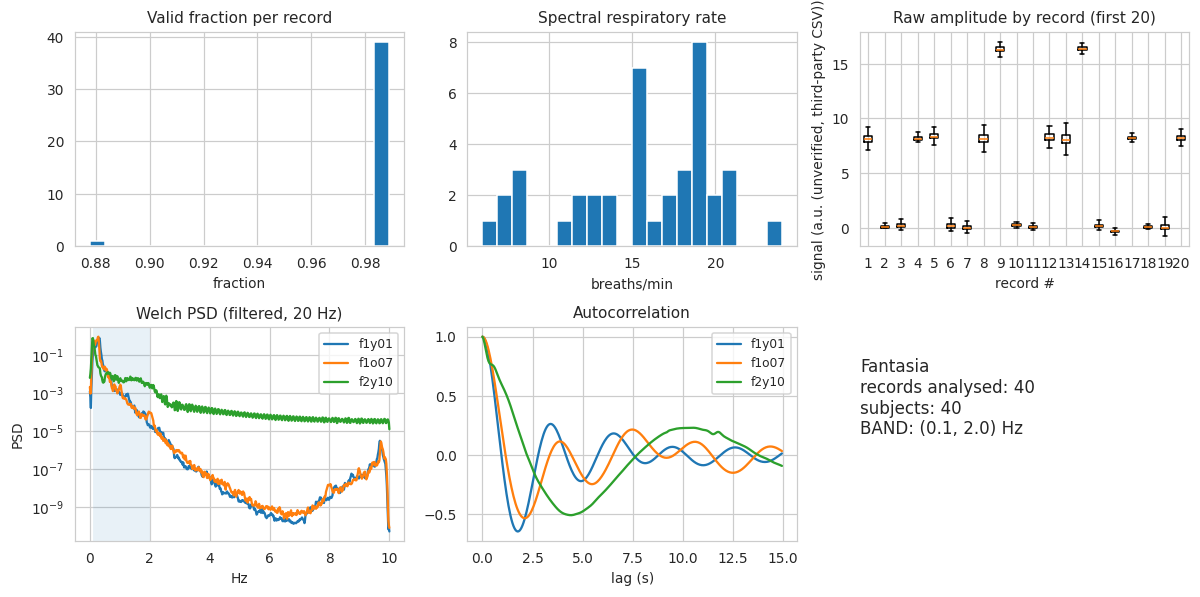

In [12]:
# ---- dataset summary, distributions, spectra, autocorrelation ----
good = QUAL[QUAL["exclude_reason"] == ""]
SUMMARY = pd.DataFrame([dict(dataset=DATASET, n_records_official=len(RECORDS), n_records_selected=int(INV["selected"].sum()), n_records_analysed=len(good),
                             n_subjects=good["subject"].nunique(), fs_native=sorted(good["fs_native"].unique().tolist()),
                             total_hours=good["duration_s"].sum() / 3600, median_duration_s=good["duration_s"].median(),
                             channel_names=sorted(INV["resp_name"].dropna().unique().tolist()), units=sorted(INV.get("resp_units", pd.Series(dtype=str)).dropna().unique().tolist()),
                             median_rr_bpm=good.get("resp_rate_bpm", pd.Series(dtype=float)).median())])
display(SUMMARY.T); save_table(SUMMARY, "dataset_characteristics", top_level=False)

reps = list(good.sort_values("valid_frac_model", ascending=False)["record"].iloc[[0, len(good) // 2, -1]]) if len(good) >= 3 else list(good["record"])
fig, ax = plt.subplots(2, 3, figsize=(11, 5.5))
ax[0, 0].hist(good["valid_frac_model"], bins=20); ax[0, 0].set(title="Valid fraction per record", xlabel="fraction")
if "resp_rate_bpm" in good: ax[0, 1].hist(good["resp_rate_bpm"].dropna(), bins=20); ax[0, 1].set(title="Spectral respiratory rate", xlabel="breaths/min")
ax[0, 2].boxplot([REC[r]["raw"][~REC[r]["bad"]] for r in good["record"].iloc[:min(len(good), 20)]], showfliers=False)
ax[0, 2].set(title="Raw amplitude by record (first 20)", xlabel="record #", ylabel=f"signal ({'/'.join(SUMMARY['units'][0])})")
for r in reps:   # representative PSD and ACF on the causally filtered, valid signal
    d = REC[r]; v = d["filt"][~d["bad"]]
    if len(v) < 200: continue
    fr, pw = sps.welch(v, fs=FS_MODEL, nperseg=min(len(v), 60 * FS_MODEL)); ax[1, 0].semilogy(fr, pw + 1e-20, label=r)
    ac = pd.Series(v).autocorr; lags = np.arange(0, min(len(v) // 2, 15 * FS_MODEL)); ax[1, 1].plot(lags / FS_MODEL, [ac(l) for l in lags[::2]] if False else [np.corrcoef(v[:-l or None][:len(v)-l], v[l:])[0, 1] if l else 1.0 for l in lags], label=r)
ax[1, 0].set(title="Welch PSD (filtered, 20 Hz)", xlabel="Hz", ylabel="PSD"); ax[1, 0].axvspan(*BAND, alpha=.1); ax[1, 0].legend()
ax[1, 1].set(title="Autocorrelation", xlabel="lag (s)"); ax[1, 1].legend()
ax[1, 2].axis("off"); ax[1, 2].text(0, .5, f"{DATASET}\nrecords analysed: {len(good)}\nsubjects: {good['subject'].nunique()}\nBAND: {BAND} Hz", fontsize=11)
fig.tight_layout(); savefig(fig, "fig02_dataset_statistics", f"{DATASET}: record-level statistics, example spectra and autocorrelation (descriptive EDA, from analysed records).")
EDA_REPS = reps

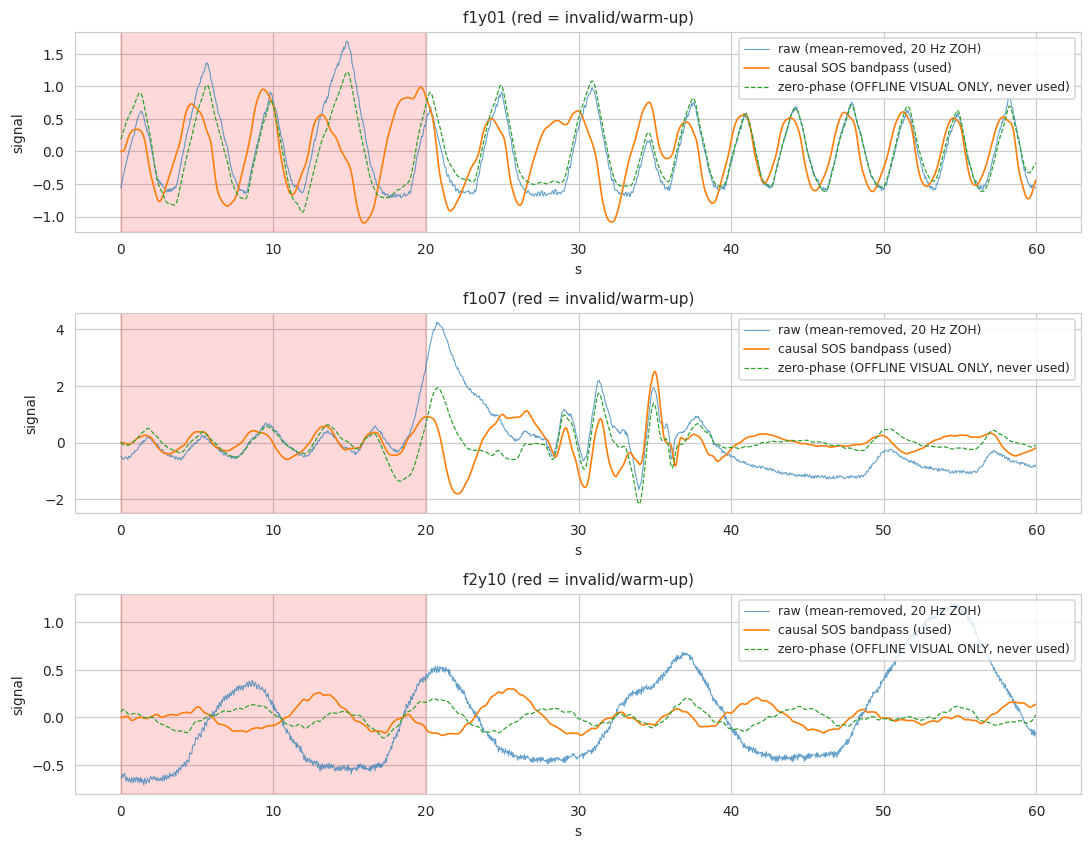

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,count,mean,std,min,25%,50%,75%,max
peak_hz,40.0,0.210833,0.115812,0.066667,0.066667,0.250000,0.316667,0.400000
power_frac_0.1-2.0Hz,40.0,0.688600,0.165829,0.181115,0.593921,0.710297,0.808879,0.942514
power_frac_0.05-1.0Hz,40.0,0.881720,0.064567,0.740405,0.828352,0.892539,0.938615,0.974890
power_frac_0.1-1.0Hz,40.0,0.684247,0.167039,0.163124,0.585912,0.707798,0.805747,0.938799
power_frac_0.1-3.0Hz,40.0,0.689799,0.165308,0.188461,0.595298,0.710839,0.809335,0.943403


Verified channel(s): ['RESP']
Cohort labels come from participant IDs (f1y/f2y = young, f1o/f2o = elderly); the CSV carries no age metadata.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


group
elderly    20
young      20
dtype: int64

Third-party CSV: RESP units are arbitrary/unverified; amplitudes are only meaningful after per-fold z-scoring.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


resp_rate_bpm           valid_frac_model             raw_std          
                 mean       std             mean       std      mean       std
group                                                                         
elderly         15.80  4.274773         0.988889  0.000000  0.328629  0.193439
young           15.25  4.821825         0.983337  0.024827  0.467819  0.281635

In [13]:
# ---- time-domain EDA: raw vs causal filter vs OFFLINE-ONLY zero-phase reference; artifacts; band validation ----
fig, axs = plt.subplots(len(EDA_REPS), 1, figsize=(10, 2.6 * max(len(EDA_REPS), 1)), squeeze=False)
for a, r in zip(axs[:, 0], EDA_REPS):
    d = REC[r]; n = min(len(d["filt"]), 60 * FS_MODEL); t = np.arange(n) / FS_MODEL
    a.plot(t, d["raw"][:n] - np.nanmean(d["raw"][:n]), lw=.7, label="raw (mean-removed, 20 Hz ZOH)", alpha=.7)
    a.plot(t, d["filt"][:n], lw=1.1, label="causal SOS bandpass (used)")
    sos20 = design_bandpass(BAND, FS_MODEL); a.plot(t, sps.sosfiltfilt(sos20, d["raw"][:n] - np.mean(d["raw"][:n])), lw=.8, ls="--", label="zero-phase (OFFLINE VISUAL ONLY, never used)")
    bad = d["bad"][:n]; s, e = runs(bad)
    for x0, x1 in zip(s, e): a.axvspan(x0 / FS_MODEL, x1 / FS_MODEL, color="red", alpha=.15)
    a.set(title=f"{r} (red = invalid/warm-up)", xlabel="s", ylabel="signal"); a.legend(loc="upper right")
fig.tight_layout(); savefig(fig, "fig03_raw_vs_filtered", f"{DATASET}: raw versus causally filtered respiratory signal; dashed line is an offline-only zero-phase reference.")

# band validation against the observed (training-agnostic, descriptive) spectrum
bv = []
for r, d in REC.items():
    v = d["raw"][~d["bad"]]
    if len(v) < 60 * FS_MODEL: continue
    fr, pw = sps.welch(v - v.mean(), fs=FS_MODEL, nperseg=min(len(v), 60 * FS_MODEL)); tot = pw[(fr > 0.02) & (fr < 5)].sum()
    row = dict(record=r, peak_hz=fr[(fr > 0.05) & (fr < 3)][np.argmax(pw[(fr > 0.05) & (fr < 3)])])
    for b in [BAND] + ALT_BANDS: row[f"power_frac_{b[0]}-{b[1]}Hz"] = pw[(fr >= b[0]) & (fr <= b[1])].sum() / tot
    bv.append(row)
BAND_CHECK = pd.DataFrame(bv); display(BAND_CHECK.describe().T)
if len(BAND_CHECK) and BAND_CHECK["peak_hz"].quantile(.95) > 0.6 * BAND[1]:
    log(f"WARNING: 95th-percentile spectral peak {BAND_CHECK['peak_hz'].quantile(.95):.2f} Hz is close to the upper cutoff {BAND[1]} Hz; consider a wider validated passband.")
save_table(BAND_CHECK, "band_validation", top_level=False)
DATASET_EDA_EXTRA()

# Section E — Signal preprocessing and unit tests
**Pipeline (per record):** forward-fill gaps ≤ `MAX_GAP_S`, flag longer gaps and flat-lines as invalid → causal 4th-order Butterworth band-pass (`sosfilt`, state carried across chunks) at the *native* rate → zero-order-hold resampling to 20 Hz (only the most recent native sample is used, so no future sample is touched; the band-limited signal makes aliasing negligible, checked below) → invalid mask dilated *forward* by the warm-up length → normalisation with **training-subject** mean/std only (fitted per fold in Section F).

**Time alignment.** Model sample *k* occurs at `t = k/20 s` from the segment start and holds native sample `floor(k·fs/20)`.

In [14]:
# ---- unit tests (preprocessing) ----
def test_causal_filter():
    fs = 125.0; sos = design_bandpass(BAND, fs); rng = np.random.RandomState(0); x = rng.randn(5000); x2 = x.copy(); x2[3000:] += 50
    y1 = sps.sosfilt(sos, x); y2 = sps.sosfilt(sos, x2)
    assert np.allclose(y1[:3000], y2[:3000]), "filter output depends on future samples"
    assert sos.ndim == 2 and sos.shape[1] == 6
def test_alias_attenuation():
    for fs in sorted(INV["fs"].dropna().unique()):
        sos = design_bandpass(BAND, fs); w, h = sps.sosfreqz(sos, worN=[FS_MODEL / 2], fs=fs)
        assert 20 * np.log10(abs(h[0]) + 1e-12) < -40, f"insufficient attenuation at {FS_MODEL/2} Hz for fs={fs}"
def test_resample_alignment():
    fs = float(INV["fs"].dropna().iloc[0]); ks = np.arange(0, 2000); nat = np.floor(ks * fs / FS_MODEL + 1e-9)
    lag = ks / FS_MODEL - nat / fs
    assert (lag > -1e-6).all() and (lag < 1 / fs + 1e-6).all(), "ZOH resample used a future sample or is mis-aligned"
def test_flatline_and_gaps():
    x = np.r_[np.random.randn(500), np.ones(400), np.random.randn(500)]
    assert flatline_mask(x, 100., 2.)[600] and not flatline_mask(x, 100., 6.).any()
def test_preprocessing_no_future():
    r = next(iter(REC.values())); row = INV[INV["record"] == r["record"]].iloc[0]
    short = preprocess_record(row, BAND, row["start_s"], min(r["dur_s"], 120.0))
    n = min(len(short["filt"]), len(r["filt"]))
    assert np.allclose(short["filt"][:n - 5 * FS_MODEL], r["filt"][:n - 5 * FS_MODEL], atol=1e-8), "filtered values changed when later data were removed"
for t in [test_causal_filter, test_alias_attenuation, test_resample_alignment, test_flatline_and_gaps, test_preprocessing_no_future]:
    t(); print("PASSED", t.__name__)
mark("unit_tests_preprocessing")

PASSED test_causal_filter
PASSED test_alias_attenuation
PASSED test_resample_alignment
PASSED test_flatline_and_gaps
PASSED test_preprocessing_no_future
[20:05:34] STATUS unit_tests_preprocessing: RUN


# Section F — Subject-level splits and causal windows
Splits are made on **subjects** before any window is extracted. Each fold has train / validation / test subjects (no overlap, asserted). Validation windows are further split *chronologically within each validation record* into `val_sel` (early stopping, hyper-parameter and controller tuning) and `val_cal` (conformal calibration), separated by a gap of `HIST+max horizon` samples.

Window at anchor *i* (last observed sample): input `z[i-99..i]` (5 s @ 20 Hz); targets `z[i+h]`, h ∈ {2,4,6,8,10} steps = {100…500} ms. A window is valid only if **every** sample from `i-99` to `i+10` is valid. Normalisation statistics (mean, std) come from the fold's training records only.

In [15]:
H_STEPS = list(HORIZONS_STEPS); H_MS = [int(round(h * 1000 / FS_MODEL)) for h in H_STEPS]; NH = len(H_STEPS); HMAX = max(H_STEPS); DT = 1.0 / FS_MODEL
HOFF = np.arange(-HIST + 1, 1); HIDX = np.array(H_STEPS)

SUBJ_DF = pd.DataFrame([dict(subject=d["subject"], group=d["group"], record=r) for r, d in REC.items()])
SUBJ_INFO = INV.groupby("subject").agg(age=("age", "first"), sex=("sex", "first"), group=("group", "first")).reset_index()
FOLDS = build_folds(sorted(SUBJ_DF["subject"].unique()), SUBJ_INFO)
manifest = []
for f in FOLDS:
    sets = [set(f["train"]), set(f["val"]), set(f["test"])]
    assert not (sets[0] & sets[1] or sets[0] & sets[2] or sets[1] & sets[2]), "subject overlap between splits"
    for role in ["train", "val", "test"]:
        for s in f[role]: manifest.append(dict(fold=f["fold"], role=role, subject=s, test_group=f["test_group"].get(s, ""),
                                                records="|".join(SUBJ_DF[SUBJ_DF.subject == s]["record"])))
SPLIT = pd.DataFrame(manifest); save_table(SPLIT, "split_manifest"); display(SPLIT.groupby(["fold", "role"]).size().unstack(fill_value=0))

def fit_norm(rec_ids):
    v = np.concatenate([REC[r]["filt"][~REC[r]["bad"]] for r in rec_ids]); return float(v.mean()), float(v.std() + 1e-12)

class WinSet:
    """Index-based windows over one concatenated normalised signal (windows are gathered lazily)."""
    def __init__(self, Z, anc, rec, loc, subj, grp, fold, sd, spans):
        self.Z, self.anc, self.rec, self.loc, self.subj, self.grp, self.fold, self.sd, self.spans = Z, anc, rec, loc, subj, grp, fold, sd, spans
    def __len__(self): return len(self.anc)
    def X(self, sl=slice(None)): return self.Z[self.anc[sl][:, None] + HOFF].astype(np.float32)
    def last(self): return self.Z[self.anc]
    def Y(self): return self.Z[self.anc[:, None] + HIDX]
    def Yh(self, h): return self.Z[self.anc + h]
    def sub(self, mask):
        m = np.asarray(mask); return WinSet(self.Z, self.anc[m], self.rec[m], self.loc[m], self.subj[m], self.grp[m], self.fold[m], self.sd[m], self.spans)

def make_windows(rec_ids, mu, sd, stride, fold_id, test_group=None, loc_range=None):
    Zs, anc_l, rec_l, loc_l, subj_l, grp_l, spans, off = [], [], [], [], [], [], [], 0
    for r in rec_ids:
        d = REC[r]; z = np.where(d["bad"], 0.0, (d["filt"] - mu) / sd).astype(np.float32); n = len(z)
        cum = np.r_[0, np.cumsum(d["bad"])]; a = np.arange(HIST - 1, n - HMAX, stride)
        a = a[(cum[a + HMAX + 1] - cum[a - HIST + 1]) == 0]                      # every sample in [i-99, i+10] valid
        if loc_range is not None: a = a[(a >= loc_range[0] * n) & (a < loc_range[1] * n)] if False else a
        Zs.append(z); anc_l.append(a + off); rec_l += [r] * len(a); loc_l.append(a); subj_l += [d["subject"]] * len(a)
        grp_l += [(test_group or {}).get(d["subject"], d["group"])] * len(a); spans.append((r, off, n)); off += n
    anc = np.concatenate(anc_l) if anc_l else np.zeros(0, int)
    return WinSet(np.concatenate(Zs), anc, np.array(rec_l), np.concatenate(loc_l) if loc_l else np.zeros(0, int), np.array(subj_l), np.array(grp_l),
                  np.full(len(anc), fold_id), np.full(len(anc), sd, dtype=np.float64), spans)

def chrono_split_val(ws: WinSet):
    """First 50% of each validation record -> val_sel, last 50% (after a gap) -> val_cal. Chronology preserved."""
    sel = np.zeros(len(ws), bool); cal = np.zeros(len(ws), bool); gap = max(HIST + HMAX, int(VAL_GAP_S * FS_MODEL))
    for r in np.unique(ws.rec):
        idx = np.flatnonzero(ws.rec == r); mid = np.median(ws.loc[idx]); sel[idx[ws.loc[idx] < mid - gap / 2]] = True; cal[idx[ws.loc[idx] > mid + gap / 2]] = True
    return ws.sub(sel), ws.sub(cal)

def build_fold_sets(f):
    tr_recs = SUBJ_DF[SUBJ_DF.subject.isin(f["train"])]["record"].tolist(); va_recs = SUBJ_DF[SUBJ_DF.subject.isin(f["val"])]["record"].tolist()
    te_recs = SUBJ_DF[SUBJ_DF.subject.isin(f["test"])]["record"].tolist()
    mu, sd = fit_norm(tr_recs)                                               # TRAIN statistics only
    tr = make_windows(tr_recs, mu, sd, TRAIN_STRIDE, f["fold"]); va = make_windows(va_recs, mu, sd, 1, f["fold"])
    te = make_windows(te_recs, mu, sd, 1, f["fold"], f["test_group"])        # stride 1: needed for continuous control simulation
    vsel, vcal = chrono_split_val(va)
    return dict(train=tr, val_sel=vsel, val_cal=vcal, test=te, mu=mu, sd=sd)

# ---- unit tests: shapes / leakage / overlap ----
def test_windows_no_leakage():
    d0 = next(iter(REC.values())); backup = (d0["filt"].copy(), d0["bad"].copy()); n = 600
    REC["__t"] = dict(filt=np.arange(n, dtype=float), bad=np.zeros(n, bool), subject="s", group="g")
    ws = make_windows(["__t"], 0.0, 1.0, 3, 0); REC.pop("__t")
    X, Y, a = ws.X(), ws.Y(), ws.anc
    assert X.shape == (len(ws), HIST) and Y.shape == (len(ws), NH)
    assert np.allclose(X[:, -1], a) and np.allclose(X[:, 0], a - HIST + 1), "input window not ending at anchor"
    assert np.allclose(Y, a[:, None] + HIDX), "targets misaligned with horizons"
    assert X.max(1).max() <= a.max() and (X.max(1) <= a).all(), "input contains future samples"
def test_invalid_excluded():
    n = 600; bad = np.zeros(n, bool); bad[300:305] = True
    REC["__t"] = dict(filt=np.random.randn(n), bad=bad, subject="s", group="g")
    ws = make_windows(["__t"], 0.0, 1.0, 1, 0); REC.pop("__t")
    for a in ws.loc: assert not bad[a - HIST + 1:a + HMAX + 1].any()
    assert np.isfinite(ws.X()).all() and np.isfinite(ws.Y()).all()
def test_norm_from_train_only():
    f = FOLDS[0]; tr = SUBJ_DF[SUBJ_DF.subject.isin(f["train"])]["record"].tolist(); mu, sd = fit_norm(tr)
    assert set(f["train"]).isdisjoint(f["test"]) and np.isfinite(mu) and sd > 0
for t in [test_windows_no_leakage, test_invalid_excluded, test_norm_from_train_only]: t(); print("PASSED", t.__name__)
FOLD_SETS = {f["fold"]: build_fold_sets(f) for f in FOLDS}
# ---- v2 integrity assertions ----
for _f in FOLDS:
    _S = FOLD_SETS[_f["fold"]]
    for _nm, _ws in _S.items():
        if not isinstance(_ws, WinSet): continue
        assert set(_ws.subj) <= set(_f[{"train": "train", "val_sel": "val", "val_cal": "val", "test": "test"}[_nm]]), f"{_nm}: windows from subjects outside the declared split"
        assert np.array_equal(_ws.Y(), np.stack([_ws.Z[_ws.anc + h] for h in H_STEPS], 1)), f"{_nm}: horizon misalignment"
        assert np.isfinite(_ws.X()).all() and np.isfinite(_ws.Y()).all()
    assert not set(_S["train"].subj) & (set(_S["val_sel"].subj) | set(_S["val_cal"].subj) | set(_S["test"].subj)), "train/eval subject overlap"
    assert not set(_S["val_sel"].subj) & set(_S["test"].subj) and not set(_S["val_cal"].subj) & set(_S["test"].subj), "validation/test subject overlap"
    assert not pd.DataFrame(dict(r=_S["test"].rec, l=_S["test"].loc)).duplicated().any(), "duplicate test windows"
    for _r in np.unique(_S["val_sel"].rec):                      # val_sel strictly BEFORE val_cal by >= VAL_GAP_S (inputs and targets cannot overlap)
        _a = _S["val_sel"].loc[_S["val_sel"].rec == _r].max(); _b = _S["val_cal"].loc[_S["val_cal"].rec == _r].min()
        assert (_b - HIST) - (_a + HMAX) >= int(VAL_GAP_S * FS_MODEL) - HIST - HMAX, f"val_sel/val_cal not separated for {_r}"
print("PASSED v2 split/leakage/horizon/duplicate assertions")
for k, v in FOLD_SETS.items(): print(f"fold {k}: train {len(v['train'])}  val_sel {len(v['val_sel'])}  val_cal {len(v['val_cal'])}  test {len(v['test'])} windows; mu={v['mu']:.4g}, sd={v['sd']:.4g}")
meta = pd.concat([pd.DataFrame(dict(fold=ws.fold, record=ws.rec, subject=ws.subj, anchor_idx=ws.loc, pred_time_s=ws.loc / FS_MODEL, split=name))
                  for fs_ in FOLD_SETS.values() for name, ws in fs_.items() if isinstance(ws, WinSet) and name != "train"]).iloc[::50]
meta.to_csv(OUT / "window_metadata_sample.csv", index=False); _WRITTEN.add(str(OUT / "window_metadata_sample.csv"))
log("Window metadata sample (every 50th window; horizons are the fixed list H_MS) saved.")

role,test,train,val
fold,,,
0,24,12,4


PASSED test_windows_no_leakage
PASSED test_invalid_excluded
PASSED test_norm_from_train_only


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


PASSED v2 split/leakage/horizon/duplicate assertions
fold 0: train 141960  val_sel 69780  val_cal 69780  test 847133 windows; mu=-6.682e-05, sd=0.297
[20:05:37] Window metadata sample (every 50th window; horizons are the fixed list H_MS) saved.


# Section G — Forecasting models
All models are multi-output (five horizons at once). Metrics applicable to **all** models: MAE, RMSE (point forecast). **Distribution-based** metrics (NLL, PICP, MPIW) apply only to models with a predictive distribution (prob. LSTM, prob. TCN, ensemble, conformal intervals).

| Model | Uncertainty |
|---|---|
| Persistence, Ridge-AR, Kalman | none (point) |
| Probabilistic LSTM / TCN | aleatoric σ (softplus + floor) |
| Deep ensemble (LSTM members) | aleatoric (mean σ²) + epistemic (variance of member means) |
| Split conformal | distribution-free intervals from validation residuals |

**Kalman baseline.** State `[position, velocity]`, constant-velocity model, process-noise `q`, measurement-noise `r` on the (normalised) signal; steady-state gain from the discrete algebraic Riccati equation. *Filtered state* at anchor *i* uses samples ≤ *i*; the *h-step predicted state* is `pos + vel·h·dt`. `(q, r)` are grid-selected on `val_sel`.

In [16]:
class LSTMNet(nn.Module):
    def __init__(s, hidden, layers, prob=True):
        super().__init__(); s.prob = prob; s.lstm = nn.LSTM(1, hidden, layers, batch_first=True); s.head = nn.Linear(hidden, NH * (2 if prob else 1))
    def forward(s, x):
        o = s.head(s.lstm(x)[0][:, -1]); mu = x[:, -1, :] + o[:, :NH]                     # predict increments from last observation
        sg = F.softplus(o[:, NH:]) + SIGMA_MIN if s.prob else None                        # positive, bounded away from 0
        return mu, sg
class CausalBlock(nn.Module):
    def __init__(s, cin, cout, k, d, p):
        super().__init__(); s.pad = (k - 1) * d; s.c1 = nn.Conv1d(cin, cout, k, dilation=d); s.c2 = nn.Conv1d(cout, cout, k, dilation=d)
        s.res = nn.Conv1d(cin, cout, 1) if cin != cout else nn.Identity(); s.dp = nn.Dropout(p)
    def forward(s, x):
        y = s.dp(F.relu(s.c1(F.pad(x, (s.pad, 0))))); y = s.dp(F.relu(s.c2(F.pad(y, (s.pad, 0))))); return F.relu(y + s.res(x))   # left-padding only: causal
class TCNNet(nn.Module):
    def __init__(s, ch, prob=True, dil=(1, 2, 4, 8, 16, 32), k=3, p=0.1):
        super().__init__(); s.prob = prob; L = []; c = 1
        for d in dil: L.append(CausalBlock(c, ch, k, d, p)); c = ch
        s.net = nn.Sequential(*L); s.head = nn.Linear(ch, NH * (2 if prob else 1))
    def forward(s, x):
        o = s.head(s.net(x.transpose(1, 2))[:, :, -1]); mu = x[:, -1, :] + o[:, :NH]
        return mu, (F.softplus(o[:, NH:]) + SIGMA_MIN if s.prob else None)
def n_params(m): return int(sum(p.numel() for p in m.parameters()))
def gauss_nll_loss(mu, sg, y): return (0.5 * torch.log(2 * math.pi * sg ** 2) + 0.5 * ((y - mu) / sg) ** 2).mean()

def train_nn(model, Xtr, Ytr, Xva, Yva, prob, name, seed):
    """Adam + ReduceLROnPlateau + early stopping + best-checkpoint on validation loss (val_sel only)."""
    set_seed(seed); model.to(DEVICE); opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WD)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=2)
    g = torch.Generator().manual_seed(seed)
    Xt = torch.from_numpy(Xtr)[:, :, None].to(DEVICE); Yt = torch.from_numpy(Ytr.astype(np.float32)).to(DEVICE)   # whole train set on the device: no DataLoader overhead
    Xv, Yv = torch.from_numpy(Xva)[:, :, None].to(DEVICE), torch.from_numpy(Yva.astype(np.float32)).to(DEVICE)
    def vloss():
        model.eval(); tot = 0.0
        with torch.no_grad():
            for a in range(0, len(Xv), 8192):
                mu, sg = model(Xv[a:a + 8192]); y = Yv[a:a + 8192]
                tot += (gauss_nll_loss(mu, sg, y) if prob else F.mse_loss(mu, y)).item() * len(y)
        return tot / len(Xv)
    ck = OUT / "models" / f"{name}.pt"; best, bad, hist, t0 = np.inf, 0, [], time.time()
    for ep in range(EPOCHS):
        model.train(); tl, nb = 0.0, 0
        perm = torch.randperm(len(Xt), generator=g).to(DEVICE)
        for b0 in range(0, len(perm), BATCH):
            ib = perm[b0:b0 + BATCH]; xb, yb = Xt[ib], Yt[ib]; opt.zero_grad(); mu, sg = model(xb)
            loss = gauss_nll_loss(mu, sg, yb) if prob else F.mse_loss(mu, yb)
            if not torch.isfinite(loss): raise FloatingPointError(f"{name}: non-finite loss at epoch {ep}")
            loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); tl += loss.item(); nb += 1
        vl = vloss(); sched.step(vl); hist.append(dict(epoch=ep, train_loss=tl / nb, val_loss=vl, lr=opt.param_groups[0]["lr"]))
        if vl < best - 1e-5: best, bad = vl, 0; torch.save(model.state_dict(), ck)
        else:
            bad += 1
            if bad >= PATIENCE: break
    model.load_state_dict(torch.load(ck, map_location=DEVICE)); model.eval()
    return pd.DataFrame(hist), time.time() - t0

def predict_nn(model, ws, bs=8192):
    model.eval(); mus, sgs = [], []
    with torch.no_grad():
        for a in range(0, len(ws), bs):
            mu, sg = model(torch.from_numpy(ws.X(slice(a, a + bs)))[:, :, None].to(DEVICE)); mus.append(mu.cpu().numpy()); sgs.append(sg.cpu().numpy() if sg is not None else None)
    return np.concatenate(mus), (np.concatenate(sgs) if sgs and sgs[0] is not None else None)

def kalman_cv(z, q, r, dt=DT):
    """Steady-state constant-velocity Kalman filter. Returns FILTERED position/velocity at every sample (uses samples <= k only)."""
    Fm = np.array([[1, dt], [0, 1.]]); Hm = np.array([[1., 0.]]); Q = q * np.array([[dt ** 3 / 3, dt ** 2 / 2], [dt ** 2 / 2, dt]])
    P = solve_discrete_are(Fm.T, Hm.T, Q, np.array([[r]])); K = (P @ Hm.T / (Hm @ P @ Hm.T + r)).ravel(); k0, k1 = float(K[0]), float(K[1])
    # steady-state filter is LTI: x[k|k] = (I-KH)F x[k-1|k-1] + K z[k]  -> vectorised with lfilter (identical to the per-sample recursion, ~100x faster)
    A = (np.eye(2) - np.outer([k0, k1], Hm[0])) @ Fm; Kc = np.array([[k0], [k1]])
    num, den = sps.ss2tf(A, Kc, A, Kc)                        # w[k]=x[k-1|k-1]: x[k|k] = A w[k] + K z[k]
    return sps.lfilter(num[0], den, z), sps.lfilter(num[1], den, z)
def kalman_forecast(ws, q, r):
    out = np.zeros((len(ws), NH))
    for rid, off, n in ws.spans:
        sel = np.flatnonzero(ws.rec == rid)
        if len(sel) == 0: continue
        pos, vel = kalman_cv(ws.Z[off:off + n].astype(float), q, r); a = ws.anc[sel] - off
        out[sel] = pos[a][:, None] + vel[a][:, None] * HIDX[None] * DT                  # predicted state = filtered + h*dt*velocity
    return out

def point_scores(y, mu): e = y - mu; return dict(mae=np.abs(e).mean(0), rmse=np.sqrt((e ** 2).mean(0)))

[20:05:38] === fitting fold 0 (12 train / 4 val / 24 test subjects)
[20:19:14] fold 0 info: {'ridge_alpha': 0.001, 'kalman_q_r': (100, 0.001), 'latency_ms_per_window': {'lstm_prob': 0.32233238220214844, 'tcn_prob': 1.838979721069336}}


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[20:19:16] STATUS forecasting_models: RUN


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,model,params,train_time_s,epochs,fold
0,lstm_member0,17802,38.603597,30,0
1,lstm_member1,17802,39.082409,30,0
2,lstm_member2,17802,40.795856,30,0
3,lstm_member3,17802,40.290850,30,0
4,lstm_member4,17802,40.434965,30,0
5,tcn_prob,34666,285.653373,30,0
6,tcn_det,34501,284.635127,30,0


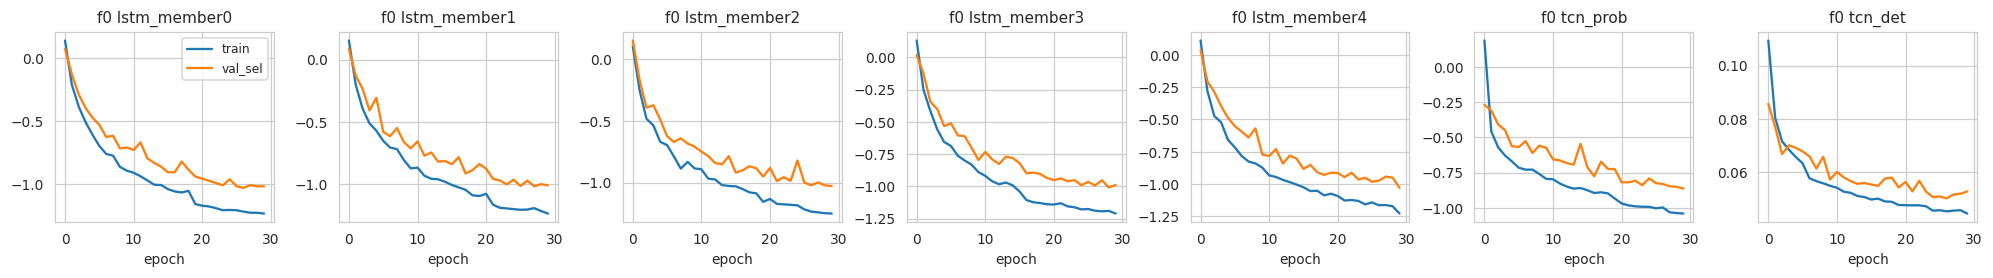

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [17]:
def conformal_q(scores, alpha):
    n = len(scores); k = int(math.ceil((n + 1) * (1 - alpha)))
    return np.inf if k > n else float(np.sort(scores)[k - 1])

def fit_fold(f):
    """Train/tune everything on TRAIN + val_sel (+val_cal for conformal) and predict val_sel / val_cal / test."""
    S = FOLD_SETS[f["fold"]]; tr, vs, vc, te = S["train"], S["val_sel"], S["val_cal"], S["test"]
    assert len(tr) > 0 and len(vs) > 0 and len(vc) > 0 and len(te) > 0, f"fold {f['fold']}: an empty split; check exclusions/limits"
    Xtr, Ytr = tr.X(), tr.Y(); sub = np.arange(0, len(vs), VAL_SUB); Xva, Yva = vs.X(slice(None))[sub], vs.Y()[sub]
    info, hist = {}, {}; P = {"val_sel": {}, "val_cal": {}, "test": {}}; ws_map = dict(val_sel=vs, val_cal=vc, test=te)
    def put(name, fn):
        for k, w in ws_map.items(): mu, sg = fn(w); P[k][name] = dict(mu=mu, sigma=sg)
    put("persistence", lambda w: (np.repeat(w.last()[:, None], NH, 1), None))
    best = (np.inf, None)                                                           # ridge-AR: alpha on val_sel only
    for a in RIDGE_ALPHAS:
        m = Ridge(alpha=a).fit(Xtr, Ytr); e = np.abs(m.predict(Xva) - Yva).mean()
        if e < best[0]: best = (e, a)
    ridge = Ridge(alpha=best[1]).fit(Xtr, Ytr); info["ridge_alpha"] = best[1]; put("ridge", lambda w: (ridge.predict(w.X()), None))
    bk = (np.inf, None)                                                             # Kalman (q, r) on val_sel only
    for q in KF_Q:
        for r in KF_R:
            e = np.abs(kalman_forecast(vs, q, r) - vs.Y()).mean()
            if e < bk[0]: bk = (e, (q, r))
    info["kalman_q_r"] = bk[1]; put("kalman", lambda w: (kalman_forecast(w, *bk[1]), None))
    # probabilistic LSTM members (member 0 == "lstm_prob"), deep ensemble
    members, pinfo = [], []
    for m_i in range(ENS_SIZE):
        net = LSTMNet(HIDDEN, LAYERS, True); h, tt = train_nn(net, Xtr, Ytr, Xva, Yva, True, f"f{f['fold']}_lstm_member{m_i}", SEED + 100 * m_i)
        members.append(net); hist[f"lstm_member{m_i}"] = h; pinfo.append(dict(model=f"lstm_member{m_i}", params=n_params(net), train_time_s=tt, epochs=len(h)))
    outs = {k: [predict_nn(m, w) for m in members] for k, w in ws_map.items()}
    for k in ws_map:
        mus = np.stack([o[0] for o in outs[k]]); sgs = np.stack([o[1] for o in outs[k]])
        P[k]["lstm_prob"] = dict(mu=mus[0], sigma=sgs[0])
        ale = (sgs ** 2).mean(0); epi = mus.var(0)                                 # law of total variance for a uniform mixture of Gaussians
        P[k]["ensemble"] = dict(mu=mus.mean(0), sigma=np.sqrt(ale + epi), ale=np.sqrt(ale), epi=np.sqrt(epi))
    tcn_p = TCNNet(TCN_CH, True); h, tt = train_nn(tcn_p, Xtr, Ytr, Xva, Yva, True, f"f{f['fold']}_tcn_prob", SEED + 7); hist["tcn_prob"] = h
    pinfo.append(dict(model="tcn_prob", params=n_params(tcn_p), train_time_s=tt, epochs=len(h)))
    tcn_d = TCNNet(TCN_CH, False); h, tt = train_nn(tcn_d, Xtr, Ytr, Xva, Yva, False, f"f{f['fold']}_tcn_det", SEED + 8); hist["tcn_det"] = h
    pinfo.append(dict(model="tcn_det", params=n_params(tcn_d), train_time_s=tt, epochs=len(h)))
    put("tcn_prob", lambda w: predict_nn(tcn_p, w)); put("tcn_det", lambda w: predict_nn(tcn_d, w))
    # latency benchmark (batch of 1, CPU/GPU as configured)
    x1 = torch.from_numpy(te.X(slice(0, 1)))[:, :, None].to(DEVICE); lat = {}
    for nm, net in [("lstm_prob", members[0]), ("tcn_prob", tcn_p)]:
        with torch.no_grad():
            for _ in range(5): net(x1)
            t0 = time.time(); [net(x1) for _ in range(100)]; lat[nm] = (time.time() - t0) / 100 * 1e3
    info["latency_ms_per_window"] = lat
    # split conformal on val_cal (separate from training and from val_sel used for early stopping)
    CONF = {}
    for nm in ["ridge", "lstm_prob", "tcn_prob", "ensemble", "persistence"]:
        yc = vc.Y(); mu_c = P["val_cal"][nm]["mu"]; res = np.abs(yc - mu_c); sg_c = P["val_cal"][nm]["sigma"]
        for alpha in [0.10, 0.05]:
            q_abs = np.array([conformal_q(res[:, j], alpha) for j in range(NH)]); CONF[(nm, "abs", alpha)] = q_abs
            if sg_c is not None: CONF[(nm, "norm", alpha)] = np.array([conformal_q(res[:, j] / sg_c[:, j], alpha) for j in range(NH)])
    for k in ws_map:
        for (nm, kind, alpha), q in CONF.items():
            mu_, sg_ = P[k][nm]["mu"], P[k][nm]["sigma"]; half = q[None] if kind == "abs" else q[None] * sg_
            P[k][nm][f"conf_{kind}_{int(alpha*100)}"] = (mu_ - half, mu_ + half)
    return dict(P=P, info=info, hist=hist, pinfo=pd.DataFrame(pinfo), sets=S, live=dict(members=members, tcn_prob=tcn_p, tcn_det=tcn_d, kalman_qr=bk[1]))

FIT = {}
for f in FOLDS:
    cache = OUT / "models" / f"fit_cache_fold{f['fold']}.pkl"            # per-fold cache: a crashed/timed-out run resumes (set RESUME_RUN) instead of retraining
    if USE_CACHE and cache.exists():
        FIT[f["fold"]] = pickle.load(cache.open("rb")); FIT[f["fold"]]["sets"] = FOLD_SETS[f["fold"]]; log(f"fold {f['fold']}: loaded cached fit {cache.name}"); continue
    log(f"=== fitting fold {f['fold']} ({len(f['train'])} train / {len(f['val'])} val / {len(f['test'])} test subjects)"); FIT[f["fold"]] = fit_fold(f)
    log(f"fold {f['fold']} info: {FIT[f['fold']]['info']}")
    with cache.open("wb") as fh: pickle.dump({k: v for k, v in FIT[f["fold"]].items() if k not in ("sets", "live")}, fh)
mark("forecasting_models")
display(pd.concat([v["pinfo"].assign(fold=k) for k, v in FIT.items()]))
for k, v in FIT.items():
    fig, axs = plt.subplots(1, len(v["hist"]), figsize=(2.6 * len(v["hist"]), 2.6), squeeze=False)
    for a, (nm, h) in zip(axs[0], v["hist"].items()): a.plot(h["train_loss"], label="train"); a.plot(h["val_loss"], label="val_sel"); a.set(title=f"f{k} {nm}", xlabel="epoch")
    axs[0, 0].legend(); fig.tight_layout(); savefig(fig, f"fig_training_curves_fold{k}", f"Training/validation loss curves (fold {k}).")

In [18]:
# ---- merge test windows across folds into one table; subject-level forecast + uncertainty metrics ----
TEST = dict(rec=np.concatenate([FIT[k]["sets"]["test"].rec for k in FIT]), subj=np.concatenate([FIT[k]["sets"]["test"].subj for k in FIT]),
            grp=np.concatenate([FIT[k]["sets"]["test"].grp for k in FIT]), fold=np.concatenate([FIT[k]["sets"]["test"].fold for k in FIT]),
            loc=np.concatenate([FIT[k]["sets"]["test"].loc for k in FIT]), sd=np.concatenate([FIT[k]["sets"]["test"].sd for k in FIT]),
            Y=np.concatenate([FIT[k]["sets"]["test"].Y() for k in FIT]), last=np.concatenate([FIT[k]["sets"]["test"].last() for k in FIT]))
MODELS = list(FIT[FOLDS[0]["fold"]]["P"]["test"].keys()); NTEST = len(TEST["subj"])
def merged(name, key):
    arrs = [FIT[k]["P"]["test"][name].get(key) for k in FIT]
    if arrs[0] is None: return None
    if isinstance(arrs[0], tuple): return (np.concatenate([a[0] for a in arrs]), np.concatenate([a[1] for a in arrs]))
    return np.concatenate(arrs)
PT = {m: {k: merged(m, k) for k in FIT[FOLDS[0]["fold"]]["P"]["test"][m].keys()} for m in MODELS}

def gnll(y, mu, sg): return 0.5 * np.log(2 * np.pi * sg ** 2) + 0.5 * ((y - mu) / sg) ** 2
Z90, Z95 = sstats.norm.ppf(0.95), sstats.norm.ppf(0.975)
def subject_metrics(model, key=None):
    P_ = PT[model]; mu, sg = P_["mu"], P_["sigma"]; rows = []
    for s in np.unique(TEST["subj"]):
        m = TEST["subj"] == s; y = TEST["Y"][m]; e = y - mu[m]; sd = TEST["sd"][m][:, None]; g = TEST["grp"][m][0]
        for j in range(NH):
            r = dict(model=model, subject=s, group=g, horizon_ms=H_MS[j], n_windows=int(m.sum()), mae=np.abs(e[:, j]).mean(), rmse=np.sqrt((e[:, j] ** 2).mean()),
                     mae_units=(np.abs(e[:, j]) * sd[:, 0]).mean(), rmse_units=np.sqrt(((e[:, j] * sd[:, 0]) ** 2).mean()))
            if sg is not None:
                s_ = sg[m][:, j]; r.update(nll=gnll(y[:, j], mu[m][:, j], s_).mean(), mean_sigma=s_.mean(), mean_sigma_units=(s_ * sd[:, 0]).mean(),
                                          picp90=(np.abs(e[:, j]) <= Z90 * s_).mean(), picp95=(np.abs(e[:, j]) <= Z95 * s_).mean(), mpiw95=(2 * Z95 * s_).mean(),
                                          spearman_sigma_abs_err=sstats.spearmanr(s_, np.abs(e[:, j]))[0] if m.sum() > 10 else np.nan)
                for kind in ["abs", "norm"]:
                    for a in [10, 5]:
                        ck = f"conf_{kind}_{a}"
                        if ck in P_ and P_[ck] is not None:
                            lo, hi = P_[ck][0][m][:, j], P_[ck][1][m][:, j]; r[f"{ck}_picp"] = ((y[:, j] >= lo) & (y[:, j] <= hi)).mean(); r[f"{ck}_mpiw"] = (hi - lo).mean()
            else:
                for a in [10, 5]:
                    ck = f"conf_abs_{a}"
                    if ck in P_ and P_[ck] is not None:
                        lo, hi = P_[ck][0][m][:, j], P_[ck][1][m][:, j]; r[f"{ck}_picp"] = ((y[:, j] >= lo) & (y[:, j] <= hi)).mean(); r[f"{ck}_mpiw"] = (hi - lo).mean()
            rows.append(r)
    return rows
FM = pd.DataFrame([r for m in MODELS for r in subject_metrics(m)])

def boot_ci(vals, B=None, seed=0, fn=np.mean):
    """Subject-level percentile bootstrap CI of fn over per-subject values."""
    v = np.asarray([x for x in vals if np.isfinite(x)]); B = B or N_BOOT
    if len(v) < 2: return (np.nan, np.nan)
    rng = np.random.RandomState(seed); b = [fn(v[rng.randint(0, len(v), len(v))]) for _ in range(B)]; return tuple(np.percentile(b, [2.5, 97.5]))
def summarize(df, by, cols):
    rows = []
    for k, g in df.groupby(by):
        k = k if isinstance(k, tuple) else (k,); r = dict(zip(by, k)); r["n_subjects"] = g["subject"].nunique()
        for c in cols:
            if c in g and g[c].notna().any(): ci = boot_ci(g[c].values); r[c] = g[c].mean(); r[c + "_lo"], r[c + "_hi"] = ci
        rows.append(r)
    return pd.DataFrame(rows)
FORECAST_TABLE = summarize(FM, ["model", "horizon_ms"], ["mae", "rmse", "mae_units", "rmse_units"]); save_table(FORECAST_TABLE, "forecast_metrics"); display(FORECAST_TABLE.round(4).head(30))
mark("forecast_evaluation")

,model,horizon_ms,n_subjects,mae,mae_lo,mae_hi,rmse,rmse_lo,rmse_hi,mae_units,mae_units_lo,mae_units_hi,rmse_units,rmse_units_lo,rmse_units_hi
0,ensemble,100,24,0.0142,0.0104,0.0192,0.0423,0.0257,0.0625,0.0042,0.0031,0.0057,0.0126,0.0076,0.0186
1,ensemble,200,24,0.0485,0.0383,0.0622,0.1065,0.0738,0.1458,0.0144,0.0114,0.0185,0.0316,0.0219,0.0433
2,ensemble,300,24,0.1009,0.0799,0.1271,0.1905,0.1430,0.2470,0.0300,0.0237,0.0377,0.0566,0.0425,0.0734
3,ensemble,400,24,0.1574,0.1237,0.1988,0.2758,0.2136,0.3505,0.0467,0.0367,0.0590,0.0819,0.0634,0.1041
4,ensemble,500,24,0.2094,0.1634,0.2672,0.3500,0.2714,0.4440,0.0622,0.0485,0.0794,0.1039,0.0806,0.1318
5,kalman,100,24,0.0312,0.0254,0.0379,0.0539,0.0421,0.0679,0.0093,0.0075,0.0113,0.0160,0.0125,0.0202
6,kalman,200,24,0.0962,0.0777,0.1173,0.1635,0.1288,0.2043,0.0286,0.0231,0.0348,0.0485,0.0382,0.0607
7,kalman,300,24,0.1863,0.1494,0.2284,0.3087,0.2458,0.3854,0.0553,0.0444,0.0678,0.0917,0.0730,0.1144
8,kalman,400,24,0.2941,0.2346,0.3611,0.4720,0.3753,0.5838,0.0873,0.0697,0.1073,0.1402,0.1115,0.1734
9,kalman,500,24,0.4157,0.3299,0.5127,0.6455,0.5164,0.7905,0.1235,0.0980,0.1523,0.1917,0.1534,0.2347


[20:19:38] STATUS forecast_evaluation: RUN


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [19]:
# ---- v2: integrity checks, VALIDATION-ONLY final model selection per horizon, latency, group sizes ----
assert not pd.DataFrame(dict(r=TEST["rec"], l=TEST["loc"])).duplicated().any(), "duplicate test predictions"
for m_ in MODELS:
    assert np.isfinite(PT[m_]["mu"]).all() and PT[m_]["mu"].shape == TEST["Y"].shape, f"{m_}: bad/misaligned predictions"
assert np.isfinite(FM[["mae", "rmse"]].to_numpy()).all(), "non-finite forecast metrics"
VAL_ROWS = []
for f in FIT:
    vs = FIT[f]["sets"]["val_sel"]; Yv = vs.Y()
    for m_, d in FIT[f]["P"]["val_sel"].items():
        for j in range(NH):
            e = Yv[:, j] - d["mu"][:, j]; VAL_ROWS.append(dict(fold=f, model=m_, horizon_ms=H_MS[j], val_mae=float(np.abs(e).mean()), val_rmse=float(np.sqrt((e ** 2).mean())), n_val_windows=len(e)))
VALSEL = pd.DataFrame(VAL_ROWS).groupby(["model", "horizon_ms"], as_index=False)[["val_mae", "val_rmse"]].mean(); save_table(VALSEL, "forecast_validation_selection")
SELECTED_MODEL = VALSEL.loc[VALSEL.groupby("horizon_ms")["val_mae"].idxmin()][["horizon_ms", "model", "val_mae"]].reset_index(drop=True); save_table(SELECTED_MODEL, "forecast_selected_model_per_horizon_validation")
SEL_TEST = SELECTED_MODEL.merge(FORECAST_TABLE, on=["horizon_ms", "model"], how="left"); save_table(SEL_TEST, "forecast_selected_model_test_results"); display(SEL_TEST.round(4))
LATENCY = pd.DataFrame([dict(fold=f, model=k, latency_ms_per_window_batch1=v) for f in FIT for k, v in FIT[f]["info"]["latency_ms_per_window"].items()]); save_table(LATENCY, "inference_latency")
GROUPN = SUBJ_DF.merge(pd.DataFrame(SPLIT).drop_duplicates("subject")[["subject", "role", "test_group"]], on="subject").groupby(["group", "role", "test_group"]).size().rename("n_subjects").reset_index()
save_table(GROUPN, "group_sizes"); display(GROUPN)
log("NOTE: young in-distribution test group is small; young-vs-elderly differences are exploratory distribution-shift descriptions, not causal or confirmatory.")
fs_flag = FORECAST_TABLE.iloc[:0]
if FS_ANOMALY:
    _s = FM[~FM.subject.isin(FS_ANOMALY)]; _t = summarize(_s, ["model", "horizon_ms"], ["mae", "rmse"]); save_table(_t, "sensitivity_excluding_fs_anomaly_subjects", top_level=False)
    log(f"Sensitivity table without sampling-rate-anomaly records {FS_ANOMALY} saved (EXPLORATORY; if such a record is in train/val it was still used for training).")
mark("validation_model_selection")

,horizon_ms,model,val_mae,n_subjects,mae,mae_lo,mae_hi,rmse,rmse_lo,rmse_hi,mae_units,mae_units_lo,mae_units_hi,rmse_units,rmse_units_lo,rmse_units_hi
0,100,ridge,0.0100,24,0.0105,0.0089,0.0125,0.0182,0.0141,0.0229,0.0031,0.0026,0.0037,0.0054,0.0042,0.0068
1,200,ridge,0.0450,24,0.0442,0.0370,0.0529,0.0764,0.0596,0.0967,0.0131,0.0110,0.0157,0.0227,0.0177,0.0287
2,300,ensemble,0.1019,24,0.1009,0.0799,0.1271,0.1905,0.1430,0.2470,0.0300,0.0237,0.0377,0.0566,0.0425,0.0734
3,400,ensemble,0.1643,24,0.1574,0.1237,0.1988,0.2758,0.2136,0.3505,0.0467,0.0367,0.0590,0.0819,0.0634,0.1041
4,500,tcn_prob,0.2217,24,0.2078,0.1652,0.2583,0.3498,0.2755,0.4378,0.0617,0.0490,0.0767,0.1039,0.0818,0.1300


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,group,role,test_group,n_subjects
0,elderly,test,shift_elderly_frozen,20
1,young,test,in_dist_young_test,4
2,young,train,,12
3,young,val,,4


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[20:19:39] NOTE: young in-distribution test group is small; young-vs-elderly differences are exploratory distribution-shift descriptions, not causal or confirmatory.
[20:19:40] Sensitivity table without sampling-rate-anomaly records ['f2y02'] saved (EXPLORATORY; if such a record is in train/val it was still used for training).
[20:19:40] STATUS validation_model_selection: RUN


# Section H — Uncertainty estimation and calibration
* **Aleatoric**: σ of the probabilistic LSTM (data noise as learned). **Epistemic**: spread of ensemble-member means. **Total** variance = mean(σ²ₘ) + Var(μₘ) (law of total variance for the equal-weight Gaussian mixture; reported as the moment-matched Gaussian).
* Intervals: Gaussian (±1.645σ for 90 %, ±1.96σ for 95 %); split-conformal absolute-residual intervals and σ-normalised conformal intervals.
* **Conformal assumptions/limitations**: coverage ≥ 1−α holds for *exchangeable* calibration/test data. Respiratory windows are strongly autocorrelated and test subjects are from a shifted population, so only approximate marginal coverage is expected; we measure rather than assume it.
* **Units**: σ is in normalised units; multiplying by the training standard deviation (`sd`, stored per window) converts to signal units (`*_units` columns). NLL in signal units = NLL_norm + log(sd).

,model,horizon_ms,n_subjects,nll,nll_lo,nll_hi,picp90,picp90_lo,picp90_hi,picp95,...,conf_norm_10_picp_hi,conf_norm_10_mpiw,conf_norm_10_mpiw_lo,conf_norm_10_mpiw_hi,conf_norm_5_picp,conf_norm_5_picp_lo,conf_norm_5_picp_hi,conf_norm_5_mpiw,conf_norm_5_mpiw_lo,conf_norm_5_mpiw_hi
0,ensemble,100,24,-2.899,-3.057,-2.705,0.945,0.934,0.955,0.968,...,0.905,0.061,0.043,0.085,0.939,0.928,0.950,0.076,0.053,0.107
1,ensemble,200,24,-1.571,-1.740,-1.370,0.925,0.914,0.935,0.955,...,0.911,0.211,0.164,0.274,0.947,0.938,0.955,0.265,0.206,0.344
2,ensemble,300,24,-0.823,-1.003,-0.615,0.920,0.911,0.929,0.954,...,0.916,0.438,0.350,0.553,0.952,0.945,0.959,0.548,0.438,0.692
3,ensemble,400,24,-0.382,-0.575,-0.168,0.923,0.913,0.932,0.956,...,0.923,0.683,0.552,0.851,0.957,0.950,0.964,0.854,0.690,1.065
4,ensemble,500,24,-0.104,-0.307,0.119,0.925,0.913,0.936,0.957,...,0.932,0.911,0.742,1.126,0.961,0.952,0.969,1.140,0.929,1.409
5,lstm_prob,100,24,-2.823,-2.993,-2.621,0.906,0.894,0.918,0.943,...,0.908,0.071,0.048,0.102,0.946,0.937,0.955,0.089,0.060,0.128
6,lstm_prob,200,24,-1.527,-1.698,-1.323,0.906,0.896,0.914,0.943,...,0.905,0.221,0.169,0.290,0.946,0.939,0.952,0.277,0.212,0.364
7,lstm_prob,300,24,-0.798,-0.978,-0.587,0.906,0.898,0.913,0.944,...,0.910,0.450,0.356,0.572,0.950,0.944,0.956,0.563,0.445,0.716
8,lstm_prob,400,24,-0.356,-0.551,-0.139,0.908,0.898,0.916,0.945,...,0.917,0.698,0.560,0.874,0.955,0.948,0.961,0.878,0.704,1.099
9,lstm_prob,500,24,-0.072,-0.275,0.155,0.909,0.897,0.920,0.946,...,0.926,0.927,0.750,1.153,0.958,0.950,0.966,1.171,0.948,1.457


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


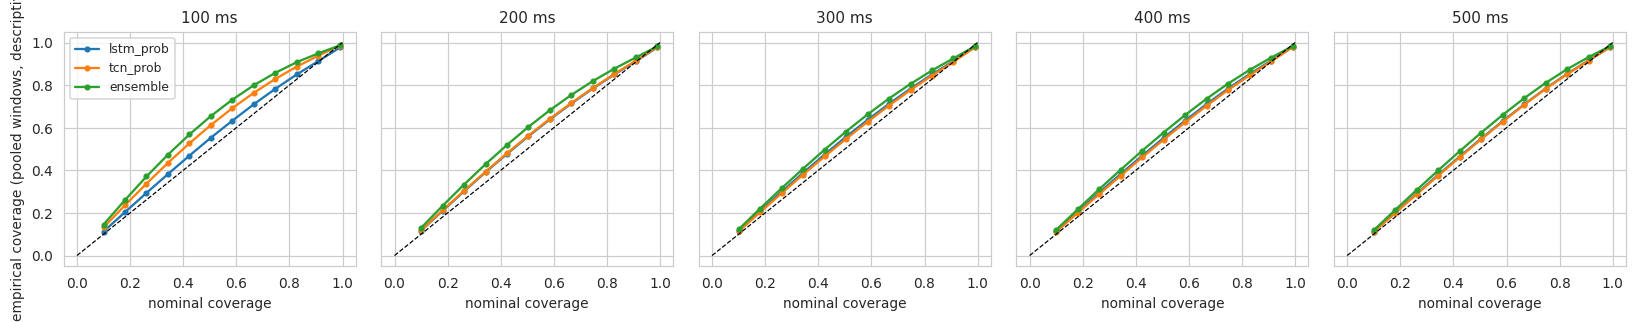

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


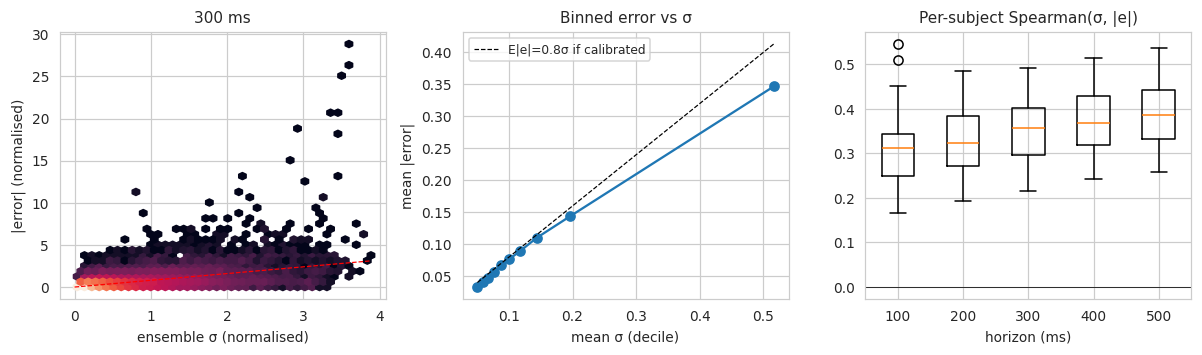

[20:19:47] STATUS uncertainty_calibration: RUN


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [20]:
UM_rows = FM[FM["model"].isin(["lstm_prob", "tcn_prob", "ensemble"])]
cols = ["nll", "picp90", "picp95", "mpiw95", "mean_sigma", "mean_sigma_units", "spearman_sigma_abs_err"] + [c for c in FM.columns if c.startswith("conf_")]
UNC_TABLE = summarize(FM[FM["model"].isin(["lstm_prob", "tcn_prob", "ensemble", "ridge", "persistence"])], ["model", "horizon_ms"], [c for c in cols if c in FM.columns])
save_table(UNC_TABLE, "uncertainty_metrics"); display(UNC_TABLE.round(3).head(30))
# coverage (reliability) curves
LEVELS = np.linspace(0.1, 0.99, 12)
def coverage_curve(model, j):
    mu, sg = PT[model]["mu"][:, j], PT[model]["sigma"][:, j]; e = np.abs(TEST["Y"][:, j] - mu); return np.array([(e <= sstats.norm.ppf(0.5 + l / 2) * sg).mean() for l in LEVELS])
fig, axs = plt.subplots(1, NH, figsize=(3 * NH, 3), sharey=True)
for j, a in enumerate(axs):
    for m in ["lstm_prob", "tcn_prob", "ensemble"]: a.plot(LEVELS, coverage_curve(m, j), marker="o", ms=3, label=m)
    a.plot([0, 1], [0, 1], "k--", lw=.8); a.set(title=f"{H_MS[j]} ms", xlabel="nominal coverage")
axs[0].set_ylabel("empirical coverage (pooled windows, descriptive)"); axs[0].legend(); fig.tight_layout()
savefig(fig, "fig07_calibration_coverage", "Empirical versus nominal central-interval coverage per forecast horizon (pooled test windows; subject-level CIs are in the tables).")
# error vs uncertainty
fig, axs = plt.subplots(1, 3, figsize=(11, 3.3)); j = NH // 2
sg = PT["ensemble"]["sigma"][:, j]; er = np.abs(TEST["Y"][:, j] - PT["ensemble"]["mu"][:, j]); hb = axs[0].hexbin(sg, er, gridsize=40, bins="log", mincnt=1)
axs[0].set(xlabel="ensemble σ (normalised)", ylabel="|error| (normalised)", title=f"{H_MS[j]} ms"); axs[0].plot([0, sg.max()], [0, 0.8 * sg.max()], "r--", lw=.8)
q = pd.qcut(sg, 10, duplicates="drop"); g = pd.DataFrame(dict(s=sg, e=er)).groupby(q, observed=True).mean(); axs[1].plot(g["s"], g["e"], "o-"); axs[1].plot(g["s"], 0.798 * g["s"], "k--", lw=.8, label="E|e|=0.8σ if calibrated")
axs[1].set(xlabel="mean σ (decile)", ylabel="mean |error|", title="Binned error vs σ"); axs[1].legend()
rho = FM[FM.model == "ensemble"].pivot(index="subject", columns="horizon_ms", values="spearman_sigma_abs_err"); axs[2].boxplot([rho[c].dropna() for c in rho.columns]); axs[2].set_xticklabels(list(rho.columns)); axs[2].axhline(0, c="k", lw=.5)
axs[2].set(title="Per-subject Spearman(σ, |e|)", xlabel="horizon (ms)"); fig.tight_layout()
savefig(fig, "fig08_uncertainty_vs_error", "Predicted uncertainty versus absolute forecast error (ensemble). Subject-level Spearman correlations test whether σ tracks error.")
mark("uncertainty_calibration")

# Section I — Distribution-shift experiment
**Frozen-model young→elderly experiment.** Normalisation, training, early stopping, calibration and controller tuning use **young subjects only**; held-out young subjects form the in-distribution test group and all elderly subjects form the *unseen* shift cohort (they are never used for fitting/selection, so describing them as unseen is valid).

Reported per evaluation group: subject-level error, mean σ, interval coverage and calibration deterioration (PICP − nominal). Whether σ *tracks* deterioration is tested by comparing group-level changes in MAE and σ and by within-group σ–|error| correlation; no direction is assumed. **This is a distribution-shift comparison, not evidence that age causes performance differences** (cohorts also differ in recording session, physiology and signal quality). The young in-distribution test group is small (n is reported everywhere); no significance claim is made from it. Normalised amplitudes are used throughout; raw amplitudes are never compared across datasets.

,model,group,horizon_ms,n_subjects,mae,mae_lo,mae_hi,rmse,rmse_lo,rmse_hi,...,spearman_sigma_abs_err,spearman_sigma_abs_err_lo,spearman_sigma_abs_err_hi,conf_norm_10_picp,conf_norm_10_picp_lo,conf_norm_10_picp_hi,conf_abs_10_picp,conf_abs_10_picp_lo,conf_abs_10_picp_hi,picp95_minus_nominal
0,ensemble,in_dist_young_test,100,4,0.021,0.012,0.037,0.104,0.038,0.176,...,0.387,0.301,0.473,0.894,0.865,0.933,0.887,0.807,0.947,0.017
1,ensemble,in_dist_young_test,200,4,0.064,0.044,0.100,0.217,0.097,0.337,...,0.381,0.293,0.469,0.898,0.872,0.932,0.887,0.811,0.945,0.004
2,ensemble,in_dist_young_test,300,4,0.129,0.094,0.195,0.331,0.175,0.488,...,0.411,0.335,0.486,0.902,0.875,0.930,0.886,0.809,0.935,0.001
3,ensemble,in_dist_young_test,400,4,0.201,0.147,0.302,0.433,0.254,0.617,...,0.432,0.359,0.506,0.906,0.882,0.929,0.886,0.807,0.930,0.000
4,ensemble,in_dist_young_test,500,4,0.271,0.197,0.407,0.522,0.326,0.770,...,0.448,0.379,0.517,0.907,0.884,0.930,0.887,0.805,0.932,-0.001
5,ensemble,shift_elderly_frozen,100,20,0.013,0.009,0.018,0.030,0.019,0.043,...,0.300,0.263,0.341,0.889,0.869,0.906,0.911,0.856,0.949,0.018
6,ensemble,shift_elderly_frozen,200,20,0.045,0.034,0.060,0.084,0.060,0.113,...,0.315,0.282,0.346,0.899,0.883,0.912,0.915,0.863,0.951,0.006
7,ensemble,shift_elderly_frozen,300,20,0.095,0.072,0.125,0.162,0.120,0.212,...,0.338,0.306,0.368,0.906,0.895,0.917,0.922,0.874,0.958,0.004
8,ensemble,shift_elderly_frozen,400,20,0.149,0.112,0.195,0.244,0.181,0.319,...,0.362,0.333,0.392,0.915,0.903,0.926,0.927,0.881,0.962,0.007
9,ensemble,shift_elderly_frozen,500,20,0.197,0.147,0.261,0.316,0.236,0.415,...,0.381,0.353,0.410,0.923,0.909,0.935,0.931,0.884,0.965,0.009


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,ref,other,horizon_ms,metric,ref_mean,other_mean,n_ref,n_other,p_raw,p_holm
0,in_dist_young_test,shift_elderly_frozen,100,mae,0.0208,0.0129,4,20,0.2101,1.0
1,in_dist_young_test,shift_elderly_frozen,100,mean_sigma,0.0358,0.0216,4,20,0.3091,1.0
2,in_dist_young_test,shift_elderly_frozen,100,picp95,0.9673,0.9678,4,20,0.6273,1.0
3,in_dist_young_test,shift_elderly_frozen,200,mae,0.0639,0.0455,4,20,0.2733,1.0
4,in_dist_young_test,shift_elderly_frozen,200,mean_sigma,0.0927,0.0673,4,20,0.3881,1.0
5,in_dist_young_test,shift_elderly_frozen,200,picp95,0.9538,0.9555,4,20,0.7369,1.0
6,in_dist_young_test,shift_elderly_frozen,300,mae,0.1290,0.0953,4,20,0.3881,1.0
7,in_dist_young_test,shift_elderly_frozen,300,mean_sigma,0.1763,0.1343,4,20,0.3881,1.0
8,in_dist_young_test,shift_elderly_frozen,300,picp95,0.9506,0.9543,4,20,0.7369,1.0
9,in_dist_young_test,shift_elderly_frozen,400,mae,0.2010,0.1487,4,20,0.3471,1.0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[20:19:52] STATUS distribution_shift: RUN


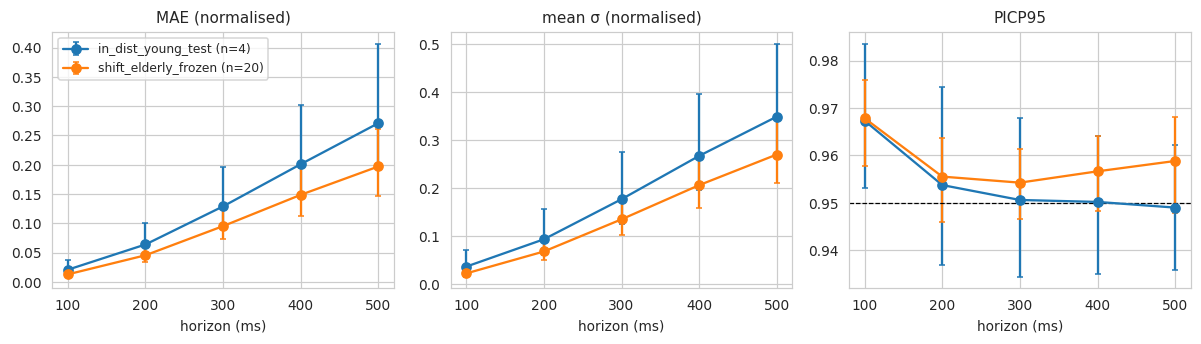

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [21]:
SHIFT = FM[FM["model"].isin(["ensemble", "lstm_prob", "persistence", "ridge"])].copy()
SHIFT_TABLE = summarize(SHIFT, ["model", "group", "horizon_ms"], ["mae", "rmse", "nll", "mean_sigma", "picp90", "picp95", "spearman_sigma_abs_err", "conf_norm_10_picp", "conf_abs_10_picp"])
SHIFT_TABLE["picp95_minus_nominal"] = SHIFT_TABLE.get("picp95", np.nan) - 0.95
save_table(SHIFT_TABLE, "distribution_shift_performance", top_level=False); display(SHIFT_TABLE[SHIFT_TABLE.model == "ensemble"].round(3))
groups = sorted(FM["group"].unique()); SHIFT_TESTS = []
if len(groups) >= 2:
    ref = groups[0]
    for g2 in groups[1:]:
        for j, hm in enumerate(H_MS):
            a = FM[(FM.model == "ensemble") & (FM.group == ref) & (FM.horizon_ms == hm)]; b = FM[(FM.model == "ensemble") & (FM.group == g2) & (FM.horizon_ms == hm)]
            for metric in ["mae", "mean_sigma", "picp95"]:
                if len(a) >= 2 and len(b) >= 2:
                    u = sstats.mannwhitneyu(a[metric], b[metric], alternative="two-sided")   # independent subjects -> unpaired
                    SHIFT_TESTS.append(dict(ref=ref, other=g2, horizon_ms=hm, metric=metric, ref_mean=a[metric].mean(), other_mean=b[metric].mean(), n_ref=len(a), n_other=len(b), p_raw=u.pvalue))
    ST = pd.DataFrame(SHIFT_TESTS)
    if len(ST): ST["p_holm"] = multipletests(ST["p_raw"], method="holm")[1]; display(ST.round(4)); save_table(ST, "distribution_shift_tests", top_level=False)
    mark("distribution_shift")
else:
    mark("distribution_shift", f"NOT RUN: only one evaluation group present ({groups}); see held-out-subject results above")
fig, axs = plt.subplots(1, 3, figsize=(11, 3.2)); E = SHIFT_TABLE[SHIFT_TABLE.model == "ensemble"]
for a, (c, t) in zip(axs, [("mae", "MAE (normalised)"), ("mean_sigma", "mean σ (normalised)"), ("picp95", "PICP95")]):
    for g in groups:
        e = E[E.group == g]; a.errorbar(e.horizon_ms, e[c], yerr=[e[c] - e[c + "_lo"], e[c + "_hi"] - e[c]], marker="o", capsize=2, label=f"{g} (n={int(e.n_subjects.iloc[0])})")
    a.set(xlabel="horizon (ms)", title=t)
axs[2].axhline(.95, c="k", ls="--", lw=.8); axs[0].legend(); fig.tight_layout()
savefig(fig, "fig14_distribution_shift", "Ensemble forecast error, mean uncertainty and 95% coverage per evaluation group (subject-level bootstrap 95% CI).")

> **Reading Section I:** group sizes are in `group_sizes.csv`. Unpaired tests with a handful of young subjects have very low power; non-significance is **not** equivalence and significance would not imply that age is the cause.

# Section J — Synthetic target motion
> **The respiratory waveform is NOT ground-truth organ displacement.** Anatomical motion can differ in amplitude, phase, nonlinearity, hysteresis and delay. The target is a *simulation assumption*:
>
> `x_target(t) = A · z(t)`, with `z` the causally filtered respiratory surrogate normalised by **training-subject** mean/std, `A = 5 mm` (primary), sensitivity `A ∈ {2, 5, 10} mm`. Units: mm. Command saturation `|u| ≤ 6A` (rarely active for z-scores).

No nonlinear mapping is used in the primary analysis (an optional one would be a labelled secondary experiment only).

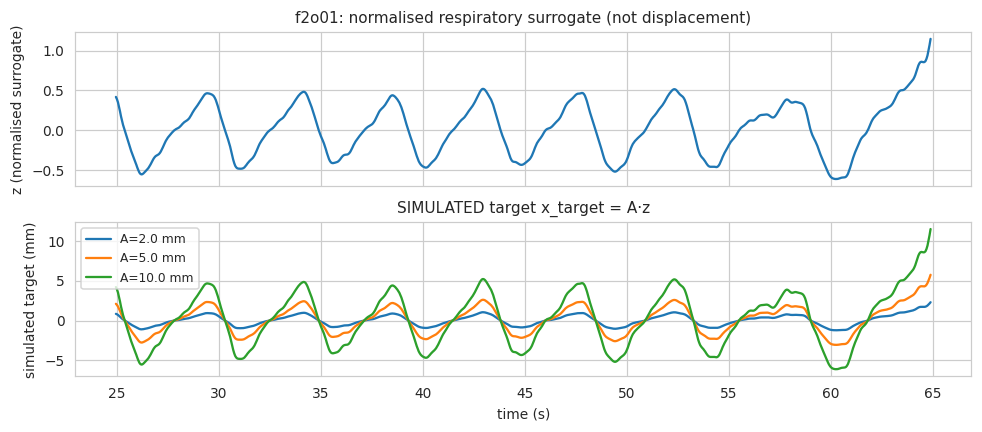

[20:19:54] STATUS synthetic_target: RUN


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [22]:
f0 = FOLDS[0]["fold"]; ws0 = FIT[f0]["sets"]["test"]; rid0 = ws0.rec[0]; sel0 = np.flatnonzero(ws0.rec == rid0)[:40 * FS_MODEL]
t0_ = ws0.loc[sel0] / FS_MODEL; z0 = ws0.last()[sel0]
fig, ax = plt.subplots(2, 1, figsize=(9, 4), sharex=True)
ax[0].plot(t0_, z0); ax[0].set(ylabel="z (normalised surrogate)", title=f"{rid0}: normalised respiratory surrogate (not displacement)")
for A in AMPLITUDES_MM: ax[1].plot(t0_, A * z0, label=f"A={A} mm")
ax[1].set(ylabel="simulated target (mm)", xlabel="time (s)", title="SIMULATED target x_target = A·z"); ax[1].legend(); fig.tight_layout()
savefig(fig, "fig_target_motion", "Normalised respiratory surrogate and the resulting SIMULATED target trajectory for three assumed amplitudes (simulation assumption, not a measurement).")
mark("synthetic_target")

# Section K — One-degree-of-freedom simulated robot
**All results below are SIMULATIONS, not physical-robot or clinical validation.**

| Symbol | Meaning | Unit | Value |
|---|---|---|---|
| `x*[k]` | simulated target position `A·z` | mm | — |
| `u[k]` | commanded position (set-point), saturated to `±6A` | mm | controller output |
| `p[k]` | actual robot position | mm | `p[0] = u[0]` per contiguous run |
| `α` | actuator lag parameter `1−exp(−dt/τ)`, τ = `TAU_ACT` | – | from config |
| `D` | **observation delay** (steps; 1 step = 50 ms): information at time k is the surrogate up to k−D | steps | 0…10 |
| `d_cmd` | **command delay** (extra transport delay of the command) | steps | `D_CMD` (default 0, so delays are not counted twice) |
| inference latency | model compute time | ms | benchmarked separately, assumed ≤ one step and **not** added to D |

Dynamics (forward-Euler/exact first-order lag, `dt = 50 ms`): `p[k+1] = p[k] + α (sat(u[k−d_cmd]) − p[k])`; tracking error `e[k] = x*[k] − p[k]`. A learned/predictive controller compensates the **observation** delay by forecasting `z[k]` from data up to `k−D` with horizon `D` (so `D = 0` ⇒ all forecast-based controllers equal the reactive one). The first `TRANSIENT_S` seconds of each contiguous run are excluded from metrics.

### Pre-declared outcomes (written before looking at test results)
* **Primary**: subject-level tracking RMSE (mm) of the uncertainty-aware blend vs reactive, predictive, fixed-blend (validation-tuned), fixed-blend-0.5 and Kalman controllers, for each delay D > 0; paired Wilcoxon + Holm correction over this family. **Primary failure-warning outcome**: ROC-AUC of ensemble σ for failure of the *predictive* controller (ε = 20 % of A = 1 mm, fixed a-priori) versus velocity baseline.
* **Exploratory**: everything else (other thresholds, amplitudes, forecasters, bands, secondary risk scores, distribution-shift tests).

PASSED test_robot_sinusoid; analytic gain 0.9543 RMSE(mm) vs delay [0,100,300,500ms]: [1.198 1.725 2.747 3.704]


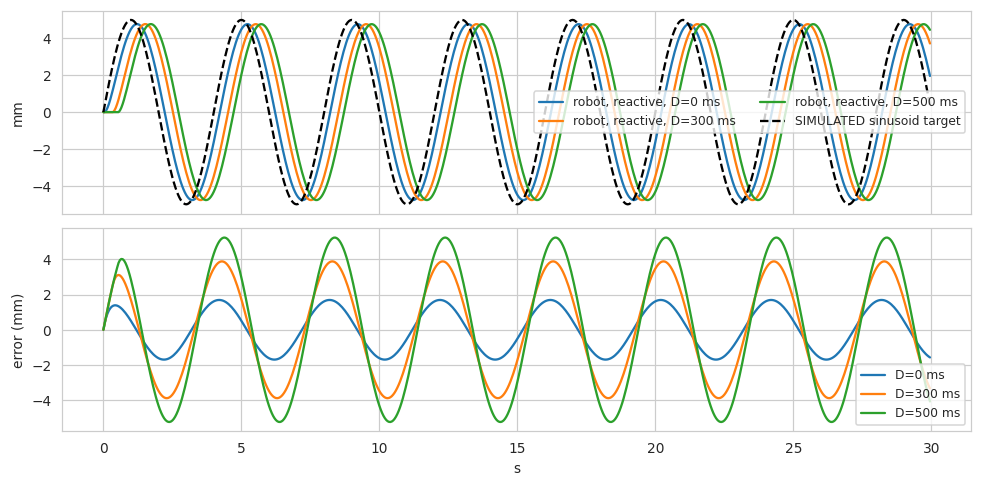

[20:19:55] STATUS robot_sinusoid_validation: RUN


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [23]:
ALPHA = 1 - math.exp(-DT / TAU_ACT); A0 = AMPLITUDE_MM; EPS_MM = EPS_FRAC * A0
CONTROLLERS = ["reactive", "predictive", "fixed_blend_0.5", "fixed_blend", "kalman", "uncertainty_aware", "ua_rate", "ua_trigger"]

def robot_response(u, alpha, d_cmd, umax, p0):
    """First-order lag with optional command delay and saturation: p[k+1]=p[k]+alpha*(sat(u[k-d_cmd])-p[k]); returns p[0..n-1]."""
    uc = np.clip(u, -umax, umax)
    if d_cmd > 0: uc = np.r_[np.full(d_cmd, uc[0]), uc][:len(u)]
    return sps.lfilter([0.0, alpha], [1.0, -(1.0 - alpha)], uc, zi=[p0])[0]

def test_robot_sinusoid():
    f, A = 0.25, 5.0; t = np.arange(0, 120, DT); x = A * np.sin(2 * np.pi * f * t); p = robot_response(x, ALPHA, 0, 1e9, x[0])
    w = 2 * np.pi * f * DT; G = abs(ALPHA * np.exp(-1j * w) / (1 - (1 - ALPHA) * np.exp(-1j * w)))
    tail = slice(len(t) // 2, None); X = np.c_[np.sin(2 * np.pi * f * t[tail]), np.cos(2 * np.pi * f * t[tail])]
    coef = np.linalg.lstsq(X, p[tail], rcond=None)[0]; amp = np.hypot(*coef)
    assert abs(amp / A - G) < 0.01, f"simulated gain {amp/A:.4f} != analytic {G:.4f}"
    errs = []
    for D in [0, 2, 6, 10]:
        xd = np.r_[np.full(D, x[0]), x][:len(x)]; pd_ = robot_response(xd, ALPHA, 0, 1e9, x[0]); errs.append(np.sqrt(np.mean((x[len(x)//2:] - pd_[len(x)//2:]) ** 2)))
    assert all(np.diff(errs) > 0), "tracking error must increase with delay"
    return G, errs
G_theory, sin_errs = test_robot_sinusoid(); print("PASSED test_robot_sinusoid; analytic gain", round(G_theory, 4), "RMSE(mm) vs delay [0,100,300,500ms]:", np.round(sin_errs, 3))
t_ = np.arange(0, 30, DT); xs_ = A0 * np.sin(2 * np.pi * 0.25 * t_)
fig, axs = plt.subplots(2, 1, figsize=(9, 4.5), sharex=True)
for D in [0, 6, 10]:
    xd = np.r_[np.full(D, xs_[0]), xs_][:len(xs_)]; p = robot_response(xd, ALPHA, 0, 6 * A0, xs_[0])
    axs[0].plot(t_, p, label=f"robot, reactive, D={D*50} ms"); axs[1].plot(t_, xs_ - p, label=f"D={D*50} ms")
axs[0].plot(t_, xs_, "k--", label="SIMULATED sinusoid target"); axs[0].set(ylabel="mm"); axs[0].legend(ncol=2); axs[1].set(ylabel="error (mm)", xlabel="s"); axs[1].legend()
fig.tight_layout(); savefig(fig, "fig_sim_validation_sinusoid", "SIMULATION validation on a sinusoidal target: robot position and tracking error for reactive control at three observation delays.")
mark("robot_sinusoid_validation")

# Section L — Controllers
All controllers output a **set-point for the target position at time k** using only information available at `k−D` (same signal availability, delay, actuator, saturation and evaluation windows):

| Controller | Set-point `u[k]/A` |
|---|---|
| reactive | `z[k−D]` |
| predictive | `μ_D` (forecast of `z[k]` from data to `k−D`, ensemble mean) |
| fixed_blend_0.5 | `0.5 μ_D + 0.5 z[k−D]` |
| fixed_blend | `w μ_D + (1−w) z[k−D]`, `w` chosen on `val_sel` per delay |
| kalman | Kalman h=D prediction `pos + vel·D·dt` (filtered state at k−D) |
| ua_rate (NEW A) | `u[k]` = slew-limited predictive mean: `u[k]=u[k−1]+clip(μ_D[k]−u[k−1], ±r_k)`, `r_k = ρ + (1−ρ)·exp(−σ_D[k]/σ₀)`; (ρ, c) with σ₀=c·median σ chosen on `val_sel` per delay (ρ=1 ≡ predictive) |
| ua_trigger (NEW B) | normal mode `u=μ_D`; if `σ_D[k] > thr_D` (validation quantile q; q=1 never triggers) → constrained mode: slew limit `RHO_C=0.05` z/step (predefined, not tuned); q chosen on `val_sel` per delay |
| uncertainty_aware | `w_σ μ_D + (1−w_σ) z[k−D]`, `w_σ = exp(−σ_D/σ₀)`, `σ₀ = c · median(σ_D on val_sel)`, `c ∈ {0.25,…,8}` selected on `val_sel` per delay |

The proposed controller sees exactly what the baselines see (σ is a by-product of the same forecaster). It is **not** assumed to be better; this is tested in Sections M and O.

In [24]:
# ======================= CONTROLLER ENGINE (v2) =======================
# v2 changes: (i) command_full() returns (command, constrained-flag); (ii) two NEW candidates ua_rate and ua_trigger;
# (iii) simulate()/run_test()/suite() accept an actuator lag `alpha` (sensitivity); (iv) per-controller validation RMSE is stored so that the
# "best controller" is chosen on VALIDATION only; (v) command variation, saturation and constrained-mode frequency are reported.
def make_bundle(ws): return dict(rec=ws.rec, loc=ws.loc, last=ws.last(), Y=ws.Y())
def fdict(split, f, name):
    if split == "val":
        P_ = FIT[f]["P"]["val_sel"][name]; return {k: P_.get(k) for k in ["mu", "sigma", "ale", "epi"]}
    m = TEST["fold"] == f; return {k: (PT[name][k][m] if PT[name].get(k) is not None else None) for k in ["mu", "sigma", "ale", "epi"]}
def bundle(split, f):
    if split == "val": return make_bundle(FIT[f]["sets"]["val_sel"])
    m = TEST["fold"] == f; return {k: TEST[k][m] for k in ["rec", "loc", "last", "Y"]}

def run_starts(B):
    N = len(B["loc"]); brk = np.r_[True, (B["rec"][1:] != B["rec"][:-1]) | (np.diff(B["loc"]) != 1)]
    st = np.flatnonzero(brk); return st, np.r_[st[1:], N]

RHO_HI = 1.0   # z-units per 50 ms step: far above any physiological slope (~0.11) => "unconstrained"
def _rate_limit_py(m, r, starts, ends):
    """u[k] = u[k-1] + clip(m[k]-u[k-1], -r[k], +r[k]) inside each contiguous run; u[run start] = m[run start]. Returns (u, binding-flag)."""
    out = np.empty_like(m); act = np.zeros(len(m), np.bool_)
    for i in range(len(starts)):
        a = starts[i]; b = ends[i]; prev = m[a]; out[a] = prev
        for k in range(a + 1, b):
            d = m[k] - prev; rk = r[k]
            if d > rk: d = rk; act[k] = True
            elif d < -rk: d = -rk; act[k] = True
            prev = prev + d; out[k] = prev
    return out, act
_rate_limit = _rate_limit_py
try:
    from numba import njit
    _nb = njit(cache=False)(_rate_limit_py); _nb(np.zeros(3), np.ones(3), np.array([0]), np.array([3])); _rate_limit = _nb
except Exception:
    pass

def command_full(ctrl, D, B, Fm, Fk, par):
    """Set-point (z units) at time k=i+D from information up to anchor i only. Returns (u_z, constrained_flag or None)."""
    last = B["last"]
    if D == 0 or ctrl == "reactive": return last, None
    c = H_STEPS.index(D); mu = Fm["mu"][:, c]
    if ctrl == "predictive": return mu, None
    if ctrl == "fixed_blend_0.5": return 0.5 * mu + 0.5 * last, None
    if ctrl == "fixed_blend": w = par["w"][D]; return w * mu + (1 - w) * last, None
    if ctrl == "kalman": return Fk[:, c], None
    if ctrl in ("uncertainty_aware", "ua_rate", "ua_trigger") and Fm["sigma"] is None: raise ValueError(ctrl + " needs a predictive sigma")
    if ctrl == "uncertainty_aware":
        w = np.exp(-Fm["sigma"][:, c] / par["sigma0"][D]); return w * mu + (1 - w) * last, None
    st, en = run_starts(B); mu64 = np.ascontiguousarray(mu, dtype=np.float64); sg = Fm["sigma"][:, c]
    if ctrl == "ua_rate":
        # A. Uncertainty-aware constrained predictive control: command = predictive mean, passed through a sigma-dependent slew-rate limit
        #    r_k = rho_min + (RHO_HI - rho_min) * exp(-sigma_k / sigma0_r);   u_k = u_{k-1} + clip(mu_k - u_{k-1}, -r_k, r_k)
        r = par["rho"][D] + (RHO_HI - par["rho"][D]) * np.exp(-sg / par["sigma0_r"][D])
        u, act = _rate_limit(mu64, np.ascontiguousarray(r, dtype=np.float64), st, en); return u, act
    if ctrl == "ua_trigger":
        # B. Uncertainty-triggered constrained mode: trig_k = 1[sigma_k > thr_D] (thr_D = validation quantile; inf = never).
        #    normal mode: u_k = mu_k ;  constrained mode (predefined): slew-rate limit RHO_C around the previous command
        trig = sg > par["thr"][D]; r = np.where(trig, RHO_C, RHO_HI).astype(np.float64)
        u, act = _rate_limit(mu64, r, st, en); return u, trig
    raise ValueError(ctrl)
def command_z(ctrl, D, B, Fm, Fk, par): return command_full(ctrl, D, B, Fm, Fk, par)[0]

def simulate(B, u_z, D, A, alpha=None):
    """Simulate contiguous runs. Anchor i carries the command for time k=i+D and the target x*(k)=A*z(i+D). Returns error/pos/target/command in mm."""
    al = ALPHA if alpha is None else alpha
    N = len(B["loc"]); tgt = A * (B["last"] if D == 0 else B["Y"][:, H_STEPS.index(D)]); u = A * u_z
    err = np.full(N, np.nan); pos = np.full(N, np.nan)
    st, en = run_starts(B)
    for a, b in zip(st, en):
        if b - a < MIN_RUN: continue
        p = robot_response(u[a:b], al, D_CMD, UMAX_FACTOR * A, np.clip(u[a], -UMAX_FACTOR * A, UMAX_FACTOR * A)); e = tgt[a:b] - p; e[:int(TRANSIENT_S * FS_MODEL)] = np.nan
        err[a:b] = e; pos[a:b] = p
    return err, pos, tgt, u

def _val_rmse(B, u_z, D): e = simulate(B, u_z, D, A0)[0]; return np.sqrt(np.nanmean(e ** 2))
def tune(fc):
    """ALL controller parameters per delay and fold, chosen on val_sel only (never on test). Ties go to the LEAST constrained setting."""
    par = {}
    for f in FIT:
        B = bundle("val", f); Fm = fdict("val", f, fc); par[f] = dict(w={}, sigma0={}, c={}, rho={}, sigma0_r={}, c_r={}, q={}, thr={})
        for D in DELAYS_STEPS:
            if D == 0: continue
            j = H_STEPS.index(D); mu = Fm["mu"][:, j]
            sc = {w: _val_rmse(B, w * mu + (1 - w) * B["last"], D) for w in W_GRID}; par[f]["w"][D] = min(sc, key=sc.get)
            if Fm["sigma"] is None: continue
            sg = Fm["sigma"][:, j]; med = float(np.median(sg))
            sc = {c: _val_rmse(B, np.exp(-sg / (c * med)) * mu + (1 - np.exp(-sg / (c * med))) * B["last"], D) for c in C_GRID}
            par[f]["c"][D] = min(sc, key=sc.get); par[f]["sigma0"][D] = par[f]["c"][D] * med
            sc = {}                                                                  # A: (c_r, rho_min) grid, least-constrained first
            st, en = run_starts(B); mu64 = np.ascontiguousarray(mu, dtype=np.float64)
            for rho in sorted(RHO_GRID, reverse=True):
                for c in C_GRID:
                    r = rho + (RHO_HI - rho) * np.exp(-sg / (c * med)); u, _ = _rate_limit(mu64, np.ascontiguousarray(r, dtype=np.float64), st, en); sc[(rho, c)] = _val_rmse(B, u, D)
            (rho_b, c_b) = min(sc, key=sc.get); par[f]["rho"][D] = rho_b; par[f]["c_r"][D] = c_b; par[f]["sigma0_r"][D] = c_b * med
            sc = {}                                                                  # B: trigger quantile, q=1 (never) first
            for q in sorted(TRIG_Q_GRID, reverse=True):
                thr = np.inf if q >= 1.0 else float(np.quantile(sg, q)); r = np.where(sg > thr, RHO_C, RHO_HI).astype(np.float64)
                u, _ = _rate_limit(mu64, r, st, en); sc[q] = (_val_rmse(B, u, D), thr)
            qb = min(sc, key=lambda k: sc[k][0]); par[f]["q"][D] = qb; par[f]["thr"][D] = sc[qb][1]
    return par
PAR = {fc: tune(fc) for fc in ["ensemble", "lstm_prob", "tcn_prob", "tcn_det", "ridge"]}
save_json({fc: {str(f): v for f, v in p.items()} for fc, p in PAR.items()}, "controller_parameters_validation_selected.json")
display(pd.DataFrame([dict(fold=f, delay_ms=D * 50, w=PAR["ensemble"][f]["w"][D], c_ua=PAR["ensemble"][f]["c"].get(D), rho_min_A=PAR["ensemble"][f]["rho"].get(D),
                           q_trigger_B=PAR["ensemble"][f]["q"].get(D)) for f in FIT for D in DELAYS_STEPS if D > 0]))

def test_rate_limiter():
    rng = np.random.RandomState(0); m = np.cumsum(rng.randn(500)) * 0.3; r = np.full(500, 0.05); st = np.array([0, 250]); en = np.array([250, 500])
    u, act = _rate_limit(m, r, st, en); d = np.abs(np.diff(u)); ok = np.ones(499, bool); ok[249] = False        # no constraint across run boundary
    assert (d[ok] <= 0.05 + 1e-12).all() and act.any() and u[0] == m[0] and u[250] == m[250]
    u1, a1 = _rate_limit(m, np.full(500, RHO_HI * 1e3), st, en); assert np.allclose(u1, m) and not a1.any(), "unconstrained limiter must equal the predictive command"
test_rate_limiter(); print("PASSED test_rate_limiter")

RUN_AUX = {}
def run_test(fc, ctrl, D, A, store=False, alpha=None):
    N = NTEST; err = np.full(N, np.nan); pos = np.full(N, np.nan); tgt = np.full(N, np.nan); u = np.full(N, np.nan); cons = np.full(N, np.nan)
    for f in FIT:
        m = TEST["fold"] == f; B = bundle("test", f); Fm = fdict("test", f, fc); Fk = PT["kalman"]["mu"][m]
        uz, cf = command_full(ctrl, D, B, Fm, Fk, PAR[fc][f]); e, p, t, uu = simulate(B, uz, D, A, alpha); err[m], pos[m], tgt[m], u[m] = e, p, t, uu
        if cf is not None: cons[m] = cf.astype(float)
    RUN_AUX["cons"] = cons if np.isfinite(cons).any() else None
    return err, pos, tgt, u

def track_metrics(e, eps):
    ok = np.isfinite(e); a = np.abs(e[ok]); fail = ok & (np.abs(np.where(ok, e, 0)) > eps); s, en = runs(fail); dur = (en - s) * DT
    return dict(mae=a.mean() if ok.any() else np.nan, rmse=np.sqrt((a ** 2).mean()) if ok.any() else np.nan, max_abs=a.max() if ok.any() else np.nan,
                p95_abs=np.percentile(a, 95) if ok.any() else np.nan, fail_count=len(s), fail_rate=fail.sum() / max(ok.sum(), 1), fail_time_s=fail.sum() * DT,
                mean_recovery_s=dur.mean() if len(s) else 0.0, n_samples=int(ok.sum()))
def suite(fc, ctrls, A, keep=None, alpha=None, extra=None):
    rows = []; subs = np.unique(TEST["subj"]); masks = {s: TEST["subj"] == s for s in subs}
    for ctrl in ctrls:
        for D in DELAYS_STEPS:
            if D == 0 and ctrl != "reactive": continue          # all forecast-based controllers coincide with reactive at D=0
            e, _, _, u = run_test(fc, ctrl, D, A, alpha=alpha); cons = RUN_AUX["cons"]
            if keep is not None: keep[(fc, ctrl, D)] = e
            for s in subs:
                m = masks[s]; ok = np.isfinite(e[m]); uu = u[m]; contig = np.diff(TEST["loc"][m]) == 1; dv = np.abs(np.diff(uu))[contig & ok[1:] & ok[:-1]]
                rows.append(dict(forecaster=fc if ctrl not in ("reactive", "kalman") else "n/a", controller=ctrl, delay_ms=D * 50, amplitude_mm=A, subject=s,
                                 group=TEST["grp"][m][0], eps_mm=EPS_FRAC * A0, cmd_var=(dv.mean() if len(dv) else np.nan),
                                 sat_rate=float((np.abs(uu[ok]) >= UMAX_FACTOR * A - 1e-9).mean()) if ok.any() else np.nan,
                                 cons_rate=(float(np.nanmean(cons[m][ok])) if (cons is not None and ok.any()) else np.nan), **(extra or {}), **track_metrics(e[m], EPS_FRAC * A0)))
    return rows
ERR = {}
TM = pd.DataFrame(suite("ensemble", CONTROLLERS, A0, keep=ERR))
assert np.isfinite(TM[["mae", "rmse"]].to_numpy()).all(), "non-finite tracking metrics"
save_table(TM, "tracking_metrics"); mark("controllers_primary")

# ---- validation-only controller ranking (used for the final 'selected controller per delay'; test results are NOT used for selection) ----
VAL_CTRL = []
for D in DELAYS_STEPS:
    for ctrl in CONTROLLERS:
        if D == 0 and ctrl != "reactive": continue
        es = []
        for f in FIT:
            B = bundle("val", f); Fm = fdict("val", f, "ensemble"); Fk = FIT[f]["P"]["val_sel"]["kalman"]["mu"]
            es.append(simulate(B, command_full(ctrl, D, B, Fm, Fk, PAR["ensemble"][f])[0], D, A0)[0])
        e = np.concatenate(es); VAL_CTRL.append(dict(controller=ctrl, delay_ms=D * 50, val_rmse=float(np.sqrt(np.nanmean(e ** 2))), val_mae=float(np.nanmean(np.abs(e)))))
VAL_CTRL = pd.DataFrame(VAL_CTRL); save_table(VAL_CTRL, "controller_validation_selection")
SEL_CTRL = VAL_CTRL.loc[VAL_CTRL.groupby("delay_ms")["val_rmse"].idxmin()].reset_index(drop=True); save_table(SEL_CTRL, "controller_selected_on_validation"); display(SEL_CTRL.round(4))

,fold,delay_ms,w,c_ua,rho_min_A,q_trigger_B
0,0,100,1.0,8,1.0,1.0
1,0,200,1.0,8,1.0,1.0
2,0,300,1.0,8,1.0,1.0
3,0,400,1.0,8,1.0,1.0
4,0,500,1.0,8,1.0,1.0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


PASSED test_rate_limiter
[20:20:10] STATUS controllers_primary: RUN


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,controller,delay_ms,val_rmse,val_mae
0,reactive,0,2.1088,1.5967
1,predictive,100,2.1435,1.6107
2,fixed_blend,200,2.2304,1.6516
3,predictive,300,2.4096,1.7377
4,fixed_blend,400,2.6563,1.8671
5,predictive,500,2.9014,1.9982


In [25]:
# ---- sanity: a PERFECT forecaster must reproduce delay-free tracking (checks alignment end-to-end) ----
def test_oracle_alignment():
    f = FOLDS[0]["fold"]; B = bundle("test", f); D = 6; c = H_STEPS.index(D)
    e_or = simulate(B, B["Y"][:, c], D, A0)[0]; e_0 = simulate(B, B["last"], 0, A0)[0]
    # oracle command at anchor i is z(i+D); target is z(i+D) -> identical to a delay-free reactive controller evaluated at time i+D
    assert np.isclose(np.sqrt(np.nanmean(e_or ** 2)), np.sqrt(np.nanmean(e_0 ** 2)), rtol=0.03), "oracle forecast at delay D must match delay-free reactive tracking (alignment check; replaces the v1 tautology)"
    assert np.nanmean(np.abs(e_or)) < np.nanmean(np.abs(simulate(B, B["last"], D, A0)[0])), "oracle forecast must beat delayed reactive control"
test_oracle_alignment(); print("PASSED test_oracle_alignment")

M_ = TM[TM.amplitude_mm == A0]
T_SUM = summarize(M_, ["controller", "delay_ms"], ["mae", "rmse", "max_abs", "p95_abs", "fail_count", "fail_rate", "fail_time_s", "mean_recovery_s", "cmd_var", "sat_rate", "cons_rate"])
save_table(T_SUM, "tracking_summary_by_controller_delay", top_level=False); display(T_SUM.pivot(index="delay_ms", columns="controller", values="rmse").round(3))

PASSED test_oracle_alignment


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


controller,fixed_blend,fixed_blend_0.5,kalman,predictive,reactive,ua_rate,ua_trigger,uncertainty_aware
delay_ms,,,,,,,,
0,NaN,NaN,NaN,NaN,1.642,NaN,NaN,NaN
100,1.689,2.002,1.695,1.689,2.321,1.702,1.702,1.862
200,1.789,2.359,1.901,1.789,2.965,1.803,1.803,2.073
300,1.973,2.722,2.286,1.973,3.562,1.986,1.986,2.305
400,2.207,3.075,2.814,2.207,4.113,2.218,2.218,2.558
500,2.428,3.393,3.444,2.428,4.618,2.437,2.437,2.792


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


# Section M — Tracking metrics and plots
Metrics are computed **per subject** (windows from one subject are never treated as independent subjects) and then averaged across subjects with a subject-level bootstrap 95 % CI.

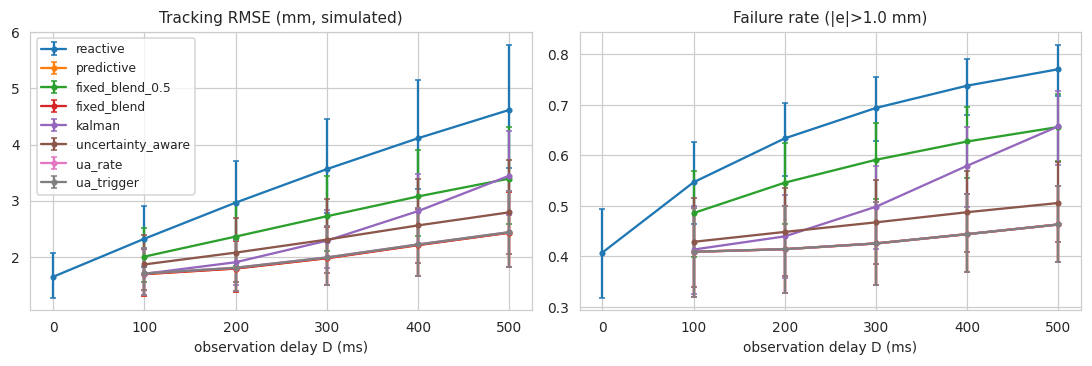

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


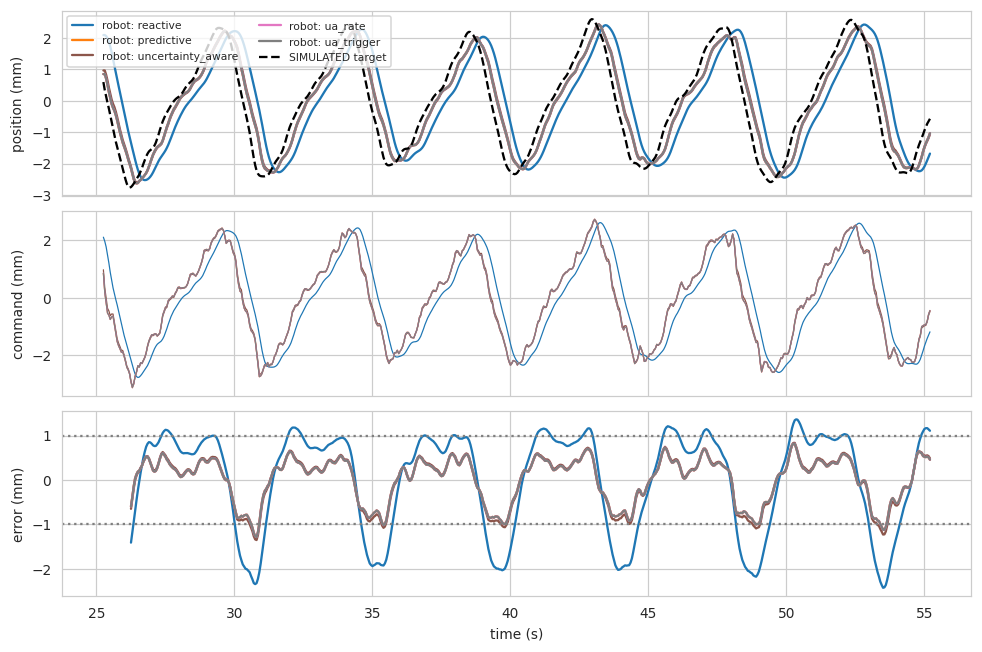

[20:20:21] STATUS tracking_metrics: RUN


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [26]:
colors = dict(zip(CONTROLLERS, sns.color_palette("tab10", len(CONTROLLERS))))
fig, axs = plt.subplots(1, 2, figsize=(10, 3.4))
for c in CONTROLLERS:
    s = T_SUM[T_SUM.controller == c].sort_values("delay_ms")
    if c != "reactive": s = s[s.delay_ms > 0]
    for a, (m, t) in zip(axs, [("rmse", "Tracking RMSE (mm, simulated)"), ("fail_rate", f"Failure rate (|e|>{EPS_MM:.1f} mm)")]):
        a.errorbar(s.delay_ms, s[m], yerr=[s[m] - s[m + "_lo"], s[m + "_hi"] - s[m]], marker="o", ms=3, capsize=2, label=c, color=colors[c]); a.set(xlabel="observation delay D (ms)", title=t)
axs[0].legend(); fig.tight_layout(); savefig(fig, "fig10_11_error_failure_vs_latency", "SIMULATED tracking RMSE (left) and failure rate (right) versus observation delay, subject-level mean with 95% bootstrap CI.")
D_PLOT = 6; f_ = FOLDS[0]["fold"]; m_ = np.flatnonzero((TEST["fold"] == f_) & (TEST["rec"] == TEST["rec"][0]))[:30 * FS_MODEL]
fig, axs = plt.subplots(3, 1, figsize=(9, 6), sharex=True); tt = TEST["loc"][m_] / FS_MODEL + D_PLOT * DT
for c in ["reactive", "predictive", "uncertainty_aware", "ua_rate", "ua_trigger"]:
    e, p, tg, u = run_test("ensemble", c, D_PLOT, A0); axs[0].plot(tt, p[m_], label=f"robot: {c}", color=colors[c]); axs[1].plot(tt, u[m_], color=colors[c], lw=.8, label=f"command: {c}"); axs[2].plot(tt, e[m_], color=colors[c], label=c)
axs[0].plot(tt, tg[m_], "k--", label="SIMULATED target"); axs[2].axhline(EPS_MM, c="gray", ls=":"); axs[2].axhline(-EPS_MM, c="gray", ls=":")
axs[0].set(ylabel="position (mm)"); axs[1].set(ylabel="command (mm)"); axs[2].set(ylabel="error (mm)", xlabel="time (s)"); axs[0].legend(ncol=2, fontsize=7); fig.tight_layout()
savefig(fig, "fig09_tracking_trajectories", f"SIMULATED target, robot position, commands and tracking error at D={D_PLOT*50} ms (A={A0} mm); dotted lines mark the failure threshold.")
mark("tracking_metrics")

# Section N — Tracking-failure prediction
* **Failure**: `failure(t+τ) = 1[|e(t+τ)| > ε]`, with the error timestamp `t+τ`, where `t` is the **prediction timestamp** (anchor: last observed sample) and `τ = D` is the forecast horizon equal to the observation delay. The robot state at `t+τ` depends only on commands issued before `t+τ`, which use data up to `t−1+...` — features below use samples **≤ t** only.
* **ε** = `EPS_FRAC · A` = 20 % of the assumed amplitude (1 mm for A = 5 mm), declared a priori on engineering grounds (not tuned); alternatives (10 %, 30 %) are reported as sensitivity.
* **Risk scores at `t`**: ensemble σ (total / aleatoric / epistemic), |respiratory velocity|, |last causally-available forecast error| (`|z[t] − μ_h[t−h]|`), forecast magnitude `|μ_h − z[t]|`.
* Operating thresholds (max-F1) and Platt probability maps are fitted on `val_sel` and applied unchanged to test. Bootstrap resamples **subjects**, not windows.

In [27]:
def shifted(arr, k, B):
    """arr[j-k] if windows j and j-k are in the same contiguous run, else NaN (strictly past information)."""
    out = np.full(len(arr), np.nan); j = np.arange(k, len(arr))
    ok = (B["rec"][j] == B["rec"][j - k]) & (B["loc"][j] - B["loc"][j - k] == k); out[j[ok]] = arr[j[ok] - k]; return out
def risk_scores(B, Fm, D):
    c = H_STEPS.index(D); last, mu = B["last"], Fm["mu"][:, c]
    return {"sigma_total": Fm["sigma"][:, c], "sigma_aleatoric": Fm["ale"][:, c], "sigma_epistemic": Fm["epi"][:, c],
            "abs_velocity": np.abs(last - shifted(last, 1, B)) / DT, "last_forecast_error": np.abs(last - shifted(mu, D, B)), "forecast_magnitude": np.abs(mu - last)}
def gather(split, ctrl, D, eps):
    """Scores/labels/subject ids for one split ('val' simulated with tuned params, or 'test')."""
    S, L, SU = {}, [], []
    if split == "test":
        e = ERR[("ensemble", ctrl, D)]; sc = {k: [] for k in ["sigma_total", "sigma_aleatoric", "sigma_epistemic", "abs_velocity", "last_forecast_error", "forecast_magnitude"]}
        for f in FIT:
            m = TEST["fold"] == f; B = bundle("test", f); r = risk_scores(B, fdict("test", f, "ensemble"), D)
            for k in sc: sc[k].append(r[k])
        S = {k: np.concatenate(v) for k, v in sc.items()}; err = e; SU = TEST["subj"]
        order = np.concatenate([np.flatnonzero(TEST["fold"] == f) for f in FIT]); inv = np.empty_like(order); inv[order] = np.arange(len(order)); S = {k: v[inv] for k, v in S.items()}
    else:
        sc = {}; errs, sus = [], []
        for f in FIT:
            B = bundle("val", f); Fm = fdict("val", f, "ensemble"); Fk = FIT[f]["P"]["val_sel"]["kalman"]["mu"]
            errs.append(simulate(B, command_z(ctrl, D, B, Fm, Fk, PAR["ensemble"][f]), D, A0)[0]); sus.append(FIT[f]["sets"]["val_sel"].subj)
            for k, v in risk_scores(B, Fm, D).items(): sc.setdefault(k, []).append(v)
        S = {k: np.concatenate(v) for k, v in sc.items()}; err = np.concatenate(errs); SU = np.concatenate(sus)
    ok = np.isfinite(err); y = (np.abs(np.where(ok, err, 0)) > eps).astype(int)
    for k in S: ok &= np.isfinite(S[k])
    sel = np.flatnonzero(ok)[::FAIL_STRIDE]      # thin the (20 Hz, highly redundant) windows; inference is still subject-level (documented in limitations)
    return {k: v[sel] for k, v in S.items()}, y[sel], np.asarray(SU)[sel]

def boot_auc(S, y, su, fn, B_=None, seed=1):
    subs = np.unique(su); idx = {s: np.flatnonzero(su == s) for s in subs}; rng = np.random.RandomState(seed); out = []
    for _ in range(B_ or N_BOOT_FAIL):
        pick = rng.choice(subs, len(subs)); ii = np.concatenate([idx[s] for s in pick]); ii = ii[::BOOT_THIN]      # thin resampled windows (cost); resampling unit is still the subject
        if len(np.unique(y[ii])) == 2: out.append(fn(y[ii], S[ii]))
    return tuple(np.percentile(out, [2.5, 97.5])) if len(out) >= 10 else (np.nan, np.nan)

FP_ROWS, CURVES = [], {}
def failure_eval(ctrl, D, eps_frac, full=True):
    eps = eps_frac * A0; Sv, yv, _ = gather("val", ctrl, D, eps); St, yt, su = gather("test", ctrl, D, eps)
    if len(np.unique(yv)) < 2 or len(np.unique(yt)) < 2:
        return [dict(controller=ctrl, delay_ms=D * 50, eps_frac=eps_frac, score="ALL", note=f"NOT RUN: single-class labels (val prevalence {yv.mean():.3f}, test {yt.mean():.3f})")]
    rows = []
    _sv = [Sv["abs_velocity"].std() + 1e-12, Sv["sigma_total"].std() + 1e-12]       # scaling from VALIDATION only
    _lr = LogisticRegression(max_iter=1000).fit(np.c_[Sv["abs_velocity"] / _sv[0], Sv["sigma_total"] / _sv[1]], yv)
    for _S_ in (Sv, St): _S_["vel_plus_sigma"] = _lr.decision_function(np.c_[_S_["abs_velocity"] / _sv[0], _S_["sigma_total"] / _sv[1]])
    for k in St:
        s_t, s_v = St[k], Sv[k]; auc = roc_auc_score(yt, s_t); ap = average_precision_score(yt, s_t)
        r = dict(controller=ctrl, delay_ms=D * 50, eps_frac=eps_frac, eps_mm=eps, score=k, auc=auc, auprc=ap, prevalence_test=yt.mean(), prevalence_val=yv.mean(), n_windows=len(yt), n_subjects=len(np.unique(su)))
        if full:
            if k in BOOT_SCORES and ctrl in BOOT_CTRLS: r["auc_lo"], r["auc_hi"] = boot_auc(s_t, yt, su, roc_auc_score); r["auprc_lo"], r["auprc_hi"] = boot_auc(s_t, yt, su, average_precision_score)
            pa = [roc_auc_score(yt[su == s], s_t[su == s]) for s in np.unique(su) if len(np.unique(yt[su == s])) == 2]; r["subject_auc_mean"] = np.mean(pa) if pa else np.nan; r["subject_auc_n"] = len(pa)
            pr, rc, th = precision_recall_curve(yv, s_v); f1 = 2 * pr * rc / np.maximum(pr + rc, 1e-12); thr = th[np.argmax(f1[:-1])]       # operating point from VALIDATION
            pred = s_t >= thr; tn, fp, fn, tp = confusion_matrix(yt, pred, labels=[0, 1]).ravel()
            r.update(threshold=thr, precision=tp / max(tp + fp, 1), recall=tp / max(tp + fn, 1), f1=2 * tp / max(2 * tp + fp + fn, 1), tp=tp, fp=fp, fn=fn, tn=tn)
            lr = LogisticRegression().fit(np.c_[s_v], yv); pt = lr.predict_proba(np.c_[s_t])[:, 1]; r["brier"] = brier_score_loss(yt, pt); r["brier_baseline_prevalence"] = brier_score_loss(yt, np.full(len(yt), yv.mean()))
            if D == 6 and eps_frac == EPS_FRAC:
                fpr, tpr, _ = roc_curve(yt, s_t); p_, r_, _ = precision_recall_curve(yt, s_t); CURVES[(ctrl, k)] = dict(fpr=fpr, tpr=tpr, prec=p_, rec=r_, auc=auc, ap=ap, prev=yt.mean())
                fr_, mp_ = np.histogram(pt, bins=np.quantile(pt, np.linspace(0, 1, 9)))[1], None
                CURVES[(ctrl, k, "rel")] = pd.DataFrame(dict(p=pt, y=yt)).groupby(pd.qcut(pt, 8, duplicates="drop"), observed=True).mean()
        rows.append(r)
    return rows
for ctrl in FAIL_CTRLS:
    for D in [d for d in DELAYS_STEPS if d > 0]: FP_ROWS += failure_eval(ctrl, D, EPS_FRAC)
FP = pd.DataFrame(FP_ROWS); save_table(FP, "failure_prediction_metrics"); mark("failure_prediction")
display(FP[(FP.controller == "predictive")].pivot_table(index="delay_ms", columns="score", values="auc").round(3))
SENS = []
for fr_ in EPS_SENS:
    for D in [2, 6, 10]:
        for r in failure_eval("predictive", D, fr_, full=False): SENS.append(r)
SENS = pd.DataFrame(SENS); save_table(SENS, "failure_threshold_sensitivity", top_level=False); display(SENS[SENS.score.isin(["sigma_total", "abs_velocity"])].pivot_table(index=["eps_frac", "delay_ms"], columns="score", values="auc").round(3))

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datet

[20:24:31] STATUS failure_prediction: RUN


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


score,abs_velocity,forecast_magnitude,last_forecast_error,sigma_aleatoric,sigma_epistemic,sigma_total,vel_plus_sigma
delay_ms,,,,,,,
100,0.975,0.933,0.632,0.739,0.693,0.742,0.976
200,0.949,0.947,0.653,0.728,0.697,0.730,0.951
300,0.863,0.899,0.674,0.727,0.702,0.728,0.877
400,0.779,0.840,0.674,0.732,0.696,0.732,0.817
500,0.712,0.788,0.654,0.736,0.693,0.736,0.776


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datet

score              abs_velocity  sigma_total
eps_frac delay_ms                           
0.1      100              0.957        0.695
         300              0.838        0.694
         500              0.694        0.707
0.2      100              0.975        0.742
         300              0.863        0.728
         500              0.712        0.736
0.3      100              0.983        0.782
         300              0.883        0.769
         500              0.732        0.776

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


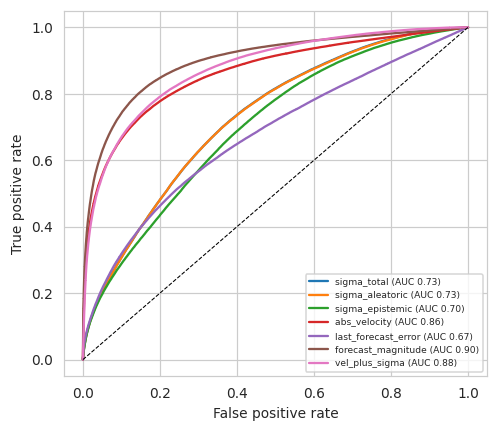

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/tmp/ipykernel_23/3048427523.py:11: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  ax.set(xlabel=xl, ylabel=yl); ax.legend(fontsize=6); fig.tight_layout(); savefig(fig, fig_name, cap)
/tmp/ipykernel_23/87197551.py:45: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  p = OUT / "figures" / f"{name}.{ext}"; _guard(p); fig.savefig(p, dpi=300, bbox_inches="tight")
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/

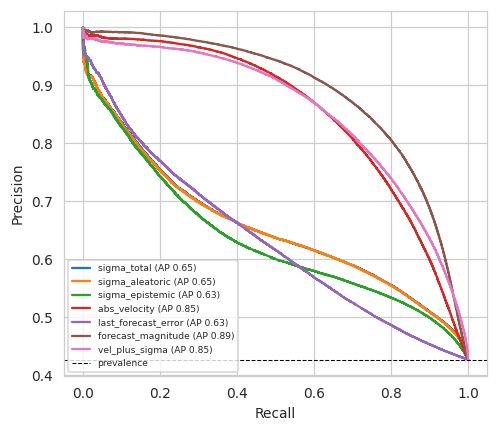

[20:25:15] STATUS failure_curves: RUN


In [28]:
for kind, fig_name, xl, yl, cap in [("roc", "fig12_roc_failure", "False positive rate", "True positive rate", "ROC curves for predicting future tracking failure (predictive controller, D=300 ms)."),
                                      ("pr", "fig13_pr_failure", "Recall", "Precision", "Precision–recall curves for predicting future tracking failure (predictive controller, D=300 ms).")]:
    fig, ax = plt.subplots(figsize=(4.6, 4))
    for k in ["sigma_total", "sigma_aleatoric", "sigma_epistemic", "abs_velocity", "last_forecast_error", "forecast_magnitude", "vel_plus_sigma"]:
        c = CURVES.get(("predictive", k))
        if c is None: continue
        if kind == "roc": ax.plot(c["fpr"], c["tpr"], label=f"{k} (AUC {c['auc']:.2f})")
        else: ax.plot(c["rec"], c["prec"], label=f"{k} (AP {c['ap']:.2f})")
    if kind == "roc": ax.plot([0, 1], [0, 1], "k--", lw=.7)
    elif ("predictive", "sigma_total") in CURVES: ax.axhline(CURVES[("predictive", "sigma_total")]["prev"], c="k", ls="--", lw=.7, label="prevalence")
    ax.set(xlabel=xl, ylabel=yl); ax.legend(fontsize=6); fig.tight_layout(); savefig(fig, fig_name, cap)
mark("failure_curves")

# Section O — Statistical analysis
Subject is the unit of analysis. For each delay D > 0 and each comparator, paired per-subject differences in tracking RMSE (`UA − comparator`; negative favours the uncertainty-aware blend) are tested with the **Wilcoxon signed-rank test** (two-sided; only if n ≥ 6 so that p < 0.05 is attainable), with the matched-pairs rank-biserial effect size, mean difference and subject-level bootstrap 95 % CI. **Holm correction** is applied across the declared primary family. With few subjects, results are low-powered; non-significance is *not* evidence of equivalence.

In [29]:
def paired(df, a, b, metric="rmse"):
    pv = df.pivot_table(index="subject", columns="controller", values=metric); d = (pv[a] - pv[b]).dropna(); n = len(d)
    r = dict(a=a, b=b, n=n, mean_diff=d.mean() if n else np.nan, median_diff=d.median() if n else np.nan, cohens_dz=(d.mean() / d.std(ddof=1) if n > 2 and d.std(ddof=1) > 0 else np.nan))
    r["ci_lo"], r["ci_hi"] = boot_ci(d.values) if n >= 2 else (np.nan, np.nan)
    nz = d[d != 0]
    if n >= 6 and len(nz) >= 1:
        w = sstats.wilcoxon(nz, alternative="two-sided"); rk = sstats.rankdata(np.abs(nz)); r["p_raw"] = w.pvalue; r["effect_rank_biserial"] = (rk[nz > 0].sum() - rk[nz < 0].sum()) / rk.sum()
    else: r["p_raw"] = np.nan; r["effect_rank_biserial"] = np.nan; r["note"] = "n<6: Wilcoxon not applicable"
    return r
rows = []
for D in [d * 50 for d in DELAYS_STEPS if d > 0]:
    sub = TM[(TM.delay_ms == D) & (TM.amplitude_mm == A0)]
    for other in ["reactive", "predictive", "fixed_blend", "fixed_blend_0.5", "kalman"]: rows.append(dict(delay_ms=D, family="primary", **paired(sub, "uncertainty_aware", other)))
    rows.append(dict(delay_ms=D, family="exploratory", **paired(sub, "predictive", "reactive")))
    rows.append(dict(delay_ms=D, family="exploratory", **paired(sub, "fixed_blend", "predictive")))
    for newc in ["ua_rate", "ua_trigger", "uncertainty_aware"]:
        for other in ["predictive", "reactive"]: rows.append(dict(delay_ms=D, family="primary_new", **paired(sub, newc, other)))   # negative mean_diff favours the uncertainty-aware candidate
if TM["group"].nunique() > 1:      # per-cohort analyses (e.g. in-distribution vs shifted subjects); each cohort is its own Holm family
    for g in sorted(TM["group"].unique()):
        for D in [d * 50 for d in DELAYS_STEPS if d > 0]:
            sub = TM[(TM.delay_ms == D) & (TM.amplitude_mm == A0) & (TM.group == g)]
            for other in ["reactive", "predictive", "fixed_blend", "kalman"]: rows.append(dict(delay_ms=D, family=f"group:{g}", **paired(sub, "uncertainty_aware", other)))
            for newc in ["ua_rate", "ua_trigger"]: rows.append(dict(delay_ms=D, family=f"group:{g}", **paired(sub, newc, "predictive")))
STAT = pd.DataFrame(rows); STAT["p_holm"] = np.nan
for fam in STAT["family"].unique():
    if fam in ("primary", "primary_new") or str(fam).startswith("group:"):
        pm = (STAT.family == fam) & STAT.p_raw.notna()
        if pm.sum(): STAT.loc[pm, "p_holm"] = multipletests(STAT.loc[pm, "p_raw"], method="holm")[1]
# failure-warning: sigma vs velocity, paired per-subject AUC (exploratory)
fa = []
if len(FP) and "subject_auc_mean" in FP:
    pass
def subj_auc(ctrl, D, score):
    St, yt, su = gather("test", ctrl, D, EPS_MM); return {s: roc_auc_score(yt[su == s], St[score][su == s]) for s in np.unique(su) if len(np.unique(yt[su == s])) == 2}
for D in [2, 6, 10]:
    a, b = subj_auc("predictive", D, "sigma_total"), subj_auc("predictive", D, "abs_velocity"); common = sorted(set(a) & set(b)); d = np.array([a[s] - b[s] for s in common])
    r = dict(delay_ms=D * 50, family="exploratory_auc", a="sigma_total_AUC", b="abs_velocity_AUC", n=len(d), mean_diff=d.mean() if len(d) else np.nan, p_raw=np.nan)
    r["ci_lo"], r["ci_hi"] = boot_ci(d) if len(d) > 1 else (np.nan, np.nan)
    if len(d) >= 6 and (d != 0).any(): r["p_raw"] = sstats.wilcoxon(d[d != 0]).pvalue
    fa.append(r)
STAT = pd.concat([STAT, pd.DataFrame(fa)], ignore_index=True); save_table(STAT, "statistical_tests"); display(STAT.round(4))
print(f"Subjects per comparison: n={int(STAT['n'].max())}. With small n the tests are underpowered; do not read non-significance as equivalence.")
mark("statistics")

,delay_ms,family,a,b,n,mean_diff,median_diff,cohens_dz,ci_lo,ci_hi,p_raw,effect_rank_biserial,note,p_holm
0,100,primary,uncertainty_aware,reactive,24,-0.4585,-0.4338,-2.3876,-0.5297,-0.3824,0.0000,-1.0000,NaN,0.0000
1,100,primary,uncertainty_aware,predictive,24,0.1730,0.1204,0.9096,0.1089,0.2570,0.0000,1.0000,NaN,0.0000
2,100,primary,uncertainty_aware,fixed_blend,24,0.1730,0.1204,0.9096,0.1089,0.2570,0.0000,1.0000,NaN,0.0000
3,100,primary,uncertainty_aware,fixed_blend_0.5,24,-0.1397,-0.1255,-1.6569,-0.1736,-0.1084,0.0000,-0.9933,NaN,0.0000
4,100,primary,uncertainty_aware,kalman,24,0.1675,0.1038,0.7582,0.0952,0.2679,0.0000,1.0000,NaN,0.0000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
123,500,group:shift_elderly_frozen,ua_rate,predictive,20,0.0075,0.0009,0.5366,0.0024,0.0148,0.0007,0.8095,NaN,0.0064
124,500,group:shift_elderly_frozen,ua_trigger,predictive,20,0.0075,0.0009,0.5366,0.0024,0.0148,0.0007,0.8095,NaN,0.0064
125,100,exploratory_auc,sigma_total_AUC,abs_velocity_AUC,24,-0.3024,NaN,NaN,-0.3342,-0.2688,0.0000,NaN,NaN,NaN
126,300,exploratory_auc,sigma_total_AUC,abs_velocity_AUC,24,-0.1808,NaN,NaN,-0.2113,-0.1478,0.0000,NaN,NaN,NaN


Subjects per comparison: n=24. With small n the tests are underpowered; do not read non-significance as equivalence.
[20:25:22] STATUS statistics: RUN


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


# Section P — Ablation and sensitivity studies (one factor at a time)
Controller tuning parameters (`w`, `σ₀`) are the validation-selected ones from the primary amplitude; because the plant is linear below saturation, errors scale with `A`, while the failure threshold stays at the *absolute* 1 mm so amplitude changes task difficulty.

In [30]:
ABL = []
def add(ablation, setting, df, metric="rmse", by=("delay_ms",)):
    for k, g in df.groupby(list(by)):
        ci = boot_ci(g.groupby("subject")[metric].mean().values); ABL.append(dict(ablation=ablation, setting=setting, **dict(zip(by, k if isinstance(k, tuple) else (k,))), metric=metric,
                                                                             value=g.groupby("subject")[metric].mean().mean(), ci_lo=ci[0], ci_hi=ci[1], n_subjects=g.subject.nunique()))
for c, name in [("reactive", "1 no prediction"), ("predictive", "1/2 predictive"), ("fixed_blend", "2/3 fixed blend (val-tuned)"), ("fixed_blend_0.5", "2 fixed blend 0.5"), ("uncertainty_aware", "3 uncertainty-aware"), ("kalman", "kalman"), ("ua_rate", "4 UA rate-constrained predictive (new A)"), ("ua_trigger", "5 UA-triggered constrained mode (new B)")]:
    add("controller_ladder", name, TM[(TM.controller == c) & (TM.amplitude_mm == A0)])
EXTRA = []
for fc in ["lstm_prob", "tcn_prob", "tcn_det", "ridge"]:
    EXTRA += suite(fc, ["predictive", "fixed_blend"] + (["uncertainty_aware"] if fc in ("lstm_prob", "tcn_prob") else []), A0)
EXTRA_DF = pd.DataFrame(EXTRA)
for (fc, c), g in EXTRA_DF.groupby(["forecaster", "controller"]): add("forecaster_family", f"{fc}/{c}", g)
for c in ["predictive", "fixed_blend", "uncertainty_aware"]: add("forecaster_family", f"ensemble/{c}", TM[(TM.controller == c) & (TM.amplitude_mm == A0)])
AMP = []
for A in [a for a in AMPLITUDES_MM if a != A0]: AMP += suite("ensemble", ["reactive", "predictive", "fixed_blend", "uncertainty_aware", "ua_rate", "ua_trigger"], A)
AMP_DF = pd.DataFrame(AMP)
for (A, c), g in pd.concat([AMP_DF, TM[TM.controller.isin(["reactive", "predictive", "fixed_blend", "uncertainty_aware", "ua_rate", "ua_trigger"])]]).groupby(["amplitude_mm", "controller"]): add("amplitude_sensitivity", f"A={A}mm/{c}", g)
add("amplitude_sensitivity_fail", "fail_rate", pd.concat([AMP_DF, TM]), metric="fail_rate", by=("amplitude_mm", "controller", "delay_ms"))
for r in SENS.to_dict("records"):
    if r.get("score") in ("sigma_total", "abs_velocity"): ABL.append(dict(ablation="failure_threshold", setting=f"eps={r['eps_frac']:.0%}A/{r['score']}", delay_ms=r["delay_ms"], metric="auc", value=r["auc"], n_subjects=r.get("n_subjects")))
for r in FM[FM.model.isin(["ensemble", "lstm_prob", "tcn_prob"])].groupby(["model", "horizon_ms"])[["picp95", "conf_abs_5_picp", "conf_norm_5_picp", "mpiw95", "conf_abs_5_mpiw", "conf_norm_5_mpiw"]].mean().reset_index().to_dict("records"):
    for k in ["picp95", "conf_abs_5_picp", "conf_norm_5_picp", "mpiw95", "conf_abs_5_mpiw", "conf_norm_5_mpiw"]:
        if pd.notna(r.get(k)): ABL.append(dict(ablation="conformal_before_after", setting=f"{r['model']}/{k}", horizon_ms=r["horizon_ms"], metric=k, value=r[k]))
# alternative preprocessing bands: re-stream records, re-window with the SAME folds, refit ridge/persistence only (no deep retraining)
REC_MAIN = REC
for band in ALT_BANDS:
    try:
        REC_ALT, fails = build_records(band); REC_ALT = {k: v for k, v in REC_ALT.items() if k in REC_MAIN}; REC = REC_ALT
        for f in FOLDS:
            S_ = build_fold_sets(f); a = FIT[f["fold"]]["info"]["ridge_alpha"]; rg = Ridge(alpha=a).fit(S_["train"].X(), S_["train"].Y()); te = S_["test"]
            for nm, mu in [("ridge", rg.predict(te.X())), ("persistence", np.repeat(te.last()[:, None], NH, 1))]:
                for s in np.unique(te.subj):
                    m = te.subj == s
                    for j in range(NH): ABL.append(dict(ablation="preprocessing_band", setting=f"{nm}/{band[0]}-{band[1]}Hz", horizon_ms=H_MS[j], metric="mae_norm", subject=s, value=np.abs(te.Y()[m][:, j] - mu[m][:, j]).mean()))
    except Exception as e:
        log(f"band ablation {band} FAILED: {type(e).__name__}: {e}"); ABL.append(dict(ablation="preprocessing_band", setting=str(band), note=f"NOT RUN: {e}"))
    finally: REC = REC_MAIN
for nm in ["ridge", "persistence"]:
    for s, g in FM[FM.model == nm].groupby(["subject", "horizon_ms"]): ABL.append(dict(ablation="preprocessing_band", setting=f"{nm}/{BAND[0]}-{BAND[1]}Hz", horizon_ms=s[1], metric="mae_norm", subject=s[0], value=g["mae"].mean()))
ABL_DF = pd.DataFrame(ABL); save_table(ABL_DF, "ablation_results"); mark("ablation")
display(ABL_DF[ABL_DF.ablation == "controller_ladder"].pivot_table(index="delay_ms", columns="setting", values="value").round(3))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


preprocess band=(0.05, 1.0):   0%|          | 0/40 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


preprocess band=(0.1, 1.0):   0%|          | 0/40 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


preprocess band=(0.1, 3.0):   0%|          | 0/40 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=1.2879e-08): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[20:26:35] STATUS ablation: RUN


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


setting,1 no prediction,1/2 predictive,2 fixed blend 0.5,2/3 fixed blend (val-tuned),3 uncertainty-aware,4 UA rate-constrained predictive (new A),5 UA-triggered constrained mode (new B),kalman
delay_ms,,,,,,,,
0.0,1.642,NaN,NaN,NaN,NaN,NaN,NaN,NaN
100.0,2.321,1.689,2.002,1.689,1.862,1.702,1.702,1.695
200.0,2.965,1.789,2.359,1.789,2.073,1.803,1.803,1.901
300.0,3.562,1.973,2.722,1.973,2.305,1.986,1.986,2.286
400.0,4.113,2.207,3.075,2.207,2.558,2.218,2.218,2.814
500.0,4.618,2.428,3.393,2.428,2.792,2.437,2.437,3.444


In [31]:
# ---- v2: actuator-response and measurement-noise sensitivity (EXPLORATORY; all parameters stay frozen at the validation-selected values) ----
SC = ["reactive", "predictive", "fixed_blend", "uncertainty_aware", "ua_rate", "ua_trigger"]
TAU_DF = pd.DataFrame([r for tau in TAU_SENS for r in suite("ensemble", SC, A0, alpha=1 - math.exp(-DT / tau), extra=dict(tau_act_s=tau))])
save_table(TAU_DF, "sensitivity_actuator_tau"); mark("sensitivity_actuator_tau")
display(TAU_DF.groupby(["tau_act_s", "controller", "delay_ms"])["rmse"].mean().unstack("controller").round(3).head(18))
NOISE_ROWS = []
if not all("live" in FIT[f] for f in FIT): mark("sensitivity_measurement_noise", "NOT RUN: trained models not in memory (fit cache was loaded); re-run with USE_CACHE=False")
else:
    rng_n = np.random.RandomState(SEED + 999)
    for f in FIT:
        te = FIT[f]["sets"]["test"]; keep = np.zeros(len(te), bool)
        for r_ in np.unique(te.rec): keep[np.flatnonzero(te.rec == r_)[:int(NOISE_SEG_S * FS_MODEL)]] = True
        ws = te.sub(keep); Yc = ws.Y(); live = FIT[f]["live"]
        for sig in NOISE_SENS:
            Zn = (te.Z + sig * rng_n.randn(len(te.Z))).astype(np.float32)               # measurement noise on the observed signal; targets stay clean
            wn = WinSet(Zn, ws.anc, ws.rec, ws.loc, ws.subj, ws.grp, ws.fold, ws.sd, ws.spans)
            outs = [predict_nn(m_, wn) for m_ in live["members"]]; mus = np.stack([o[0] for o in outs]); sgs = np.stack([o[1] for o in outs])
            Fm = dict(mu=mus.mean(0), sigma=np.sqrt((sgs ** 2).mean(0) + mus.var(0))); Fk = kalman_forecast(wn, *live["kalman_qr"])
            B = dict(rec=ws.rec, loc=ws.loc, last=wn.last(), Y=Yc)
            for ctrl in SC + ["kalman"]:
                for D in [d for d in DELAYS_STEPS if d > 0]:
                    e = simulate(B, command_full(ctrl, D, B, Fm, Fk, PAR["ensemble"][f])[0], D, A0)[0]
                    for s in np.unique(ws.subj):
                        es = e[ws.subj == s]; es = es[np.isfinite(es)]
                        if len(es): NOISE_ROWS.append(dict(noise_std_z=sig, noise_std_mm=sig * A0, controller=ctrl, delay_ms=D * 50, subject=s, group=ws.grp[ws.subj == s][0], rmse=float(np.sqrt((es ** 2).mean())), mae=float(np.abs(es).mean())))
    NOISE_DF = pd.DataFrame(NOISE_ROWS); save_table(NOISE_DF, "sensitivity_measurement_noise"); mark("sensitivity_measurement_noise")
    display(NOISE_DF.groupby(["noise_std_z", "controller", "delay_ms"])["rmse"].mean().unstack("controller").round(3).head(18))

[20:26:58] STATUS sensitivity_actuator_tau: RUN


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


controller          fixed_blend  predictive  reactive  ua_rate  ua_trigger  \
tau_act_s delay_ms                                                           
0.1       0                 NaN         NaN     1.051      NaN         NaN   
          100             1.114       1.114     1.785    1.131       1.131   
          200             1.261       1.261     2.485    1.275       1.275   
          300             1.525       1.525     3.135    1.533       1.533   
          400             1.833       1.833     3.734    1.838       1.838   
          500             2.114       2.114     4.287    2.116       2.116   
0.2       0                 NaN         NaN     1.642      NaN         NaN   
          100             1.689       1.689     2.321    1.702       1.702   
          200             1.789       1.789     2.965    1.803       1.803   
          300             1.973       1.973     3.562    1.986       1.986   
          400             2.207       2.207     4.113    2.218       2.218   
          500             2.428       2.428     4.618    2.437       2.437   
0.4       0                 NaN         NaN     2.507      NaN         NaN   
          100             2.538       2.538     3.071    2.546       2.546   
          200             2.598       2.598     3.607    2.609       2.609   
          300             2.708       2.708     4.106    2.720       2.720   
          400             2.855       2.855     4.564    2.867       2.867   
          500             2.994       2.994     4.980    3.005       3.005   

controller          uncertainty_aware  
tau_act_s delay_ms                     
0.1       0                       NaN  
          100                   1.301  
          200                   1.549  
          300                   1.833  
          400                   2.141  
          500                   2.425  
0.2       0                       NaN  
          100                   1.862  
          200                   2.073  
          300                   2.305  
          400                   2.558  
          500                   2.792  
0.4       0                       NaN  
          100                   2.681  
          200                   2.843  
          300                   3.012  
          400                   3.194  
          500                   3.359

[20:27:11] STATUS sensitivity_measurement_noise: RUN


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


controller            fixed_blend  kalman  predictive  reactive  ua_rate  \
noise_std_z delay_ms                                                       
0.00        100             1.627   1.643       1.627     2.277    1.629   
            200             1.712   1.841       1.712     2.925    1.720   
            300             1.880   2.227       1.880     3.530    1.892   
            400             2.099   2.769       2.099     4.088    2.111   
            500             2.306   3.423       2.306     4.598    2.314   
0.05        100             1.680   1.652       1.680     2.277    1.727   
            200             1.936   1.864       1.936     2.926    2.227   
            300             2.240   2.265       2.240     3.531    2.615   
            400             2.497   2.819       2.497     4.088    2.851   
            500             2.677   3.481       2.677     4.598    2.967   
0.10        100             1.758   1.684       1.758     2.286    1.894   
            200             2.183   1.935       2.183     2.932    2.610   
            300             2.607   2.374       2.607     3.536    3.088   
            400             2.901   2.959       2.901     4.093    3.347   
            500             3.076   3.645       3.076     4.602    3.448   

controller            ua_trigger  uncertainty_aware  
noise_std_z delay_ms                                 
0.00        100            1.629              1.791  
            200            1.720              1.983  
            300            1.892              2.200  
            400            2.111              2.442  
            500            2.314              2.663  
0.05        100            1.727              2.057  
            200            2.227              2.414  
            300            2.615              2.728  
            400            2.851              3.012  
            500            2.967              3.235  
0.10        100            1.894              2.151  
            200            2.610              2.592  
            300            3.088              2.992  
            400            3.347              3.336  
            500            3.448              3.592

# Section Q — Publication figures and tables
Figures 2, 3, 7, 8, 9, 10/11, 12, 13, 14 were saved above; the remaining required ones follow. Tables are saved as CSV (results root or `tables/`) and Markdown (`tables/`). Every plot uses computed outputs only.

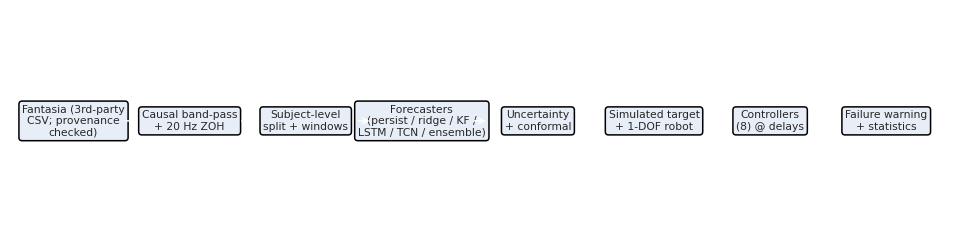

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2170: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  result = self._expression.parseString(s)
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2197: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  return self._math_expression.parseString(toks[0][1:-1], parseAll=True)
/usr/local/lib/python3.13/dist-packages/pyparsing/util.py:466: PyparsingDeprecationWarning: 'parseAll' argument is deprecated, use 'parse_all'
  return fn(self, *args, **kwargs)
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2178: PyparsingDeprecationWarni

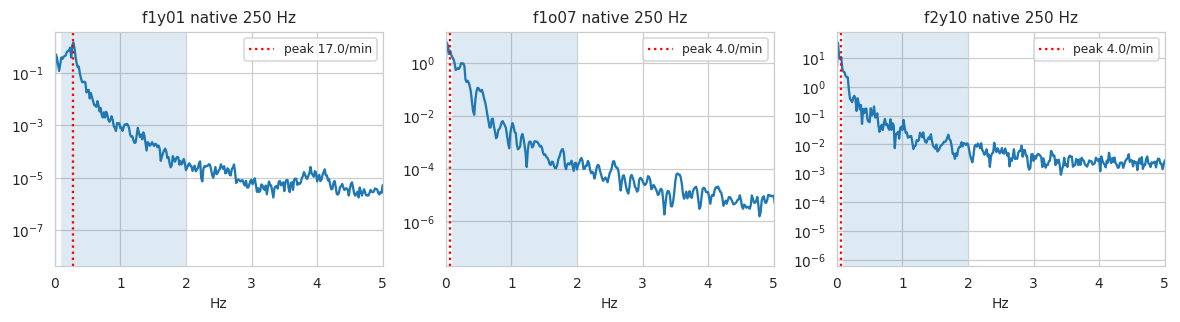

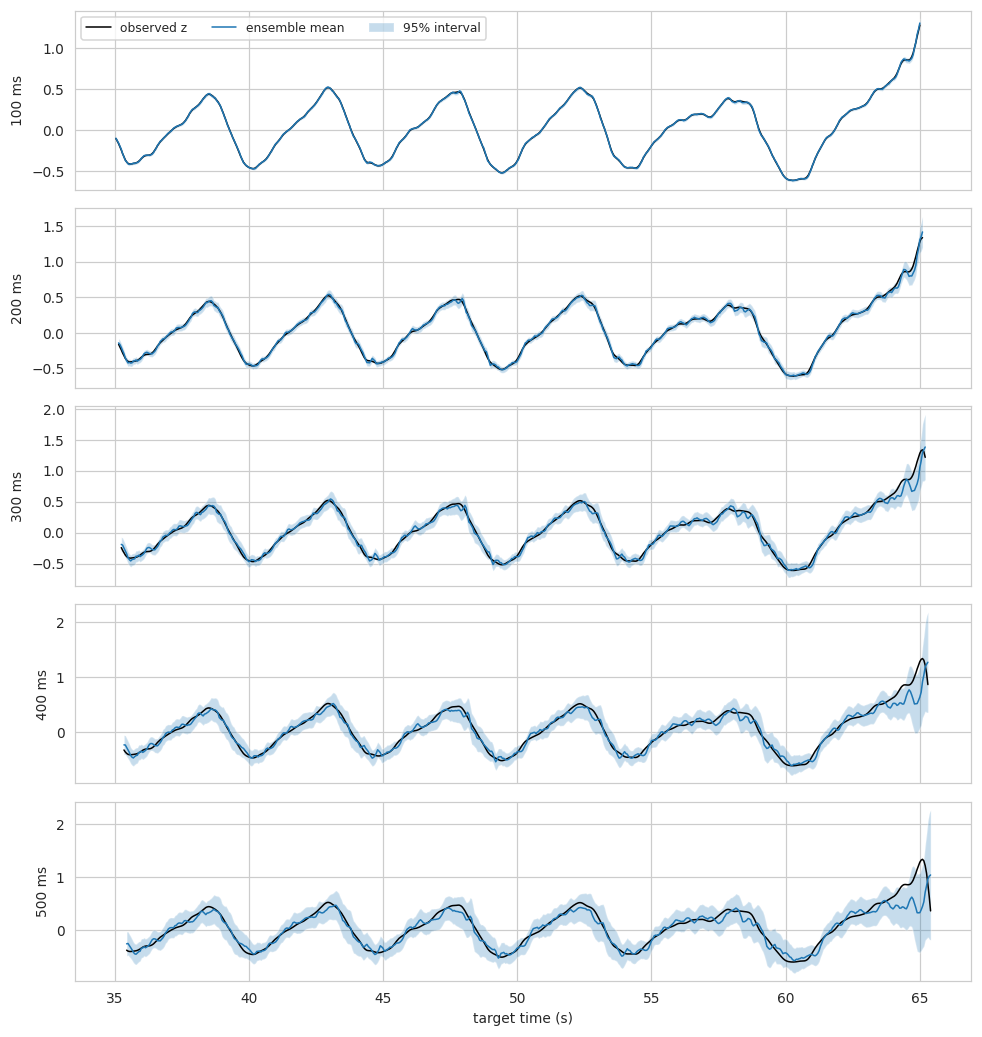

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


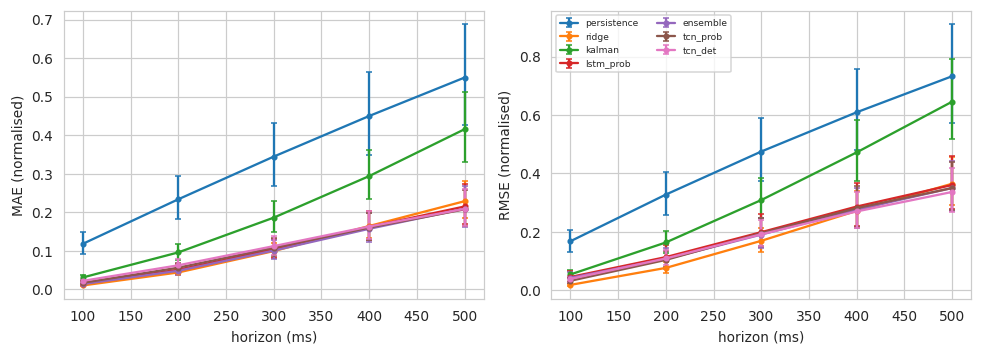

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


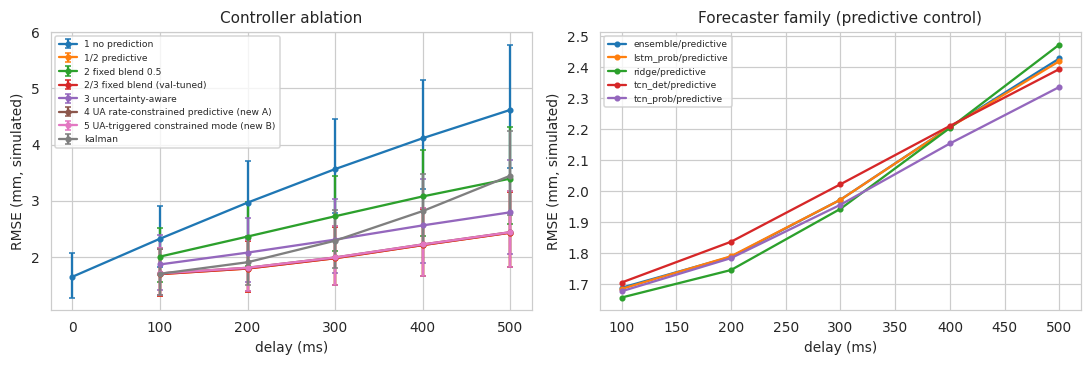

[20:27:17] STATUS figures_tables: RUN


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [32]:
# Fig 1: pipeline (schematic, no numbers)
fig, ax = plt.subplots(figsize=(11, 2.6)); ax.axis("off")
steps = ["Fantasia (3rd-party\nCSV; provenance\nchecked)", "Causal band-pass\n+ 20 Hz ZOH", "Subject-level\nsplit + windows", "Forecasters\n(persist / ridge / KF /\nLSTM / TCN / ensemble)", "Uncertainty\n+ conformal", "Simulated target\n+ 1-DOF robot", "Controllers\n(8) @ delays", "Failure warning\n+ statistics"]
for i, s in enumerate(steps):
    ax.text(i * 1.3, 0.5, s, ha="center", va="center", fontsize=7, bbox=dict(boxstyle="round", fc="#e8eef7", ec="k"))
    if i: ax.annotate("", xy=(i * 1.3 - .55, .5), xytext=((i - 1) * 1.3 + .55, .5), arrowprops=dict(arrowstyle="->"))
ax.set_xlim(-.7, 9.8); ax.set_ylim(0, 1); savefig(fig, "fig01_pipeline", "Overall research pipeline (all robot results are simulations).")
# Fig 4: native-rate spectra (descriptive)
fig, axs = plt.subplots(1, len(EDA_REPS), figsize=(3.6 * len(EDA_REPS), 3), squeeze=False)
for a, r in zip(axs[0], EDA_REPS):
    row = INV[INV.record == r].iloc[0]; fs = float(row["fs"]); n0 = int(row["start_s"] * fs)
    x = native_segment(row, n0, n0 + int(min(300, row["dur_s"]) * fs)).astype(float); x = x[np.isfinite(x)]
    fr, pw = sps.welch(x - x.mean(), fs=fs, nperseg=min(len(x), int(60 * fs))); a.semilogy(fr, pw); a.set(xlim=(0, 5), title=f"{r} native {fs:g} Hz", xlabel="Hz"); a.axvspan(*BAND, alpha=.15)
    pk = fr[(fr > .05) & (fr < 3)][np.argmax(pw[(fr > .05) & (fr < 3)])]; a.axvline(pk, c="r", ls=":", label=f"peak {60*pk:.1f}/min"); a.legend()
fig.tight_layout(); savefig(fig, "fig04_eda_power_spectra", "Welch power spectra at native sampling rate for representative records; shaded = analysis passband (descriptive EDA).")
# Fig 5: forecasts with uncertainty bands
rid = TEST["rec"][0]; mk = np.flatnonzero(TEST["rec"] == rid)[200:200 + 30 * FS_MODEL]
fig, axs = plt.subplots(NH, 1, figsize=(9, 1.9 * NH), sharex=True)
for j, a in enumerate(axs):
    tt = (TEST["loc"][mk] + H_STEPS[j]) / FS_MODEL; mu, sg = PT["ensemble"]["mu"][mk, j], PT["ensemble"]["sigma"][mk, j]
    a.plot(tt, TEST["Y"][mk, j], "k", lw=1, label="observed z"); a.plot(tt, mu, lw=1, label="ensemble mean"); a.fill_between(tt, mu - Z95 * sg, mu + Z95 * sg, alpha=.25, label="95% interval"); a.set_ylabel(f"{H_MS[j]} ms")
axs[0].legend(ncol=3); axs[-1].set_xlabel("target time (s)"); fig.tight_layout(); savefig(fig, "fig05_forecasts_uncertainty", f"Ensemble forecasts with 95% Gaussian intervals at each horizon ({rid}, normalised units).")
# Fig 6: error vs horizon
fig, axs = plt.subplots(1, 2, figsize=(9, 3.3))
for m in MODELS:
    s = FORECAST_TABLE[FORECAST_TABLE.model == m]
    for a, c in zip(axs, ["mae", "rmse"]): a.errorbar(s.horizon_ms, s[c], yerr=[s[c] - s[c + "_lo"], s[c + "_hi"] - s[c]], marker="o", ms=3, capsize=2, label=m)
axs[0].set(ylabel="MAE (normalised)", xlabel="horizon (ms)"); axs[1].set(ylabel="RMSE (normalised)", xlabel="horizon (ms)"); axs[1].legend(fontsize=6, ncol=2); fig.tight_layout()
savefig(fig, "fig06_error_vs_horizon", "Forecast error versus horizon; markers = subject-level mean, bars = 95% bootstrap CI.")
# Fig 15: ablation
fig, axs = plt.subplots(1, 2, figsize=(10, 3.4)); L = ABL_DF[ABL_DF.ablation == "controller_ladder"]
for s, g in L.groupby("setting"): g = g.sort_values("delay_ms"); axs[0].errorbar(g.delay_ms, g.value, yerr=[g.value - g.ci_lo, g.ci_hi - g.value], marker="o", ms=3, capsize=2, label=s)
axs[0].set(xlabel="delay (ms)", ylabel="RMSE (mm, simulated)", title="Controller ablation"); axs[0].legend(fontsize=6)
F_ = ABL_DF[ABL_DF.ablation == "forecaster_family"]
for s, g in F_[F_.setting.str.endswith("predictive")].groupby("setting"): g = g.sort_values("delay_ms"); axs[1].plot(g.delay_ms, g.value, marker="o", ms=3, label=s)
axs[1].set(xlabel="delay (ms)", ylabel="RMSE (mm, simulated)", title="Forecaster family (predictive control)"); axs[1].legend(fontsize=6); fig.tight_layout()
savefig(fig, "fig15_ablation", "Ablations: controller ladder (left) and forecaster family under predictive control (right); SIMULATED tracking.")
# paper tables
save_table(pd.DataFrame([dict(setting="band_Hz", value=str(BAND)), dict(setting="filter", value=f"Butterworth order {FILTER_ORDER} (x2 for bandpass), SOS, causal sosfilt"), dict(setting="fs_model_Hz", value=FS_MODEL),
                         dict(setting="resample", value="zero-order hold (causal)"), dict(setting="max_gap_s", value=MAX_GAP_S), dict(setting="flatline_s", value=FLAT_S), dict(setting="warmup_s", value=WARMUP_S),
                         dict(setting="normalisation", value="train-subject mean/std per fold"), dict(setting="history/horizons", value=f"{HIST} samples / {H_MS} ms")]), "preprocessing_settings", top_level=False)
mark("figures_tables")

# Section R — Reproducibility and artifact export

In [33]:
LIM = f"""# Limitations and assumptions ({DATASET}, run {RUN_NAME}, mode {MODE})
* All robot results are SIMULATIONS driven by a surrogate respiratory waveform; target = A·z is an assumption (A={A0} mm primary), NOT measured organ displacement. No physical-robot or clinical validation.
* Plant: 1-DOF first-order lag (τ={TAU_ACT}s), observation delay D, command delay d_cmd={D_CMD} steps, saturation ±{UMAX_FACTOR}A; inference latency is not added to D.
* Failure threshold ε = {EPS_FRAC:.0%} of A, fixed a priori; alternatives reported as sensitivity.
* Conformal calibration uses chronologically separated validation windows of the validation subjects; temporal dependence and subject shift violate exchangeability, so coverage is measured, not guaranteed.
* Validation records provide both early-stopping (val_sel) and conformal calibration (val_cal) data, separated in time within each record.
* Windows within a subject are strongly dependent; all statistics are at the subject level and sample sizes are small (n subjects reported in tables).
* Window/test evaluation covers only the segments selected for this run (see inventory columns start_s/dur_s and exclusions in record_quality.csv).
* Fantasia contains healthy resting volunteers (young vs. elderly) with long recordings; only a reproducible segment per subject is used (segments are NOT independent subjects).
* Data are a third-party processed Kaggle CSV (not the official PhysioNet files): no headers/units/age metadata and no official checksums; the RESP channel is assumed to be the respiration waveform and is sanity-checked via the spectral respiratory rate. Cohort labels come from participant IDs.
* In this CSV participant f2y02 has Sampling_Rate = 333 (all others 250; its duration is still ~7035 s, so it is treated as genuinely recorded at 333 Hz) and several participants contain short non-finite stretches (gaps <= 0.25 s are forward-filled, longer ones are marked invalid and excluded from windows).
"""
(OUT / "limitations_and_assumptions.md").write_text(LIM); _WRITTEN.add(str(OUT / "limitations_and_assumptions.md"))
save_json(dict(seed=SEED, mode=MODE, env=ENV, cfg=CFG_ALL, status=STATUS, figures=CAPTIONS, folds=[{k: v for k, v in f.items()} for f in FOLDS]), "run_metadata.json")
(OUT / "figures" / "captions.json").write_text(json.dumps(CAPTIONS, indent=2)); _WRITTEN.add(str(OUT / "figures" / "captions.json"))
pd.concat([v["pinfo"].assign(fold=k) for k, v in FIT.items()]).to_csv(OUT / "model_summary.csv", index=False)
print(sorted(p.name for p in OUT.iterdir()))

['ablation_results.csv', 'config.json', 'controller_parameters_validation_selected.json', 'controller_selected_on_validation.csv', 'controller_validation_selection.csv', 'data_provenance.json', 'data_provenance_verification.json', 'dataset_inventory.csv', 'failure_prediction_metrics.csv', 'figures', 'forecast_metrics.csv', 'forecast_selected_model_per_horizon_validation.csv', 'forecast_selected_model_test_results.csv', 'forecast_validation_selection.csv', 'group_sizes.csv', 'inference_latency.csv', 'limitations_and_assumptions.md', 'logs', 'model_summary.csv', 'models', 'record_quality.csv', 'run_metadata.json', 'sensitivity_actuator_tau.csv', 'sensitivity_measurement_noise.csv', 'split_manifest.csv', 'statistical_tests.csv', 'tables', 'tracking_metrics.csv', 'uncertainty_metrics.csv', 'window_metadata_sample.csv']


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


# Section S — Automatic final report
Only values computed in this run are reported; anything not executed is `NOT RUN`.

In [34]:
def best_row(df, by, col, mode="min"):
    return df.loc[getattr(df.groupby(by)[col], "idxmin" if mode == "min" else "idxmax")()]
rep = []
rep.append(f"# Final report — {DATASET} ({MODE} mode, run {RUN_NAME})\n")
rep.append(f"* Subjects analysed: {len(SUBJECTS)}; records analysed: {len(REC)}; test subjects: {len(np.unique(TEST['subj']))}; folds: {len(FOLDS)}.")
rep.append(f"* Exclusions: {len(EXCLUDED)} ({'; '.join(EXCLUDED['record'] + ': ' + EXCLUDED['exclude_reason']) if len(EXCLUDED) else 'none'}). Records not selected by configuration: {len(INV) - int(INV['selected'].sum())}.")
rep.append("\n## Final forecasting model per horizon — SELECTED ON VALIDATION (val_sel MAE), test results of that model\n" + df_to_md(SEL_TEST[["horizon_ms", "model", "val_mae", "n_subjects", "mae", "mae_lo", "mae_hi", "rmse", "rmse_lo", "rmse_hi"]]))
rep.append("\n## All models on the test set (descriptive; NOT used for selection)\n" + df_to_md(FORECAST_TABLE[["model", "horizon_ms", "n_subjects", "mae", "mae_lo", "mae_hi", "rmse"]]))
cal = UNC_TABLE[UNC_TABLE.model.isin(["lstm_prob", "tcn_prob", "ensemble"])].copy(); cal["gauss_gap"] = (cal["picp95"] - 0.95).abs()
cg = cal.groupby("model")["gauss_gap"].mean().sort_values(); rep.append(f"\n## Uncertainty calibration\nMean |PICP95 − 0.95| over horizons (Gaussian intervals): {cg.round(3).to_dict()}. Best-calibrated Gaussian method: **{cg.index[0]}**.")
cf = [c for c in UNC_TABLE.columns if c.startswith("conf_") and c.endswith("_picp") and "_5_" in c]
if cf: rep.append("Conformal 95% empirical coverage (mean over horizons/subjects): " + str(UNC_TABLE.groupby("model")[cf].mean().round(3).to_dict()))
sp = FM[FM.model == "ensemble"]["spearman_sigma_abs_err"]; rep.append(f"Ensemble σ vs |error| Spearman across subject-horizons: mean {sp.mean():.3f} (min {sp.min():.3f}, max {sp.max():.3f}).")
bc = SEL_CTRL.merge(T_SUM[["controller", "delay_ms", "rmse", "rmse_lo", "rmse_hi", "mae", "fail_rate", "cmd_var", "sat_rate", "cons_rate"]], on=["controller", "delay_ms"], how="left"); rep.append("\n## Controller SELECTED ON VALIDATION per delay, with its TEST tracking (SIMULATION, subject-mean, mm)\n" + df_to_md(bc))
_p = T_SUM.pivot(index="delay_ms", columns="controller", values="rmse").drop(index=0, errors="ignore")
for _n in ["uncertainty_aware", "ua_rate", "ua_trigger"]:
    rep.append(f"* TEST mean RMSE of **{_n}** is lower than predictive at {int((_p[_n] < _p['predictive']).sum())}/{len(_p)} delays (point estimates only; see paired subject-level tests below). If this is 0, the candidate LOSES to predictive-only control and that is the finding.")
rep.append("\n## Full test comparison, all controllers (descriptive, not used for selection)\n" + df_to_md(T_SUM[["controller", "delay_ms", "rmse", "rmse_lo", "rmse_hi", "mae", "max_abs", "fail_rate", "cmd_var", "sat_rate", "cons_rate"]]))
primary = STAT[(STAT.family == "primary")][["delay_ms", "b", "n", "mean_diff", "ci_lo", "ci_hi", "p_raw", "p_holm", "effect_rank_biserial"]]; rep.append("\n## Uncertainty-aware blend vs comparators (RMSE difference, negative favours UA)\n" + df_to_md(primary))
newp = STAT[STAT.family == "primary_new"][["delay_ms", "a", "b", "n", "mean_diff", "ci_lo", "ci_hi", "p_raw", "p_holm", "effect_rank_biserial", "cohens_dz"]]
rep.append("\n## NEW constrained candidates vs predictive/reactive (RMSE difference, negative favours the candidate; Holm-corrected within family)\n" + df_to_md(newp))
sig_wins = primary[(primary.p_holm < 0.05) & (primary.mean_diff < 0)]; sig_loss = primary[(primary.p_holm < 0.05) & (primary.mean_diff > 0)]
rep.append(f"Holm-significant improvements of UA: {len(sig_wins)}; Holm-significant degradations: {len(sig_loss)}; total primary comparisons: {len(primary)}. (n subjects = {int(primary.n.max())}; low power if small.)")
gs = STAT[STAT["family"].astype(str).str.startswith("group:") & STAT["b"].isin(["predictive", "fixed_blend"])][["family", "delay_ms", "b", "n", "mean_diff", "ci_lo", "ci_hi", "p_raw", "p_holm"]]
if len(gs): rep.append("\n## Per-group paired comparisons (UA minus comparator, RMSE mm; separate Holm family per group)\n" + df_to_md(gs))
if len(FP) and "auc" in FP:
    fp = FP[(FP.controller == "predictive") & FP.auc.notna()].pivot_table(index="delay_ms", columns="score", values=["auc"]); rep.append("\n## Failure-warning ROC-AUC (predictive controller; pooled windows, subject-bootstrap CI in failure_prediction_metrics.csv)\n" + df_to_md(fp.droplevel(0, axis=1).reset_index()))
    better = (fp.droplevel(0, axis=1)["sigma_total"] > fp.droplevel(0, axis=1)["abs_velocity"]).mean(); rep.append(f"σ_total AUC exceeds |velocity| AUC at {better:.0%} of delays; see paired subject-level tests (family exploratory_auc) before concluding anything.")
_ny = int(GROUPN.query("role=='test' and `group`=='young'").n_subjects.sum()); _ne = int(GROUPN.query("role=='test' and `group`=='elderly'").n_subjects.sum())
rep.append(f"\n## Distribution-shift findings (EXPLORATORY; young n={_ny} vs elderly n={_ne} test subjects; not causal, no significance claim for the small young group)\n" + (df_to_md(SHIFT_TABLE[(SHIFT_TABLE.model == "ensemble") & (SHIFT_TABLE.horizon_ms == H_MS[NH // 2])][["group", "n_subjects", "mae", "mae_lo", "mae_hi", "mean_sigma", "picp95"]]) if STATUS.get("distribution_shift", "").startswith("RUN") else "NOT RUN"))
rep.append("\n## Experiment status\n" + "\n".join(f"* {k}: {v}" for k, v in STATUS.items()))
rep.append("\n## Negative / null results to check\n* Compare UA vs predictive/fixed-blend rows above: if p_holm ≥ 0.05 or the CI spans 0, UA did not demonstrably improve tracking in this run.\n* If σ AUC ≤ velocity AUC, uncertainty was not a better failure warning than a trivial baseline.\n* Coverage gaps (PICP95 − 0.95) quantify miscalibration under shift.")
rep.append("\n## Known limitations\nSee limitations_and_assumptions.md. Simulation only; surrogate waveform; small cohorts; segments selected for compute; no physical validation.")
REPORT = "\n".join(rep); (OUT / "final_report.md").write_text(REPORT); _WRITTEN.add(str(OUT / "final_report.md")); display(Markdown(REPORT))
save_table(pd.DataFrame([dict(experiment=k, status=v) for k, v in STATUS.items()]), "experiment_status", top_level=False)
mark("final_report")

# Final report — Fantasia (full mode, run full_20261010_200436)

* Subjects analysed: 40; records analysed: 40; test subjects: 24; folds: 1.
* Exclusions: 0 (none). Records not selected by configuration: 0.

## Final forecasting model per horizon — SELECTED ON VALIDATION (val_sel MAE), test results of that model
| horizon_ms | model | val_mae | n_subjects | mae | mae_lo | mae_hi | rmse | rmse_lo | rmse_hi |
|---|---|---|---|---|---|---|---|---|---|
| 100 | ridge | 0.01005 | 24 | 0.0105 | 0.008861 | 0.01248 | 0.01821 | 0.01415 | 0.02293 |
| 200 | ridge | 0.04505 | 24 | 0.04421 | 0.03696 | 0.05291 | 0.07636 | 0.05955 | 0.09667 |
| 300 | ensemble | 0.1019 | 24 | 0.1009 | 0.07988 | 0.1271 | 0.1905 | 0.143 | 0.247 |
| 400 | ensemble | 0.1643 | 24 | 0.1574 | 0.1237 | 0.1988 | 0.2758 | 0.2136 | 0.3505 |
| 500 | tcn_prob | 0.2217 | 24 | 0.2078 | 0.1652 | 0.2583 | 0.3498 | 0.2755 | 0.4378 |

## All models on the test set (descriptive; NOT used for selection)
| model | horizon_ms | n_subjects | mae | mae_lo | mae_hi | rmse |
|---|---|---|---|---|---|---|
| ensemble | 100 | 24 | 0.01418 | 0.01037 | 0.01921 | 0.04228 |
| ensemble | 200 | 24 | 0.04853 | 0.03829 | 0.0622 | 0.1065 |
| ensemble | 300 | 24 | 0.1009 | 0.07988 | 0.1271 | 0.1905 |
| ensemble | 400 | 24 | 0.1574 | 0.1237 | 0.1988 | 0.2758 |
| ensemble | 500 | 24 | 0.2094 | 0.1634 | 0.2672 | 0.35 |
| kalman | 100 | 24 | 0.03119 | 0.02541 | 0.0379 | 0.05386 |
| kalman | 200 | 24 | 0.09615 | 0.07771 | 0.1173 | 0.1635 |
| kalman | 300 | 24 | 0.1863 | 0.1494 | 0.2284 | 0.3087 |
| kalman | 400 | 24 | 0.2941 | 0.2346 | 0.3611 | 0.472 |
| kalman | 500 | 24 | 0.4157 | 0.3299 | 0.5127 | 0.6455 |
| lstm_prob | 100 | 24 | 0.01552 | 0.01137 | 0.021 | 0.04518 |
| lstm_prob | 200 | 24 | 0.05135 | 0.04013 | 0.06613 | 0.1133 |
| lstm_prob | 300 | 24 | 0.1044 | 0.08259 | 0.1316 | 0.1987 |
| lstm_prob | 400 | 24 | 0.1624 | 0.1277 | 0.2045 | 0.2865 |
| lstm_prob | 500 | 24 | 0.2153 | 0.1687 | 0.2736 | 0.3602 |
| persistence | 100 | 24 | 0.1184 | 0.09226 | 0.1483 | 0.1675 |
| persistence | 200 | 24 | 0.2339 | 0.1823 | 0.2931 | 0.3273 |
| persistence | 300 | 24 | 0.3446 | 0.2684 | 0.4319 | 0.4748 |
| persistence | 400 | 24 | 0.4499 | 0.3498 | 0.564 | 0.6092 |
| persistence | 500 | 24 | 0.5496 | 0.4269 | 0.6889 | 0.7327 |
| ridge | 100 | 24 | 0.0105 | 0.008861 | 0.01248 | 0.01821 |
| ridge | 200 | 24 | 0.04421 | 0.03696 | 0.05291 | 0.07636 |
| ridge | 300 | 24 | 0.09955 | 0.08207 | 0.1197 | 0.1691 |
| ridge | 400 | 24 | 0.1646 | 0.1346 | 0.1993 | 0.2717 |
| ridge | 500 | 24 | 0.229 | 0.1849 | 0.2803 | 0.3646 |
| tcn_det | 100 | 24 | 0.02232 | 0.01791 | 0.02787 | 0.03864 |
| tcn_det | 200 | 24 | 0.06272 | 0.05046 | 0.07792 | 0.1087 |
| tcn_det | 300 | 24 | 0.1125 | 0.09011 | 0.1396 | 0.1916 |
| tcn_det | 400 | 24 | 0.1633 | 0.1304 | 0.2039 | 0.2697 |
| tcn_det | 500 | 24 | 0.209 | 0.1654 | 0.2615 | 0.3364 |
| tcn_prob | 100 | 24 | 0.0174 | 0.0144 | 0.02125 | 0.03225 |
| tcn_prob | 200 | 24 | 0.05655 | 0.04632 | 0.06924 | 0.1037 |
| tcn_prob | 300 | 24 | 0.1082 | 0.08756 | 0.133 | 0.1952 |
| tcn_prob | 400 | 24 | 0.1606 | 0.1286 | 0.1985 | 0.281 |
| tcn_prob | 500 | 24 | 0.2078 | 0.1652 | 0.2583 | 0.3498 |

## Uncertainty calibration
Mean |PICP95 − 0.95| over horizons (Gaussian intervals): {'lstm_prob': 0.005, 'tcn_prob': 0.007, 'ensemble': 0.008}. Best-calibrated Gaussian method: **lstm_prob**.
Conformal 95% empirical coverage (mean over horizons/subjects): {'conf_abs_5_picp': {'ensemble': 0.958, 'lstm_prob': 0.959, 'persistence': 0.961, 'ridge': 0.957, 'tcn_prob': 0.96}, 'conf_norm_5_picp': {'ensemble': 0.951, 'lstm_prob': 0.951, 'persistence': nan, 'ridge': nan, 'tcn_prob': 0.95}}
Ensemble σ vs |error| Spearman across subject-horizons: mean 0.351 (min 0.166, max 0.545).

## Controller SELECTED ON VALIDATION per delay, with its TEST tracking (SIMULATION, subject-mean, mm)
| controller | delay_ms | val_rmse | val_mae | rmse | rmse_lo | rmse_hi | mae | fail_rate | cmd_var | sat_rate | cons_rate |
|---|---|---|---|---|---|---|---|---|---|---|---|
| reactive | 0 | 2.109 | 1.597 | 1.642 | 1.272 | 2.071 | 1.214 | 0.4075 | 0.2969 | 0.001777 | nan |
| predictive | 100 | 2.144 | 1.611 | 1.689 | 1.303 | 2.137 | 1.232 | 0.4091 | 0.3081 | 0.001806 | nan |
| fixed_blend | 200 | 2.23 | 1.652 | 1.789 | 1.371 | 2.271 | 1.275 | 0.4142 | 0.3461 | 0.001653 | nan |
| predictive | 300 | 2.41 | 1.738 | 1.973 | 1.496 | 2.53 | 1.364 | 0.4255 | 0.3835 | 0.001488 | nan |
| fixed_blend | 400 | 2.656 | 1.867 | 2.207 | 1.657 | 2.85 | 1.493 | 0.4439 | 0.3985 | 0.001315 | nan |
| predictive | 500 | 2.901 | 1.998 | 2.428 | 1.81 | 3.148 | 1.626 | 0.4631 | 0.3977 | 0.001142 | nan |
* TEST mean RMSE of **uncertainty_aware** is lower than predictive at 0/5 delays (point estimates only; see paired subject-level tests below). If this is 0, the candidate LOSES to predictive-only control and that is the finding.
* TEST mean RMSE of **ua_rate** is lower than predictive at 0/5 delays (point estimates only; see paired subject-level tests below). If this is 0, the candidate LOSES to predictive-only control and that is the finding.
* TEST mean RMSE of **ua_trigger** is lower than predictive at 0/5 delays (point estimates only; see paired subject-level tests below). If this is 0, the candidate LOSES to predictive-only control and that is the finding.

## Full test comparison, all controllers (descriptive, not used for selection)
| controller | delay_ms | rmse | rmse_lo | rmse_hi | mae | max_abs | fail_rate | cmd_var | sat_rate | cons_rate |
|---|---|---|---|---|---|---|---|---|---|---|
| fixed_blend | 100 | 1.689 | 1.303 | 2.137 | 1.232 | 20.16 | 0.4091 | 0.3081 | 0.001806 | nan |
| fixed_blend | 200 | 1.789 | 1.371 | 2.271 | 1.275 | 22.94 | 0.4142 | 0.3461 | 0.001653 | nan |
| fixed_blend | 300 | 1.973 | 1.496 | 2.53 | 1.364 | 25.81 | 0.4255 | 0.3835 | 0.001488 | nan |
| fixed_blend | 400 | 2.207 | 1.657 | 2.85 | 1.493 | 27.95 | 0.4439 | 0.3985 | 0.001315 | nan |
| fixed_blend | 500 | 2.428 | 1.81 | 3.148 | 1.626 | 28.78 | 0.4631 | 0.3977 | 0.001142 | nan |
| fixed_blend_0.5 | 100 | 2.002 | 1.553 | 2.521 | 1.484 | 21.74 | 0.4857 | 0.2975 | 0.001784 | nan |
| fixed_blend_0.5 | 200 | 2.359 | 1.829 | 2.97 | 1.751 | 25.06 | 0.5458 | 0.3024 | 0.001682 | nan |
| fixed_blend_0.5 | 300 | 2.722 | 2.104 | 3.435 | 2.018 | 27.77 | 0.5911 | 0.3067 | 0.001574 | nan |
| fixed_blend_0.5 | 400 | 3.075 | 2.363 | 3.898 | 2.281 | 29.69 | 0.6273 | 0.3034 | 0.001449 | nan |
| fixed_blend_0.5 | 500 | 3.393 | 2.59 | 4.322 | 2.522 | 30.72 | 0.656 | 0.2933 | 0.001364 | nan |
| kalman | 100 | 1.695 | 1.318 | 2.131 | 1.241 | 19.41 | 0.4134 | 0.3206 | 0.001923 | nan |
| kalman | 200 | 1.901 | 1.493 | 2.37 | 1.361 | 22.85 | 0.4395 | 0.3724 | 0.002377 | nan |
| kalman | 300 | 2.286 | 1.797 | 2.831 | 1.622 | 26.65 | 0.4982 | 0.4467 | 0.003154 | nan |
| kalman | 400 | 2.814 | 2.228 | 3.473 | 2.028 | 29.94 | 0.5793 | 0.5345 | 0.004616 | nan |
| kalman | 500 | 3.444 | 2.736 | 4.241 | 2.541 | 32.37 | 0.6575 | 0.63 | 0.006792 | nan |
| predictive | 100 | 1.689 | 1.303 | 2.137 | 1.232 | 20.16 | 0.4091 | 0.3081 | 0.001806 | nan |
| predictive | 200 | 1.789 | 1.371 | 2.271 | 1.275 | 22.94 | 0.4142 | 0.3461 | 0.001653 | nan |
| predictive | 300 | 1.973 | 1.496 | 2.53 | 1.364 | 25.81 | 0.4255 | 0.3835 | 0.001488 | nan |
| predictive | 400 | 2.207 | 1.657 | 2.85 | 1.493 | 27.95 | 0.4439 | 0.3985 | 0.001315 | nan |
| predictive | 500 | 2.428 | 1.81 | 3.148 | 1.626 | 28.78 | 0.4631 | 0.3977 | 0.001142 | nan |
| reactive | 0 | 1.642 | 1.272 | 2.071 | 1.214 | 18.2 | 0.4075 | 0.2969 | 0.001777 | nan |
| reactive | 100 | 2.321 | 1.812 | 2.904 | 1.737 | 23.48 | 0.5466 | 0.2969 | 0.001777 | nan |
| reactive | 200 | 2.965 | 2.315 | 3.703 | 2.241 | 27.8 | 0.6335 | 0.2969 | 0.001777 | nan |
| reactive | 300 | 3.562 | 2.778 | 4.452 | 2.718 | 30.51 | 0.6937 | 0.2969 | 0.001777 | nan |
| reactive | 400 | 4.113 | 3.201 | 5.145 | 3.168 | 32.56 | 0.7378 | 0.2969 | 0.001777 | nan |
| reactive | 500 | 4.618 | 3.585 | 5.784 | 3.587 | 34.39 | 0.7703 | 0.2969 | 0.001777 | nan |
| ua_rate | 100 | 1.702 | 1.313 | 2.151 | 1.233 | 21.52 | 0.4091 | 0.3075 | 0.001775 | 0.0004598 |
| ua_rate | 200 | 1.803 | 1.379 | 2.29 | 1.278 | 23.55 | 0.4142 | 0.3449 | 0.001588 | 0.001172 |
| ua_rate | 300 | 1.986 | 1.503 | 2.552 | 1.368 | 25.91 | 0.4256 | 0.3815 | 0.001396 | 0.001841 |
| ua_rate | 400 | 2.218 | 1.663 | 2.869 | 1.497 | 27.73 | 0.444 | 0.396 | 0.001203 | 0.002142 |
| ua_rate | 500 | 2.437 | 1.814 | 3.165 | 1.63 | 28.62 | 0.4631 | 0.3953 | 0.001043 | 0.002075 |
| ua_trigger | 100 | 1.702 | 1.313 | 2.151 | 1.233 | 21.52 | 0.4091 | 0.3075 | 0.001775 | 0 |
| ua_trigger | 200 | 1.803 | 1.379 | 2.29 | 1.278 | 23.55 | 0.4142 | 0.3449 | 0.001588 | 0 |
| ua_trigger | 300 | 1.986 | 1.503 | 2.552 | 1.368 | 25.91 | 0.4256 | 0.3815 | 0.001396 | 0 |
| ua_trigger | 400 | 2.218 | 1.663 | 2.869 | 1.497 | 27.73 | 0.444 | 0.396 | 0.001203 | 0 |
| ua_trigger | 500 | 2.437 | 1.814 | 3.165 | 1.63 | 28.62 | 0.4631 | 0.3953 | 0.001043 | 0 |
| uncertainty_aware | 100 | 1.862 | 1.414 | 2.39 | 1.336 | 22.62 | 0.4287 | 0.3022 | 0.001777 | nan |
| uncertainty_aware | 200 | 2.073 | 1.549 | 2.69 | 1.454 | 25.59 | 0.4483 | 0.3247 | 0.001741 | nan |
| uncertainty_aware | 300 | 2.305 | 1.713 | 3.022 | 1.589 | 27.48 | 0.4673 | 0.3485 | 0.00167 | nan |
| uncertainty_aware | 400 | 2.558 | 1.885 | 3.384 | 1.743 | 29.16 | 0.4874 | 0.3576 | 0.001582 | nan |
| uncertainty_aware | 500 | 2.792 | 2.042 | 3.717 | 1.891 | 30.19 | 0.5056 | 0.3552 | 0.001484 | nan |

## Uncertainty-aware blend vs comparators (RMSE difference, negative favours UA)
| delay_ms | b | n | mean_diff | ci_lo | ci_hi | p_raw | p_holm | effect_rank_biserial |
|---|---|---|---|---|---|---|---|---|
| 100 | reactive | 24 | -0.4585 | -0.5297 | -0.3824 | 1.192e-07 | 2.98e-06 | -1 |
| 100 | predictive | 24 | 0.173 | 0.1089 | 0.257 | 1.192e-07 | 2.98e-06 | 1 |
| 100 | fixed_blend | 24 | 0.173 | 0.1089 | 0.257 | 1.192e-07 | 2.98e-06 | 1 |
| 100 | fixed_blend_0.5 | 24 | -0.1397 | -0.1736 | -0.1084 | 2.384e-07 | 2.98e-06 | -0.9933 |
| 100 | kalman | 24 | 0.1675 | 0.09522 | 0.2679 | 1.192e-07 | 2.98e-06 | 1 |
| 200 | reactive | 24 | -0.8917 | -1.038 | -0.7378 | 1.192e-07 | 2.98e-06 | -1 |
| 200 | predictive | 24 | 0.284 | 0.179 | 0.4249 | 1.192e-07 | 2.98e-06 | 1 |
| 200 | fixed_blend | 24 | 0.284 | 0.179 | 0.4249 | 1.192e-07 | 2.98e-06 | 1 |
| 200 | fixed_blend_0.5 | 24 | -0.2864 | -0.3445 | -0.2372 | 1.192e-07 | 2.98e-06 | -1 |
| 200 | kalman | 24 | 0.1716 | 0.06054 | 0.3251 | 0.01641 | 0.03281 | 0.5533 |
| 300 | reactive | 24 | -1.258 | -1.47 | -1.035 | 1.192e-07 | 2.98e-06 | -1 |
| 300 | predictive | 24 | 0.3317 | 0.2073 | 0.4942 | 1.192e-07 | 2.98e-06 | 1 |
| 300 | fixed_blend | 24 | 0.3317 | 0.2073 | 0.4942 | 1.192e-07 | 2.98e-06 | 1 |
| 300 | fixed_blend_0.5 | 24 | -0.4167 | -0.4943 | -0.3505 | 1.192e-07 | 2.98e-06 | -1 |
| 300 | kalman | 24 | 0.01901 | -0.1074 | 0.1996 | 0.2182 | 0.2182 | -0.2933 |
| 400 | reactive | 24 | -1.555 | -1.823 | -1.284 | 1.192e-07 | 2.98e-06 | -1 |
| 400 | predictive | 24 | 0.3511 | 0.2169 | 0.5197 | 1.192e-07 | 2.98e-06 | 1 |
| 400 | fixed_blend | 24 | 0.3511 | 0.2169 | 0.5197 | 1.192e-07 | 2.98e-06 | 1 |
| 400 | fixed_blend_0.5 | 24 | -0.5166 | -0.6104 | -0.4334 | 1.192e-07 | 2.98e-06 | -1 |
| 400 | kalman | 24 | -0.2556 | -0.4024 | -0.06117 | 0.002001 | 0.006003 | -0.6933 |
| 500 | reactive | 24 | -1.827 | -2.144 | -1.511 | 1.192e-07 | 2.98e-06 | -1 |
| 500 | predictive | 24 | 0.3635 | 0.2228 | 0.5426 | 2.384e-07 | 2.98e-06 | 0.9933 |
| 500 | fixed_blend | 24 | 0.3635 | 0.2228 | 0.5426 | 2.384e-07 | 2.98e-06 | 0.9933 |
| 500 | fixed_blend_0.5 | 24 | -0.6009 | -0.7095 | -0.5015 | 1.192e-07 | 2.98e-06 | -1 |
| 500 | kalman | 24 | -0.6528 | -0.8425 | -0.4581 | 3.016e-05 | 0.0001206 | -0.88 |

## NEW constrained candidates vs predictive/reactive (RMSE difference, negative favours the candidate; Holm-corrected within family)
| delay_ms | a | b | n | mean_diff | ci_lo | ci_hi | p_raw | p_holm | effect_rank_biserial | cohens_dz |
|---|---|---|---|---|---|---|---|---|---|---|
| 100 | ua_rate | predictive | 24 | 0.01223 | 0.002835 | 0.02507 | 1.633e-05 | 0.0001633 | 0.9 | 0.4444 |
| 100 | ua_rate | reactive | 24 | -0.6192 | -0.7623 | -0.4926 | 1.192e-07 | 3.576e-06 | -1 | -1.802 |
| 100 | ua_trigger | predictive | 24 | 0.01223 | 0.002835 | 0.02507 | 1.633e-05 | 0.0001633 | 0.9 | 0.4444 |
| 100 | ua_trigger | reactive | 24 | -0.6192 | -0.7623 | -0.4926 | 1.192e-07 | 3.576e-06 | -1 | -1.802 |
| 100 | uncertainty_aware | predictive | 24 | 0.173 | 0.1089 | 0.257 | 1.192e-07 | 3.576e-06 | 1 | 0.9096 |
| 100 | uncertainty_aware | reactive | 24 | -0.4585 | -0.5297 | -0.3824 | 1.192e-07 | 3.576e-06 | -1 | -2.388 |
| 200 | ua_rate | predictive | 24 | 0.01375 | 0.003919 | 0.02746 | 0.0008463 | 0.005078 | 0.74 | 0.4514 |
| 200 | ua_rate | reactive | 24 | -1.162 | -1.425 | -0.9278 | 1.192e-07 | 3.576e-06 | -1 | -1.819 |
| 200 | ua_trigger | predictive | 24 | 0.01375 | 0.003919 | 0.02746 | 0.0008463 | 0.005078 | 0.74 | 0.4514 |
| 200 | ua_trigger | reactive | 24 | -1.162 | -1.425 | -0.9278 | 1.192e-07 | 3.576e-06 | -1 | -1.819 |
| 200 | uncertainty_aware | predictive | 24 | 0.284 | 0.179 | 0.4249 | 1.192e-07 | 3.576e-06 | 1 | 0.9125 |
| 200 | uncertainty_aware | reactive | 24 | -0.8917 | -1.038 | -0.7378 | 1.192e-07 | 3.576e-06 | -1 | -2.284 |
| 300 | ua_rate | predictive | 24 | 0.01323 | 0.002156 | 0.02696 | 0.0001496 | 0.001197 | 0.82 | 0.4115 |
| 300 | ua_rate | reactive | 24 | -1.576 | -1.936 | -1.264 | 1.192e-07 | 3.576e-06 | -1 | -1.838 |
| 300 | ua_trigger | predictive | 24 | 0.01323 | 0.002156 | 0.02696 | 0.0001496 | 0.001197 | 0.82 | 0.4115 |
| 300 | ua_trigger | reactive | 24 | -1.576 | -1.936 | -1.264 | 1.192e-07 | 3.576e-06 | -1 | -1.838 |
| 300 | uncertainty_aware | predictive | 24 | 0.3317 | 0.2073 | 0.4942 | 1.192e-07 | 3.576e-06 | 1 | 0.9151 |
| 300 | uncertainty_aware | reactive | 24 | -1.258 | -1.47 | -1.035 | 1.192e-07 | 3.576e-06 | -1 | -2.224 |
| 400 | ua_rate | predictive | 24 | 0.01108 | 0.0004485 | 0.02365 | 0.00158 | 0.005078 | 0.7067 | 0.3873 |
| 400 | ua_rate | reactive | 24 | -1.895 | -2.309 | -1.524 | 1.192e-07 | 3.576e-06 | -1 | -1.859 |
| 400 | ua_trigger | predictive | 24 | 0.01108 | 0.0004485 | 0.02365 | 0.00158 | 0.005078 | 0.7067 | 0.3873 |
| 400 | ua_trigger | reactive | 24 | -1.895 | -2.309 | -1.524 | 1.192e-07 | 3.576e-06 | -1 | -1.859 |
| 400 | uncertainty_aware | predictive | 24 | 0.3511 | 0.2169 | 0.5197 | 1.192e-07 | 3.576e-06 | 1 | 0.9117 |
| 400 | uncertainty_aware | reactive | 24 | -1.555 | -1.823 | -1.284 | 1.192e-07 | 3.576e-06 | -1 | -2.209 |
| 500 | ua_rate | predictive | 24 | 0.008822 | 0.0008357 | 0.01882 | 0.001238 | 0.005078 | 0.72 | 0.387 |
| 500 | ua_rate | reactive | 24 | -2.181 | -2.648 | -1.753 | 1.192e-07 | 3.576e-06 | -1 | -1.854 |
| 500 | ua_trigger | predictive | 24 | 0.008822 | 0.0008357 | 0.01882 | 0.001238 | 0.005078 | 0.72 | 0.387 |
| 500 | ua_trigger | reactive | 24 | -2.181 | -2.648 | -1.753 | 1.192e-07 | 3.576e-06 | -1 | -1.854 |
| 500 | uncertainty_aware | predictive | 24 | 0.3635 | 0.2228 | 0.5426 | 2.384e-07 | 3.576e-06 | 0.9933 | 0.8821 |
| 500 | uncertainty_aware | reactive | 24 | -1.827 | -2.144 | -1.511 | 1.192e-07 | 3.576e-06 | -1 | -2.195 |
Holm-significant improvements of UA: 12; Holm-significant degradations: 12; total primary comparisons: 25. (n subjects = 24; low power if small.)

## Per-group paired comparisons (UA minus comparator, RMSE mm; separate Holm family per group)
| family | delay_ms | b | n | mean_diff | ci_lo | ci_hi | p_raw | p_holm |
|---|---|---|---|---|---|---|---|---|
| group:in_dist_young_test | 100 | predictive | 4 | 0.2065 | 0.0836 | 0.4027 | nan | nan |
| group:in_dist_young_test | 100 | fixed_blend | 4 | 0.2065 | 0.0836 | 0.4027 | nan | nan |
| group:in_dist_young_test | 100 | predictive | 4 | 0.0444 | 0.0005386 | 0.08838 | nan | nan |
| group:in_dist_young_test | 100 | predictive | 4 | 0.0444 | 0.0005386 | 0.08838 | nan | nan |
| group:in_dist_young_test | 200 | predictive | 4 | 0.3447 | 0.1185 | 0.6852 | nan | nan |
| group:in_dist_young_test | 200 | fixed_blend | 4 | 0.3447 | 0.1185 | 0.6852 | nan | nan |
| group:in_dist_young_test | 200 | predictive | 4 | 0.03231 | -0.003636 | 0.09711 | nan | nan |
| group:in_dist_young_test | 200 | predictive | 4 | 0.03231 | -0.003636 | 0.09711 | nan | nan |
| group:in_dist_young_test | 300 | predictive | 4 | 0.3997 | 0.1173 | 0.7987 | nan | nan |
| group:in_dist_young_test | 300 | fixed_blend | 4 | 0.3997 | 0.1173 | 0.7987 | nan | nan |
| group:in_dist_young_test | 300 | predictive | 4 | 0.02272 | -0.03336 | 0.09586 | nan | nan |
| group:in_dist_young_test | 300 | predictive | 4 | 0.02272 | -0.03336 | 0.09586 | nan | nan |
| group:in_dist_young_test | 400 | predictive | 4 | 0.4171 | 0.102 | 0.8377 | nan | nan |
| group:in_dist_young_test | 400 | fixed_blend | 4 | 0.4171 | 0.102 | 0.8377 | nan | nan |
| group:in_dist_young_test | 400 | predictive | 4 | 0.01686 | -0.03571 | 0.08013 | nan | nan |
| group:in_dist_young_test | 400 | predictive | 4 | 0.01686 | -0.03571 | 0.08013 | nan | nan |
| group:in_dist_young_test | 500 | predictive | 4 | 0.4142 | 0.06385 | 0.8578 | nan | nan |
| group:in_dist_young_test | 500 | fixed_blend | 4 | 0.4142 | 0.06385 | 0.8578 | nan | nan |
| group:in_dist_young_test | 500 | predictive | 4 | 0.01536 | -0.02511 | 0.06445 | nan | nan |
| group:in_dist_young_test | 500 | predictive | 4 | 0.01536 | -0.02511 | 0.06445 | nan | nan |
| group:shift_elderly_frozen | 100 | predictive | 20 | 0.1663 | 0.09794 | 0.2648 | 1.907e-06 | 5.722e-05 |
| group:shift_elderly_frozen | 100 | fixed_blend | 20 | 0.1663 | 0.09794 | 0.2648 | 1.907e-06 | 5.722e-05 |
| group:shift_elderly_frozen | 100 | predictive | 20 | 0.005796 | 0.0005203 | 0.01352 | 4.768e-05 | 0.0005722 |
| group:shift_elderly_frozen | 100 | predictive | 20 | 0.005796 | 0.0005203 | 0.01352 | 4.768e-05 | 0.0005722 |
| group:shift_elderly_frozen | 200 | predictive | 20 | 0.2719 | 0.161 | 0.4308 | 1.907e-06 | 5.722e-05 |
| group:shift_elderly_frozen | 200 | fixed_blend | 20 | 0.2719 | 0.161 | 0.4308 | 1.907e-06 | 5.722e-05 |
| group:shift_elderly_frozen | 200 | predictive | 20 | 0.01004 | 0.002802 | 0.01944 | 0.001017 | 0.006369 |
| group:shift_elderly_frozen | 200 | predictive | 20 | 0.01004 | 0.002802 | 0.01944 | 0.001017 | 0.006369 |
| group:shift_elderly_frozen | 300 | predictive | 20 | 0.3181 | 0.1882 | 0.5025 | 1.907e-06 | 5.722e-05 |
| group:shift_elderly_frozen | 300 | fixed_blend | 20 | 0.3181 | 0.1882 | 0.5025 | 1.907e-06 | 5.722e-05 |
| group:shift_elderly_frozen | 300 | predictive | 20 | 0.01133 | 0.003991 | 0.02053 | 2.67e-05 | 0.0003738 |
| group:shift_elderly_frozen | 300 | predictive | 20 | 0.01133 | 0.003991 | 0.02053 | 2.67e-05 | 0.0003738 |
| group:shift_elderly_frozen | 400 | predictive | 20 | 0.3378 | 0.2002 | 0.5393 | 1.907e-06 | 5.722e-05 |
| group:shift_elderly_frozen | 400 | fixed_blend | 20 | 0.3378 | 0.2002 | 0.5393 | 1.907e-06 | 5.722e-05 |
| group:shift_elderly_frozen | 400 | predictive | 20 | 0.00992 | 0.003463 | 0.01857 | 0.001017 | 0.006369 |
| group:shift_elderly_frozen | 400 | predictive | 20 | 0.00992 | 0.003463 | 0.01857 | 0.001017 | 0.006369 |
| group:shift_elderly_frozen | 500 | predictive | 20 | 0.3533 | 0.2052 | 0.5664 | 1.907e-06 | 5.722e-05 |
| group:shift_elderly_frozen | 500 | fixed_blend | 20 | 0.3533 | 0.2052 | 0.5664 | 1.907e-06 | 5.722e-05 |
| group:shift_elderly_frozen | 500 | predictive | 20 | 0.007514 | 0.002422 | 0.01483 | 0.0007076 | 0.006369 |
| group:shift_elderly_frozen | 500 | predictive | 20 | 0.007514 | 0.002422 | 0.01483 | 0.0007076 | 0.006369 |

## Failure-warning ROC-AUC (predictive controller; pooled windows, subject-bootstrap CI in failure_prediction_metrics.csv)
| delay_ms | abs_velocity | forecast_magnitude | last_forecast_error | sigma_aleatoric | sigma_epistemic | sigma_total | vel_plus_sigma |
|---|---|---|---|---|---|---|---|
| 100 | 0.975 | 0.9331 | 0.6321 | 0.7394 | 0.693 | 0.742 | 0.9756 |
| 200 | 0.9491 | 0.9474 | 0.6534 | 0.7275 | 0.6966 | 0.7296 | 0.9509 |
| 300 | 0.8629 | 0.8993 | 0.6735 | 0.7274 | 0.7021 | 0.7281 | 0.877 |
| 400 | 0.7791 | 0.8402 | 0.6741 | 0.7318 | 0.6964 | 0.7321 | 0.8168 |
| 500 | 0.7123 | 0.7878 | 0.6538 | 0.7358 | 0.6929 | 0.7362 | 0.7756 |
σ_total AUC exceeds |velocity| AUC at 20% of delays; see paired subject-level tests (family exploratory_auc) before concluding anything.

## Distribution-shift findings (EXPLORATORY; young n=4 vs elderly n=20 test subjects; not causal, no significance claim for the small young group)
| group | n_subjects | mae | mae_lo | mae_hi | mean_sigma | picp95 |
|---|---|---|---|---|---|---|
| in_dist_young_test | 4 | 0.129 | 0.09358 | 0.1954 | 0.1763 | 0.9506 |
| shift_elderly_frozen | 20 | 0.09526 | 0.07237 | 0.1246 | 0.1343 | 0.9543 |

## Experiment status
* dataset_inventory: RUN
* provenance_verification: RUN
* unit_tests_preprocessing: RUN
* forecasting_models: RUN
* forecast_evaluation: RUN
* validation_model_selection: RUN
* uncertainty_calibration: RUN
* distribution_shift: RUN
* synthetic_target: RUN
* robot_sinusoid_validation: RUN
* controllers_primary: RUN
* tracking_metrics: RUN
* failure_prediction: RUN
* failure_curves: RUN
* statistics: RUN
* ablation: RUN
* sensitivity_actuator_tau: RUN
* sensitivity_measurement_noise: RUN
* figures_tables: RUN

## Negative / null results to check
* Compare UA vs predictive/fixed-blend rows above: if p_holm ≥ 0.05 or the CI spans 0, UA did not demonstrably improve tracking in this run.
* If σ AUC ≤ velocity AUC, uncertainty was not a better failure warning than a trivial baseline.
* Coverage gaps (PICP95 − 0.95) quantify miscalibration under shift.

## Known limitations
See limitations_and_assumptions.md. Simulation only; surrogate waveform; small cohorts; segments selected for compute; no physical validation.

[20:27:18] STATUS final_report: RUN


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
